# Лабораторная работа 2. Классификация. Нейронные сети

## Введение

### Цели и задачи

Цель работы: изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard. 

Постановка задачи:

1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:

    a. Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);

    b. Деревья решений (Decision Tree);

    c. Линейный дискриминантный анализ (Linear Discriminant Analysis);

    d. Метод опорных векторов (Support Vector Machines);

    e. Метод ближайших соседей (k-Nearest Neighbors);

2. Затем сравните качество работы классификаторов с помощью следующих метрик:

    a. Accuracy (точность),

    b. Precision (доля правильно классифицированных положительных примеров),

    c. Recall (чувствительность, доля верно найденных положительных примеров),

    d. F1-Score (среднее гармоническое precision и recall),

    e. Площадь под кривой ROC (AUC-ROC).

3. Настройте гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.

4. Реализуйте и протестируйте нейронную сеть на TensorFlow, исследуйте эффект настройки гиперпараметров и визуализируйте процесс обучения с помощью инструмента TensorBoard.

## Выбор и подготовка датасета

### Информация о выбранном датасете

В работе используется датасет Indian Liver Patient Dataset. Это реальные клинические данные 583 пациентов из северо-восточной части штата Андхра-Прадеш (Индия) - результаты лабораторных анализов крови. По результатам анализов крови определить, есть ли у пациента заболевание печени. 



1. `Age` - возраст пациента, лет  
2. `Gender` - пол пациента (Male/Female)   
3. `Total_Bilirubin` - общий билирубин, мг/дл   
4. `Direct_Bilirubin` - прямой (связанный) билирубин, мг/дл   
5. `Alkaline_Phosphotase` - щелочная фосфатаза, ед/л  
6. `Alamine_Aminotransferase` - аланинаминотрансфераза (АЛТ), ед/л  
7. `Aspartate_Aminotransferase` - аспартатаминотрансфераза (АСТ), ед/л   
8. `Total_Protiens` - общий белок, г/дл   
9. `Albumin` - альбумин, г/дл   
10. `Albumin_and_Globulin_Ratio` - отношение альбумина к глобулину   
11. `Dataset` - **целевая переменная**: `1` - заболевание печени, `2` - нет заболевания    
Итого: 10 признаков (9 числовых + пол) и 1 целевая переменная, 583 объекта.

### Импорт библиотек

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image

from IPython.display import display
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
)

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    balanced_accuracy_score
    
)

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

### Загрузка и первичный осмотр данных

In [35]:
df = pd.read_csv('indian_liver_patient.csv')
print('Размер таблицы (строк, столбцов):', df.shape)
df.head(10)

Размер таблицы (строк, столбцов): (583, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
5,46,Male,1.8,0.7,208,19,14,7.6,4.4,1.30,1
6,26,Female,0.9,0.2,154,16,12,7.0,3.5,1.00,1
7,29,Female,0.9,0.3,202,14,11,6.7,3.6,1.10,1
8,17,Male,0.9,0.3,202,22,19,7.4,4.1,1.20,2
9,55,Male,0.7,0.2,290,53,58,6.8,3.4,1.00,1


In [36]:
df.info()
df.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    str    
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 50.2 KB


,count,mean,std,min,25%,50%,75%,max
Age,583.0,44.75,16.19,4.0,33.0,45.00,58.0,90.0
Total_Bilirubin,583.0,3.30,6.21,0.4,0.8,1.00,2.6,75.0
Direct_Bilirubin,583.0,1.49,2.81,0.1,0.2,0.30,1.3,19.7
Alkaline_Phosphotase,583.0,290.58,242.94,63.0,175.5,208.00,298.0,2110.0
Alamine_Aminotransferase,583.0,80.71,182.62,10.0,23.0,35.00,60.5,2000.0
Aspartate_Aminotransferase,583.0,109.91,288.92,10.0,25.0,42.00,87.0,4929.0
Total_Protiens,583.0,6.48,1.09,2.7,5.8,6.60,7.2,9.6
Albumin,583.0,3.14,0.80,0.9,2.6,3.10,3.8,5.5
Albumin_and_Globulin_Ratio,579.0,0.95,0.32,0.3,0.7,0.93,1.1,2.8
Dataset,583.0,1.29,0.45,1.0,1.0,1.00,2.0,2.0


В таблице 583 строки и 11 столбцов: 5 целочисленных признаков (Age, Alkaline_Phosphotase, Alamine_Aminotransferase, Aspartate_Aminotransferase, целевой Dataset), 5 вещественных (Total_Bilirubin, Direct_Bilirubin, Total_Protiens, Albumin, Albumin_and_Globulin_Ratio) и один строковый (Gender).  

Средний возраст 44.75 года, медиана 45, диапазон от 4 до 90 лет: выборка охватывает и детей, и пожилых, а распределение близко к симметричному (среднее ≈ медиане).

У пяти признаков среднее намного больше медианы: общий билирубин - 3.30 против 1.0 (максимум 75.0), прямой билирубин - 1.49 против 0.3 (максимум 19.7), щелочная фосфатаза - 290.6 против 208 (максимум 2110), АЛТ - 80.7 против 35 (максимум 2000), АСТ - 109.9 против 42 (максимум 4929, стандартное отклонение 288.9 почти втрое больше среднего). Это означает, что у большинства пациентов показатели находятся в узком диапазоне, а небольшая группа тяжёлых больных даёт очень длинный «хвост».  

Общий белок (среднее 6.48, медиана 6.6), альбумин (3.14 при медиане 3.1) и отношение альбумин/глобулин (0.95 при медиане 0.93) распределены компактно и без экстремальных значений.   
Среднее значение Dataset равно 1.29, т.е. класс «1» (заболевание) занимает примерно 71 % объектов, класс «2» - около 29 %: выборка несбалансирована, что важно для выбора метрик.  

Данные клинические, без явных ошибок ввода (все значения лежат в физиологически возможных пределах), но с резко различающимися масштабами признаков (от долей единицы у билирубина до тысяч у АСТ). Следовательно, для методов, чувствительных к масштабу (kNN, SVM, LDA, GaussianNB), обязательна стандартизация, а для всех методов необходимо помнить о тяжёлых хвостах распределений.

### Первичный анализ качества данных

In [37]:
df_raw = df.copy()
missing = df_raw.isna().sum().rename('Число пропусков').to_frame()
missing['Доля пропусков, %'] = (df_raw.isna().mean() * 100).round(2)
duplicate_count = int(df_raw.duplicated().sum())
display(missing.sort_values('Число пропусков', ascending=False))
print(f'Полных дубликатов строк: {duplicate_count}')

,Число пропусков,"Доля пропусков, %"
Albumin_and_Globulin_Ratio,4,0.69
Gender,0,0.00
Age,0,0.00
Total_Bilirubin,0,0.00
Direct_Bilirubin,0,0.00
Alamine_Aminotransferase,0,0.00
Alkaline_Phosphotase,0,0.00
Aspartate_Aminotransferase,0,0.00
Total_Protiens,0,0.00
Albumin,0,0.00


Полных дубликатов строк: 13


Единственный признак с пропусками - Albumin_and_Globulin_Ratio: 4 значения, или 0.69 % таблицы. Столь малая доля не оправдывает удаление строк (потеряли бы пациентов с полной остальной информацией), поэтому пропуски заполняются медианой, посчитанной по обучающей выборке, внутри Pipeline. Медиана выбрана вместо среднего, потому что у признака заметная асимметрия (коэффициент асимметрии ≈ 1.0), а среднее чувствительно к выбросам. 

Найдено 13 полностью совпадающих строк (≈ 2.2 % от 583). Дубликаты удаляются до разбиения на train/test.

### Анализ целевой переменной

Распределение исходной целевой переменной Dataset

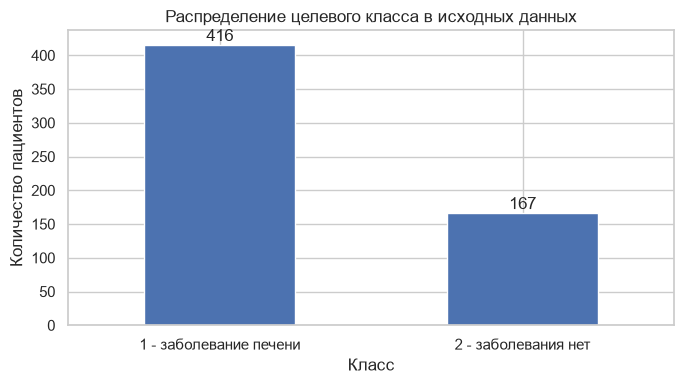

In [38]:
class_counts_raw = df_raw['Dataset'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
labels = {1: '1 - заболевание печени', 2: '2 - заболевания нет'}
plot_counts = class_counts_raw.rename(index=labels)
plot_counts.plot(kind='bar', ax=ax)
ax.set_title('Распределение целевого класса в исходных данных')
ax.set_xlabel('Класс'); ax.set_ylabel('Количество пациентов')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout(); plt.show()

На диаграмме видно резкий дисбаланс: в исходных данных 416 пациентов с заболеванием печени и 167 пациентов без заболевания, соотношение примерно 2.5 : 1.

### Распределение признаков

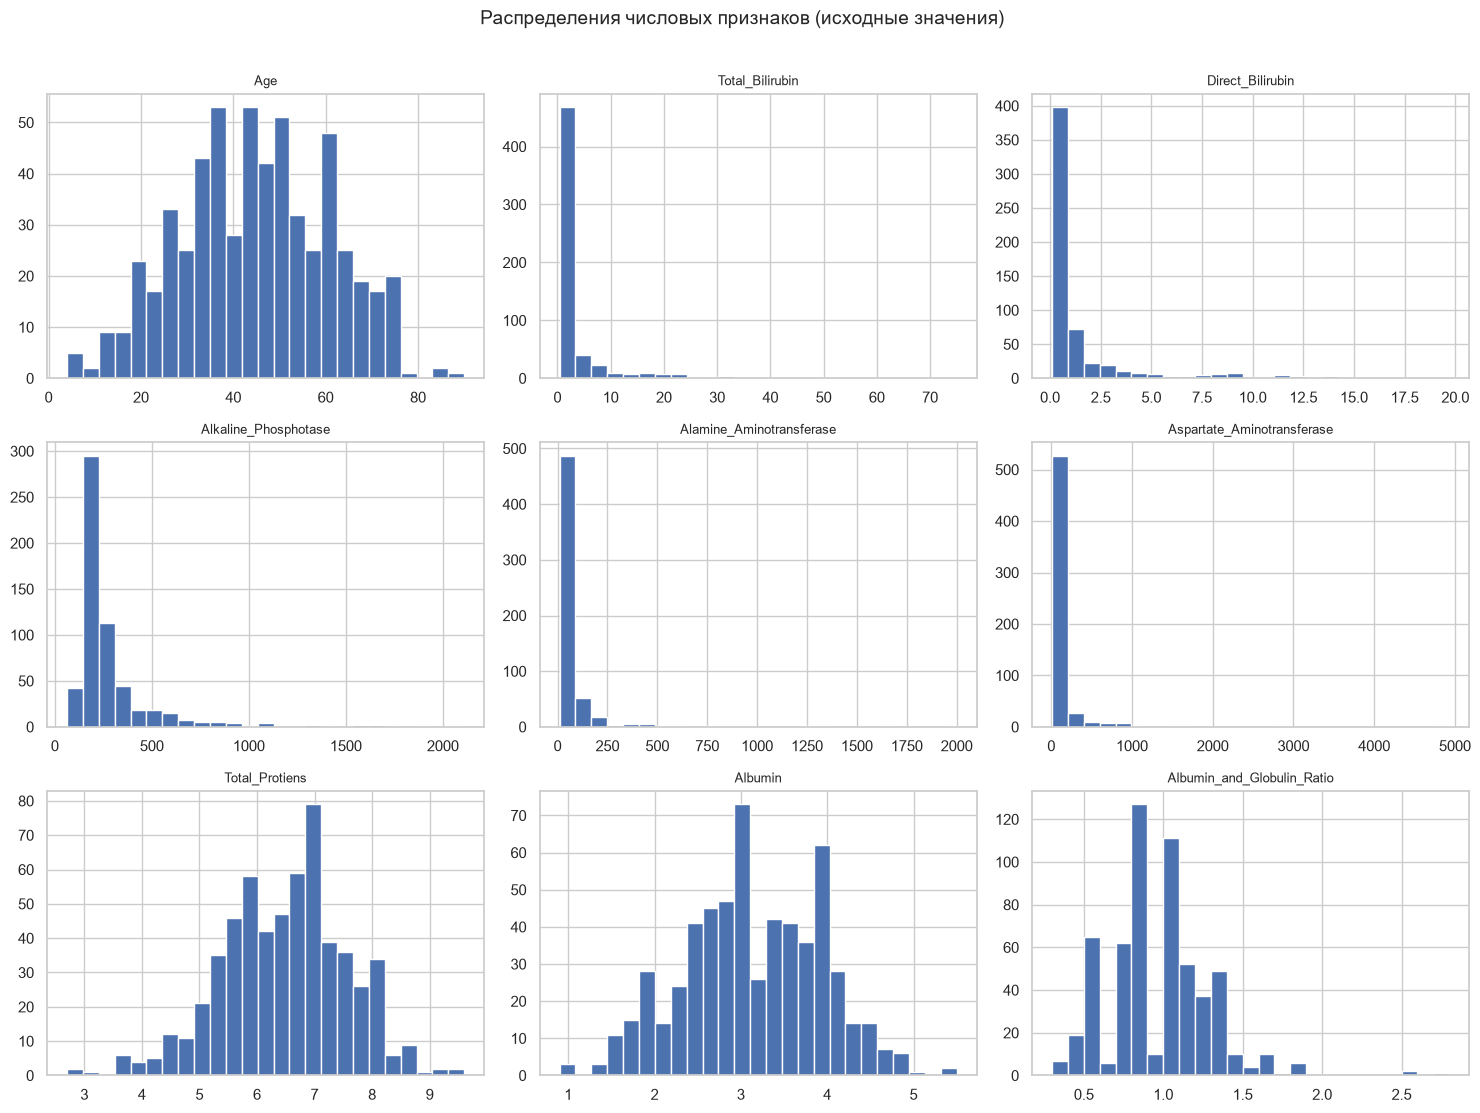

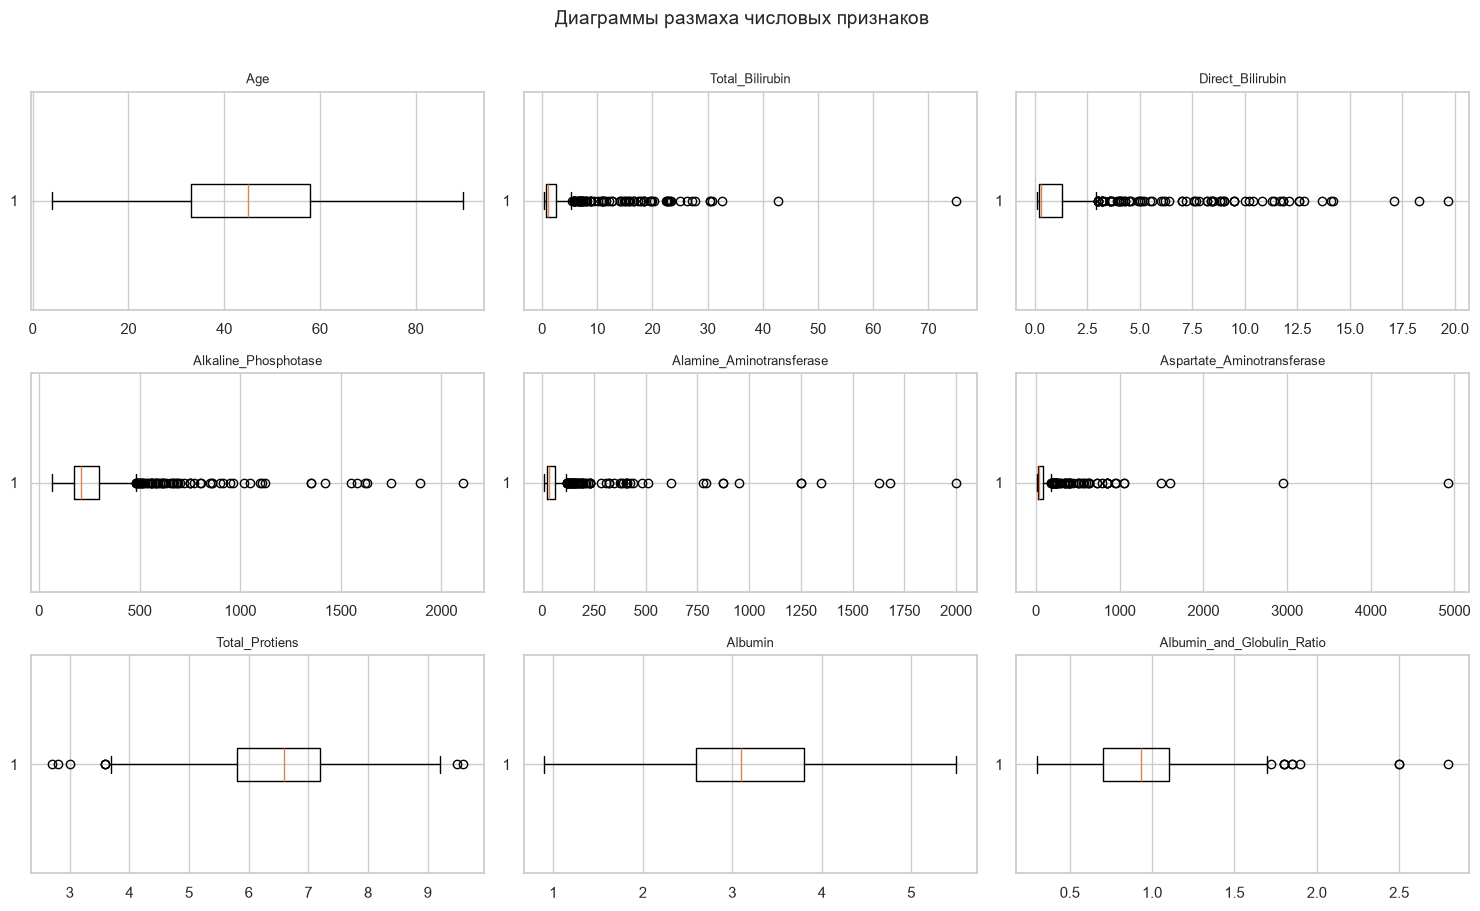

Признаки с наибольшей абсолютной асимметрией распределения:


,Асимметрия
Aspartate_Aminotransferase,10.546177
Alamine_Aminotransferase,6.549192
Total_Bilirubin,4.907474
Alkaline_Phosphotase,3.765106
Direct_Bilirubin,3.212403
Albumin_and_Globulin_Ratio,0.992299


In [39]:
numeric_cols_raw = df_raw.select_dtypes(include=np.number).columns.drop('Dataset', errors='ignore').tolist()
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, numeric_cols_raw):
    ax.hist(df_raw[col].dropna(), bins=25, edgecolor='white')
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('')
for ax in axes.flat[len(numeric_cols_raw):]:
    ax.axis('off')
fig.suptitle('Распределения числовых признаков (исходные значения)', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, numeric_cols_raw):
    ax.boxplot(df_raw[col].dropna(), vert=False)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('')
for ax in axes.flat[len(numeric_cols_raw):]:
    ax.axis('off')
fig.suptitle('Диаграммы размаха числовых признаков', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

skewness = df_raw[numeric_cols_raw].skew(numeric_only=True).sort_values(key=lambda s: s.abs(), ascending=False)
print('Признаки с наибольшей абсолютной асимметрией распределения:')
display(skewness.to_frame('Асимметрия').head(6))

Total_Bilirubin, Direct_Bilirubin, Alkaline_Phosphotase, Alamine_Aminotransferase и Aspartate_Aminotransferase основная масса значений сконцентрирована у левого края оси, а правый хвост тянется на порядки дальше. Возраст имеет колоколообразную форму с небольшим числом детей и пожилых; Total_Protiens и Albumin - компактные, почти симметричные распределения.  

Самые асимметричные признаки: АСТ - 10.55, АЛТ - 6.55, общий билирубин - 4.91, щелочная фосфатаза - 3.77, прямой билирубин - 3.21; у отношения альбумин/глобулин - 0.99 (умеренная).  

Для пяти «ферментных» признаков точки за пределами «усов» (критерий 1.5·IQR) составляют после удаления дубликатов от 11.6 % до 14.6 % объектов (общий билирубин - 83 объекта, прямой - 80, АЛТ - 72, щелочная фосфатаза - 69, АСТ - 66). У Total_Protiens и Albumin_and_Globulin_Ratio выбросов немного (8 и 10 объектов), у Age и Albumin их нет.


### Предобработка данных

In [40]:
# 1. Удаляем полные дубликаты до разделения на train/test.
n_before = len(df_raw)
data = df_raw.drop_duplicates().reset_index(drop=True).copy()
removed_duplicates = n_before - len(data)

# 1 = заболевание, 0 = заболевания нет.
data['target'] = data['Dataset'].map({1: 1, 2: 0})
if data['target'].isna().any():
    raise ValueError('В Dataset обнаружены неожиданные значения, отличные от 1 и 2.')
data = data.drop(columns='Dataset')

# 3. Кодируем бинарный признак пола: Male=1, Female=0.
unknown_gender = set(data['Gender'].dropna().unique()) - {'Male', 'Female'}
if unknown_gender:
    raise ValueError(f'Неизвестные значения Gender: {unknown_gender}')
data['Gender'] = data['Gender'].map({'Female': 0, 'Male': 1}).astype(float)

X = data.drop(columns='target')
y = data['target'].astype(int)

print(f'Исходных строк: {n_before}')
print(f'Удалено полных дубликатов: {removed_duplicates}')
print(f'Строк после удаления дубликатов: {len(data)}')
print(f'Входных признаков: {X.shape[1]}')
print('Пропуски после удаления дубликатов (будут заполнены в Pipeline):')
display(X.isna().sum().rename('Пропусков').to_frame().query('Пропусков > 0'))
print('Целевой класс после очистки (1 = заболевание; 0 = нет заболевания):')
class_counts = y.value_counts().sort_index()
display(pd.DataFrame({'Количество': class_counts, 'Доля, %': (100*class_counts/len(y)).round(2)}).rename(index={0:'0 - нет заболевания', 1:'1 - заболевание'}))

Исходных строк: 583
Удалено полных дубликатов: 13
Строк после удаления дубликатов: 570
Входных признаков: 10
Пропуски после удаления дубликатов (будут заполнены в Pipeline):


,Пропусков
Albumin_and_Globulin_Ratio,4


Целевой класс после очистки (1 = заболевание; 0 = нет заболевания):


,Количество,"Доля, %"
target,,
0 - нет заболевания,164,28.77
1 - заболевание,406,71.23


## Разбиение выборки

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

split_summary = pd.DataFrame({
    'Объектов': [len(X_train), len(X_test), len(X)],
    'Заболевание (1)': [int(y_train.sum()), int(y_test.sum()), int(y.sum())],
    'Нет заболевания (0)': [int((y_train == 0).sum()), int((y_test == 0).sum()), int((y == 0).sum())],
    'Доля заболевания, %': [100*y_train.mean(), 100*y_test.mean(), 100*y.mean()],
}, index=['Обучающая выборка', 'Тестовая выборка', 'Всего']).round(2)
display(split_summary)
assert set(X_train.index).isdisjoint(set(X_test.index))

,Объектов,Заболевание (1),Нет заболевания (0),"Доля заболевания, %"
Обучающая выборка,456,325,131,71.27
Тестовая выборка,114,81,33,71.05
Всего,570,406,164,71.23


Данные разделены в пропорции 80%/20%.

## Методы классификации 

### Описание методов классификации

### Наивный байесовский классификатор 
Строится на теореме Байеса: $P(y\mid x) \propto P(y)\prod_{j} P(x_j\mid y)$. «Наивность» - допущение, что признаки **условно независимы** при заданном классе. Это резко упрощает оценку параметров (нужны лишь одномерные распределения) и делает метод очень быстрым и устойчивым на малых выборках, но допущение нарушается при коррелированных признаках (у нас: билирубины, АЛТ/АСТ, белок/альбумин).
Варианты различаются предположением о распределении $P(x_j\mid y)$:
- **GaussianNB** - признаки непрерывные и нормальные внутри класса. Гиперпараметр `var_smoothing` - доля максимальной дисперсии, добавляемая ко всем дисперсиям для численной устойчивости (сглаживание). Логичный выбор для наших непрерывных признаков.
- **MultinomialNB** - признаки - неотрицательные «счётчики» (классически частоты слов). Гиперпараметры: `alpha` (сглаживание Лапласа), `fit_prior` (учитывать ли априорные вероятности классов). Требует неотрицательных входов, поэтому признаки масштабируются в [0, 1].
- **ComplementNB** - модификация Multinomial, оценивающая параметры по **дополнению** класса (всем остальным); создана для несбалансированных данных. Гиперпараметры: `alpha`, `norm`.
- **BernoulliNB** - признаки бинарны («есть / нет»); непрерывные значения бинаризуются порогом `binarize`. Гиперпараметры: `alpha`, `binarize`.

### Дерево решений (Decision Tree)
Рекурсивно делит пространство признаков порогами вида «признак ≤ значение», выбирая на каждом шаге разбиение, которое сильнее всего уменьшает **неоднородность** узла (критерии `gini` или `entropy`/`log_loss`). Лист выдаёт долю класса. Метод интерпретируем, не требует масштабирования, умеет ловить нелинейности и взаимодействия, но **склонен к переобучению**: неограниченное дерево запоминает обучающую выборку. Ключевые гиперпараметры: `max_depth`, `min_samples_leaf`, `criterion`, `ccp_alpha` (обрезка по сложности), `class_weight`.

### Линейный дискриминантный анализ (LDA)
Предполагает, что внутри каждого класса признаки имеют нормальное распределение с **общей для классов ковариационной матрицей**. Тогда оптимальная граница по Байесу - **гиперплоскость**; LDA одновременно ищет направление, максимально разделяющее классы (критерий Фишера). Гиперпараметры: `solver` (`svd`, `lsqr`, `eigen`), `shrinkage` (регуляризация ковариационной матрицы - полезна при коррелированных признаках; доступна для `lsqr`/`eigen`; `'auto'` - оценка Ледойта-Вольфа), `priors` (априорные вероятности классов - сдвигают порог).

### Метод опорных векторов (SVM)
Находит разделяющую гиперплоскость с **максимальным зазором** между классами; «мягкий» зазор допускает ошибки со штрафом `C` (большой `C` - меньше ошибок на обучении, но выше риск переобучения). С помощью **ядер** (`linear`, `poly`, `rbf`, `sigmoid`) строится нелинейная граница. У RBF-ядра параметр `gamma` задаёт «радиус влияния» объекта (большая `gamma` - очень локальная, «изрезанная» граница). Метод чувствителен к масштабу признаков. `class_weight='balanced'` увеличивает штраф за ошибки на редком классе.

### Метод ближайших соседей (kNN)
«Ленивый» метод: при предсказании находит `k` ближайших обучающих объектов и голосует (возможно, с весами обратно пропорциональными расстоянию). Гиперпараметры: `n_neighbors` (малое `k` - шумная граница и переобучение, большое - сильное сглаживание и вырождение к большинству), `weights` (`uniform` / `distance`), `metric` (евклидова, манхэттенская, Чебышёва, Минковского). Очень чувствителен к масштабу признаков и «проклятию размерности».


### Обучение модели

In [42]:
def make_pipeline(estimator, scaling='standard'):
    """Импутация обучающей медианой + выбранное масштабирование + модель."""
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if scaling == 'standard':
        steps.append(('scaler', StandardScaler()))
    elif scaling == 'minmax':
        steps.append(('scaler', MinMaxScaler()))
    elif scaling != 'none':
        raise ValueError("scaling должен быть 'standard', 'minmax' или 'none'")
    steps.append(('classifier', estimator))
    return Pipeline(steps)


def get_score(model, X_part):
    """Скор для ROC-AUC: вероятность класса 1 или decision_function."""
    if hasattr(model, 'predict_proba'):
        proba = model.predict_proba(X_part)
        classes = list(model.classes_) if hasattr(model, 'classes_') else None
        if classes is not None and 1 in classes:
            return proba[:, classes.index(1)]
        return proba[:, 1]
    if hasattr(model, 'decision_function'):
        return model.decision_function(X_part)
    return model.predict(X_part)


def calc_metrics(model, X_part, y_true):
    y_pred = model.predict(X_part)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'AUC': roc_auc_score(y_true, get_score(model, X_part)),
        'Specificity': tn / (tn + fp) if (tn + fp) else 0.0,
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
    }

In [43]:
baseline_models = {
    'GaussianNB': make_pipeline(GaussianNB(), 'standard'),
    'MultinomialNB': make_pipeline(MultinomialNB(), 'minmax'),
    'ComplementNB': make_pipeline(ComplementNB(), 'minmax'),
    'BernoulliNB': make_pipeline(BernoulliNB(binarize=0.0), 'standard'),
    'Decision Tree': make_pipeline(DecisionTreeClassifier(random_state=SEED), 'none'),
    'LDA': make_pipeline(LinearDiscriminantAnalysis(), 'standard'),
    'SVM (RBF)': make_pipeline(SVC(probability=True, random_state=SEED), 'standard'),
    'kNN': make_pipeline(KNeighborsClassifier(), 'standard'),
}

baseline_rows = {}
fitted_base = {}
for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    fitted_base[name] = model
    row = calc_metrics(model, X_test, y_test)
    row['Train Accuracy'] = accuracy_score(y_train, model.predict(X_train))
    baseline_rows[name] = row
baseline_df = pd.DataFrame(baseline_rows).T.sort_values('F1', ascending=False)
print('Метрики базовых моделей на тестовой выборке (не участвовавшей в обучении):')
display(baseline_df.round(3))
print('\nЛучшая базовая модель по F1 положительного класса:', baseline_df['F1'].idxmax())
print('Лучшая базовая модель по ROC-AUC:', baseline_df['AUC'].idxmax())

Метрики базовых моделей на тестовой выборке (не участвовавшей в обучении):


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy
MultinomialNB,0.711,0.711,1.000,0.831,0.804,0.000,0.500,0.713
SVM (RBF),0.711,0.711,1.000,0.831,0.654,0.000,0.500,0.713
LDA,0.702,0.720,0.951,0.819,0.765,0.091,0.521,0.711
kNN,0.693,0.745,0.864,0.800,0.681,0.273,0.568,0.792
BernoulliNB,0.719,0.818,0.778,0.797,0.798,0.576,0.677,0.658
ComplementNB,0.693,0.960,0.593,0.733,0.804,0.939,0.766,0.581
Decision Tree,0.623,0.744,0.716,0.730,0.555,0.394,0.555,1.000
GaussianNB,0.605,1.000,0.444,0.615,0.808,1.000,0.722,0.533



Лучшая базовая модель по F1 положительного класса: MultinomialNB
Лучшая базовая модель по ROC-AUC: GaussianNB


- MultinomialNB и SVM (RBF) - Accuracy 0.711, Precision 0.711, Recall 1.000, F1 0.831, Specificity 0.000, Balanced Accuracy 0.500. Это ровно показатели тривиального классификатора «все больны»: матрица ошибок (0 здоровых распознано, 33 ложные тревоги, 81 больной найден). Высокий F1 здесь иллюзорен - модель не различает классы.  

- LDA - почти то же самое: Recall 0.951, но Specificity лишь 0.091 (из 33 здоровых верно распознаны 3); Accuracy 0.702 даже ниже уровня тривиального классификатора.  

- kNN - Accuracy 0.693, Recall 0.864, Specificity 0.273; точность на обучении 0.792 против 0.693 на тесте - признаки переобучения при k=5; ROC-AUC лишь 0.681.  

- BernoulliNB - лучшая Accuracy среди базовых моделей (0.719) и при этом сбалансированные ошибки: Precision 0.818, Recall 0.778, Specificity 0.576 (19 здоровых из 33), Balanced Accuracy 0.677.

- ComplementNB - противоположный крайний случай: Precision 0.960, Specificity 0.939, но Recall всего 0.593 (пропущено 33 из 81 больных). Лучшая Balanced Accuracy среди базовых моделей - 0.766.

- GaussianNB - Precision 1.000 (все 33 здоровых распознаны), но Recall лишь 0.444 (пропущено 45 из 81 больных), Accuracy 0.605 - самая низкая среди всех базовых моделей; точность на обучении (0.533) ниже доли большинства, т.е. модель систематически слишком часто говорит «здоров». Причина - нарушение нормальности: хвосты распределений раздувают дисперсию признаков и «размывают» вероятность болезни.

- Decision Tree - классическое переобучение: Accuracy на обучении 1.000, на тесте 0.623, ROC-AUC 0.555 - почти уровень случайного угадывания, так как неограниченное дерево выдаёт вероятности только 0 и 1.

Accuracy - BernoulliNB (0.719); Precision - GaussianNB (1.000); Recall - MultinomialNB (1.000); F1 - MultinomialNB (0.831); ROC-AUC - GaussianNB (0.808). Ни одна модель не лидирует сразу по всем метрикам, а между Precision и Recall наблюдается явный обмен: чем выше одна, тем ниже другая.

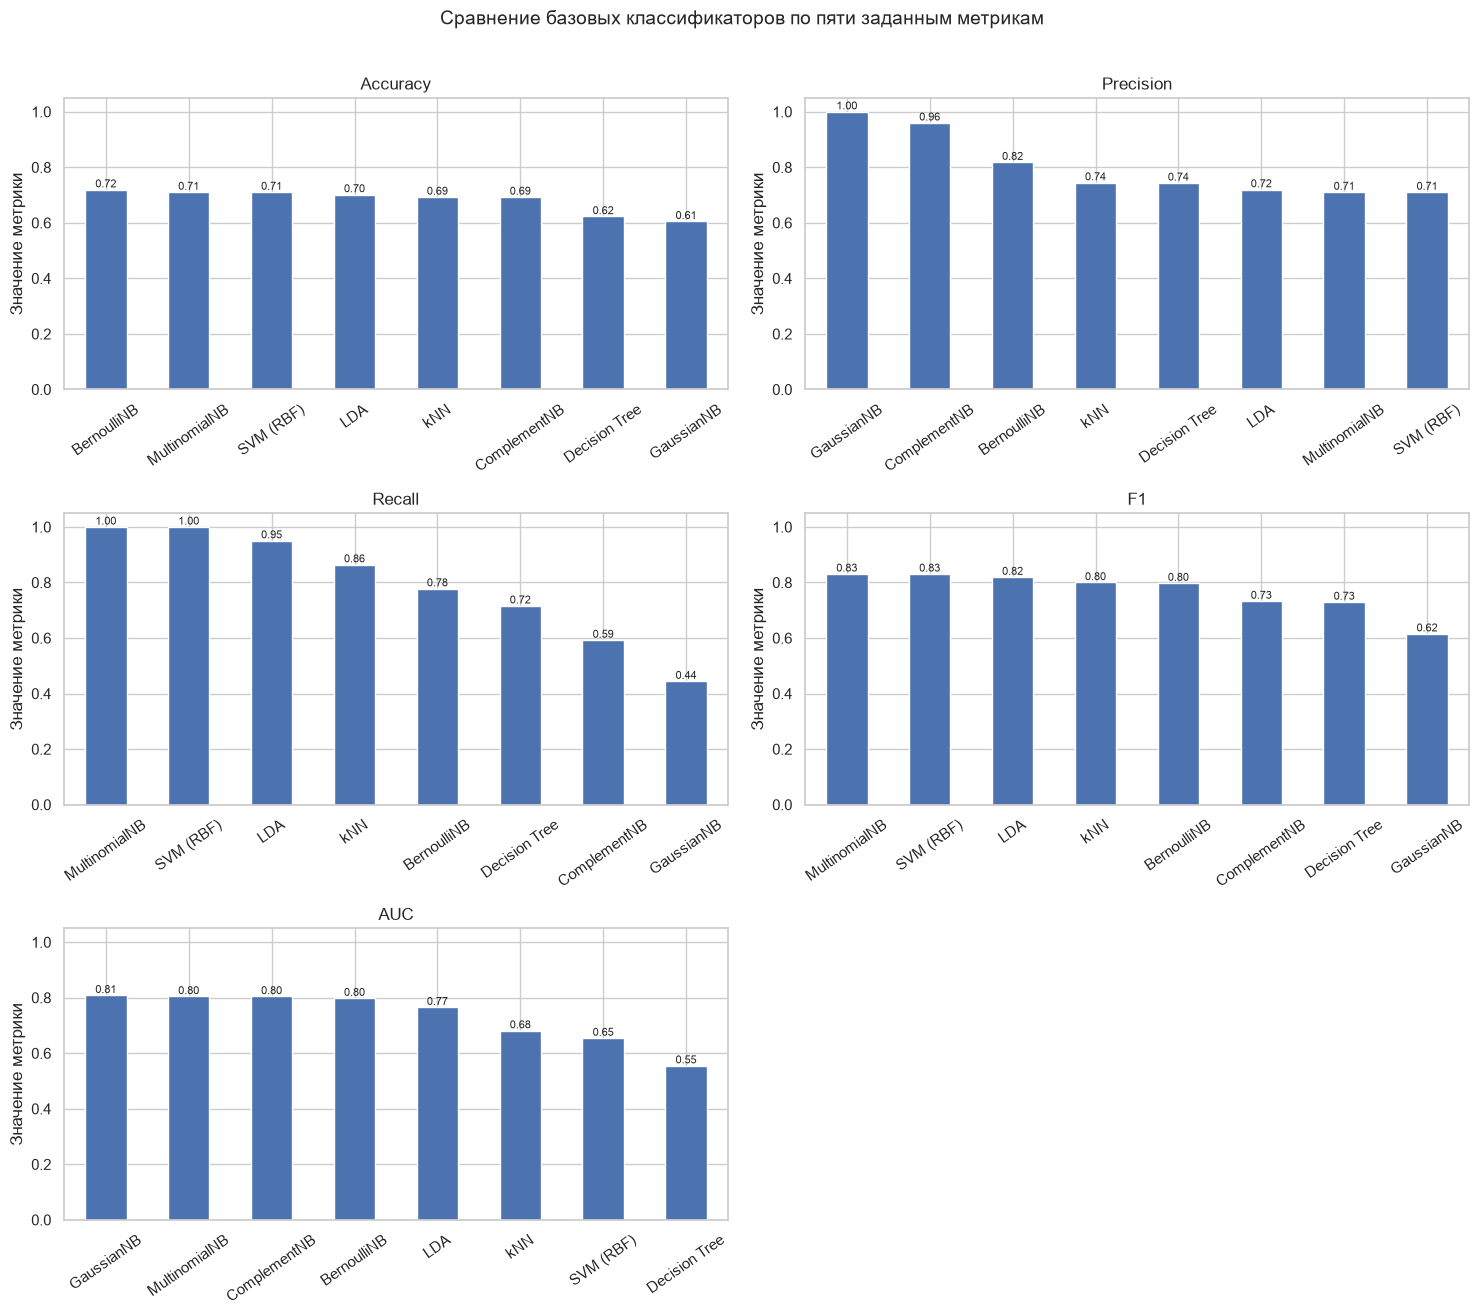

Лидеры по каждой метрике:
  Accuracy: BernoulliNB = 0.719
  Precision: GaussianNB = 1.000
  Recall: MultinomialNB = 1.000
  F1: MultinomialNB = 0.831
  AUC: GaussianNB = 0.808


In [44]:
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
for ax, metric in zip(axes.flat, metrics_to_plot):
    values = baseline_df[metric].sort_values(ascending=False)
    values.plot(kind='bar', ax=ax)
    ax.set_title(metric)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Значение метрики')
    ax.tick_params(axis='x', rotation=35)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.2f}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=8)
axes.flat[-1].axis('off')
fig.suptitle('Сравнение базовых классификаторов по пяти заданным метрикам', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

print('Лидеры по каждой метрике:')
for metric in metrics_to_plot:
    best_name = baseline_df[metric].idxmax()
    print(f'  {metric}: {best_name} = {baseline_df.loc[best_name, metric]:.3f}')

1. Accuracy: все столбцы лежат в узком интервале 0.605–0.719 (размах всего 0.114); относительно тривиального уровня 0.711 заметно (на 0.09–0.10) хуже лишь GaussianNB (0.605) и Decision Tree (0.623), остальные отличаются от него не более чем на 0.02. Метрика практически не различает модели.
2. Precision: 0.711–1.000. Максимум у GaussianNB (1.000) и ComplementNB (0.960); минимум 0.711 у MultinomialNB и SVM - это доля больных в выборке, т.е. «чистая» базовая линия.
3. Recall: 0.444–1.000. Картина зеркальна Precision: лидеры по Precision (GaussianNB, ComplementNB) имеют самый низкий Recall (0.444 и 0.593), а MultinomialNB/SVM (Recall 1.000) - самую низкую Precision.
4. F1: 0.615–0.831; лидируют модели с Recall = 1 (MultinomialNB, SVM - 0.831), за ними LDA (0.819) и kNN (0.800). F1 при таком дисбалансе поощряет «всех в больные».
5. ROC-AUC: 0.555–0.808 - единственная метрика с реальным разбросом между моделями: четыре байесовских/NB-модели выше 0.79, LDA 0.765, kNN 0.681, SVM 0.654, дерево 0.555.

Accuracy - BernoulliNB, Precision - GaussianNB, Recall и F1 - MultinomialNB, AUC - GaussianNB. Вывод: выбор «лучшей» модели зависит от того, какая метрика важнее.

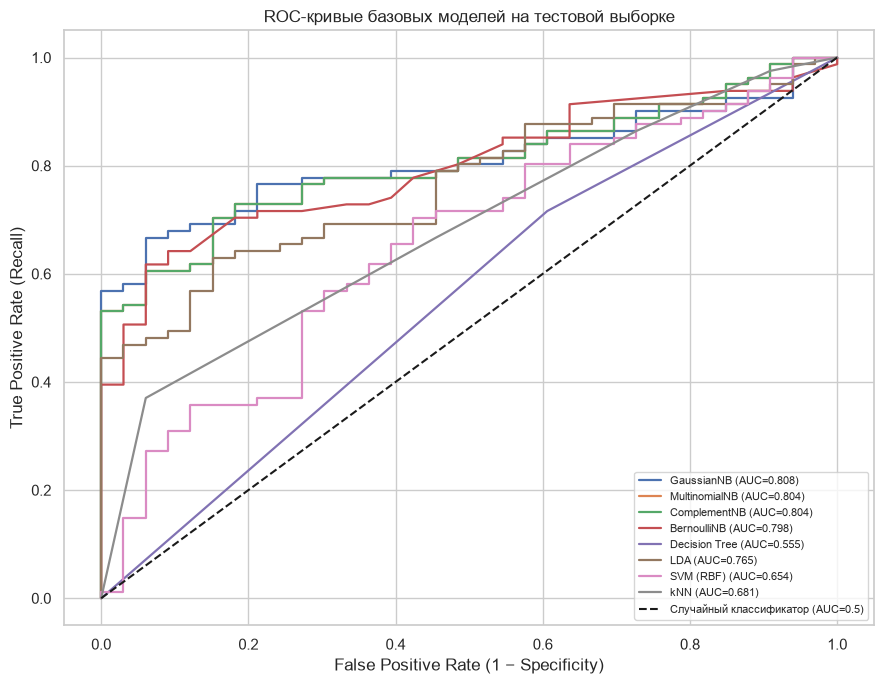

Максимальный AUC среди базовых моделей: 0.808 - GaussianNB


In [45]:
plt.figure(figsize=(9, 7))
for name, model in fitted_base.items():
    fpr, tpr, _ = roc_curve(y_test, get_score(model, X_test))
    plt.plot(fpr, tpr, linewidth=1.6, label=f'{name} (AUC={baseline_df.loc[name, "AUC"]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случайный классификатор (AUC=0.5)')
plt.xlabel('False Positive Rate (1 − Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC-кривые базовых моделей на тестовой выборке')
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()
print('Максимальный AUC среди базовых моделей:', f'{baseline_df.AUC.max():.3f}', '-', baseline_df.AUC.idxmax())

- GaussianNB (AUC 0.808), MultinomialNB и ComplementNB (0.804), BernoulliNB (0.798) образуют верхнюю «связку»: на малых ложных тревогах (FPR ≈ 0–0.1) они уже находят 40–57 % больных (GaussianNB - около 0.57 при FPR = 0), затем кривые растут примерно вровень. Кривые MultinomialNB и ComplementNB практически совпадают (одинаковый AUC 0.804): они используют схожие веса признаков, а различаются лишь порогом принятия решения, который на ROC-кривой не виден.

- LDA (0.765) ниже верхней группы на всём протяжении, хотя при FPR ≈ 0.7–1.0 приближается к ней.

- kNN (0.681) имеет угловатую форму с одним заметным изломом: вероятности при k=5 принимают только значения 0, 0.2, …, 1, поэтому различимых порогов очень мало.

- SVM (RBF) (0.654) идёт ступенчато и на значительном участке лежит ближе к диагонали, чем у NB и LDA.

- Decision Tree (0.555) почти совпадает с диагональю: переобученное дерево даёт «жёсткие» вероятности 0 и 1, кривая - по сути ломаная из двух отрезков через одну точку.

Главный вывод: **по способности ранжировать пациентов базовые наивные байесовские классификаторы существенно лучше SVM, kNN и дерева**. Максимальный AUC - 0.808 (GaussianNB).

## Настройка гиперпараметров

In [46]:
from sklearn.metrics import make_scorer

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "F1": make_scorer(f1_score, zero_division=0),
    "AUC": "roc_auc",
}
METRICS = ["Accuracy", "Precision", "Recall", "F1", "AUC"]

joint_searches = {}
sweep_results = {}          # полные таблицы всех комбинаций по каждой модели
tuned_models = {}
tuned_rows = {}
tuned_best_params = {}


def _display_param_value(value):
    """Удобное текстовое представление значения гиперпараметра."""
    if value is None:
        return "None"
    if isinstance(value, (float, np.floating)) and 0 < abs(value) < 0.001:
        return f"{value:.1e}"
    return str(value)


def joint_grid_search(name, estimator, scaling, param_grid, param_names):
    """Перебирает все комбинации, строит маргинальные графики и оценивает лучший вариант на тесте."""
    pipeline = make_pipeline(estimator, scaling)
    gs = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring=cv_scoring,
        refit="AUC",
        cv=cv,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise",
    )
    gs.fit(X_train, y_train)
    joint_searches[name] = gs

    raw = pd.DataFrame(gs.cv_results_)
    table = pd.DataFrame(index=raw.index)
    for p in param_names:
        col = f"param_classifier__{p}"
        vals = raw[col].tolist()
        table[p] = [None if (isinstance(v, float) and np.isnan(v)) else v for v in vals]
    for metric in METRICS:
        table[f"CV {metric}"] = raw[f"mean_test_{metric}"].astype(float)
        table[f"SD {metric}"] = raw[f"std_test_{metric}"].astype(float)
    table["Ранг по ROC-AUC"] = raw["rank_test_AUC"].astype(int)
    sweep_results[name] = table
    tuned_best_params[name] = dict(gs.best_params_)

    print(f"\n{'='*90}\n{name}: совместный перебор гиперпараметров")
    print(f"Число проверенных комбинаций: {len(table)}")
    print("Лучшие параметры по среднему CV ROC-AUC:", gs.best_params_)
    print(f"Лучший средний CV ROC-AUC: {gs.best_score_:.4f}")
    print("\nТаблица всех комбинаций (средние метрики по 5 фолдам):")
    show_cols = param_names + [f"CV {m}" for m in METRICS] + ["Ранг по ROC-AUC"]
    display(table[show_cols].sort_values("Ранг по ROC-AUC").round(4))

    marginal_tables = {}
    for p in param_names:
        tmp = table.copy()
        tmp["_label"] = tmp[p].map(_display_param_value)
        marginal = tmp.groupby("_label", sort=False)[[f"CV {m}" for m in METRICS]].mean()
        marginal_tables[p] = marginal
        x = np.arange(len(marginal))
        fig, ax = plt.subplots(figsize=(10, 5.5))
        for metric in METRICS:
            ax.plot(x, marginal[f"CV {metric}"], marker="o", linewidth=1.8, label=metric)
        ax.set_xticks(x)
        ax.set_xticklabels(marginal.index, rotation=35, ha="right")
        ax.set_ylim(0, 1.05)
        ax.set_xlabel(p)
        ax.set_ylabel("Средняя метрика CV")
        ax.set_title(f"{name}: маргинальное влияние {p} (усреднение по остальным параметрам)")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best", ncol=2)
        plt.tight_layout()
        plt.show()
        print(f"Маргинальные средние для параметра {p}:")
        display(marginal.rename(columns={f"CV {m}": m for m in METRICS}).round(4))

    best = gs.best_estimator_
    tuned_models[name] = best
    test_metrics = calc_metrics(best, X_test, y_test)
    test_metrics["Train Accuracy"] = accuracy_score(y_train, best.predict(X_train))
    test_metrics["CV AUC (best)"] = gs.best_score_
    test_metrics["Best parameter"] = str(gs.best_params_)
    tuned_rows[name] = test_metrics

    print("\nМетрики лучшей комбинации на отложенной тестовой выборке:")
    display(pd.DataFrame([test_metrics]).round(4))
    return gs


### GaussianNB  

**Изменяемые параметры**

- var_smoothing - доля максимальной дисперсии признаков, которая добавляется ко всем дисперсиям. Это сглаживание: слишком маленькое значение делает оценку неустойчивой на редких хвостах, слишком большое - размывает различия между классами.


GaussianNB: совместный перебор гиперпараметров
Число проверенных комбинаций: 12
Лучшие параметры по среднему CV ROC-AUC: {'classifier__var_smoothing': np.float64(0.01)}
Лучший средний CV ROC-AUC: 0.7151

Таблица всех комбинаций (средние метрики по 5 фолдам):


,var_smoothing,CV Accuracy,CV Precision,CV Recall,CV F1,CV AUC,Ранг по ROC-AUC
10,0.0100,0.5218,0.9485,0.3477,0.5039,0.7151,1
9,0.0010,0.5416,0.9524,0.3754,0.5345,0.7141,2
0,0.0000,0.5416,0.9524,0.3754,0.5345,0.7134,3
1,0.0000,0.5416,0.9524,0.3754,0.5345,0.7134,3
4,0.0000,0.5416,0.9524,0.3754,0.5345,0.7134,3
5,0.0000,0.5416,0.9524,0.3754,0.5345,0.7134,3
2,0.0000,0.5416,0.9524,0.3754,0.5345,0.7134,3
3,0.0000,0.5416,0.9524,0.3754,0.5345,0.7134,3
7,0.0000,0.5416,0.9524,0.3754,0.5345,0.7134,3
6,0.0000,0.5416,0.9524,0.3754,0.5345,0.7134,3


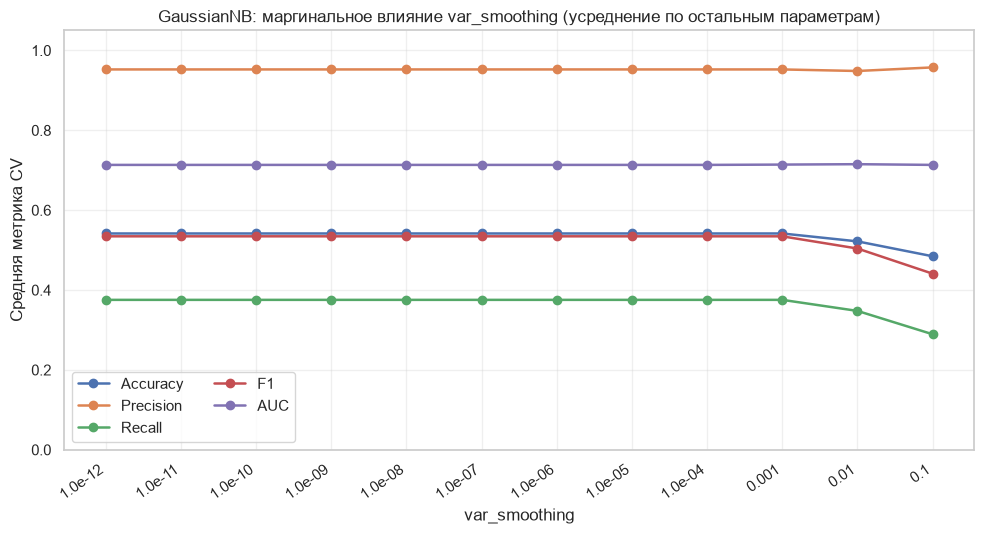

Маргинальные средние для параметра var_smoothing:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
1.0e-12,0.5416,0.9524,0.3754,0.5345,0.7134
1.0e-11,0.5416,0.9524,0.3754,0.5345,0.7134
1.0e-10,0.5416,0.9524,0.3754,0.5345,0.7134
1.0e-09,0.5416,0.9524,0.3754,0.5345,0.7134
1.0e-08,0.5416,0.9524,0.3754,0.5345,0.7134
1.0e-07,0.5416,0.9524,0.3754,0.5345,0.7134
1.0e-06,0.5416,0.9524,0.3754,0.5345,0.7134
1.0e-05,0.5416,0.9524,0.3754,0.5345,0.7134
1.0e-04,0.5416,0.9524,0.3754,0.5345,0.7134



Метрики лучшей комбинации на отложенной тестовой выборке:


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best),Best parameter
0,0.5877,1.0,0.4198,0.5913,0.8137,1.0,0.7099,0.5175,0.7151,{'classifier__var_smoothing': np.float64(0.01)}


In [47]:
gs_gnb = joint_grid_search(
    name="GaussianNB",
    estimator=GaussianNB(),
    scaling="standard",
    param_grid={"classifier__var_smoothing": list(np.logspace(-12, -1, 12))},
    param_names=["var_smoothing"],
)


Перебиралось 12 значений var_smoothing на логарифмической сетке от 10⁻¹² до 10⁻¹.

- Диапазон 10⁻¹² … 10⁻⁴ - метрики не меняются вообще: Accuracy 0.5416, Precision 0.9524, Recall 0.3754, F1 0.5345, ROC-AUC 0.7134 для всех девяти значений.

var_smoothing = 0.01. На тесте: Accuracy 0.588, Precision 1.000, Recall 0.420, F1 0.591, ROC-AUC **0.814**, Specificity 1.000 (матрица ошибок: TN 33, FP 0, FN 47, TP 34). По сравнению с базовой моделью: ROC-AUC +0.005, Accuracy −0.018, Recall −0.025, F1 −0.024. Точность на обучающей выборке 0.518 - ниже доли большинства.

Настройка почти ничего не дала: узкое место GaussianNB - не сглаживание, а допущение о нормальности на сильно асимметричных признаках, которое делает модель чрезмерно «осторожной» (никогда не даёт ложной тревоги, но пропускает 58 % больных). Такая модель уместна лишь там, где ложноположительный результат недопустим.

### MultinomialNB

**Исследуемые параметры**

- alpha - аддитивное сглаживание. Малое значение сохраняет различия между оценёнными вероятностями признаков, большое сильнее сглаживает их и может скрыть полезные различия.
- fit_prior - при True априорные вероятности классов оцениваются по частотам в обучающей выборке; при False используются равные априорные вероятности. Это важно при дисбалансе классов.



MultinomialNB: совместный перебор гиперпараметров
Число проверенных комбинаций: 14
Лучшие параметры по среднему CV ROC-AUC: {'classifier__alpha': 0.01, 'classifier__fit_prior': True}
Лучший средний CV ROC-AUC: 0.7097

Таблица всех комбинаций (средние метрики по 5 фолдам):


,alpha,fit_prior,CV Accuracy,CV Precision,CV Recall,CV F1,CV AUC,Ранг по ROC-AUC
0,0.01,True,0.7127,0.7127,1.0000,0.8323,0.7097,1
1,0.01,False,0.5833,0.8939,0.4738,0.6167,0.7097,1
2,0.10,True,0.7127,0.7127,1.0000,0.8323,0.7092,3
3,0.10,False,0.5811,0.8989,0.4677,0.6124,0.7092,3
4,0.50,True,0.7127,0.7127,1.0000,0.8323,0.7061,5
5,0.50,False,0.5636,0.8984,0.4400,0.5888,0.7061,5
6,1.00,True,0.7127,0.7127,1.0000,0.8323,0.7034,7
7,1.00,False,0.5614,0.9066,0.4308,0.5825,0.7034,7
8,2.00,True,0.7127,0.7127,1.0000,0.8323,0.7027,9
9,2.00,False,0.5505,0.9058,0.4154,0.5662,0.7027,9


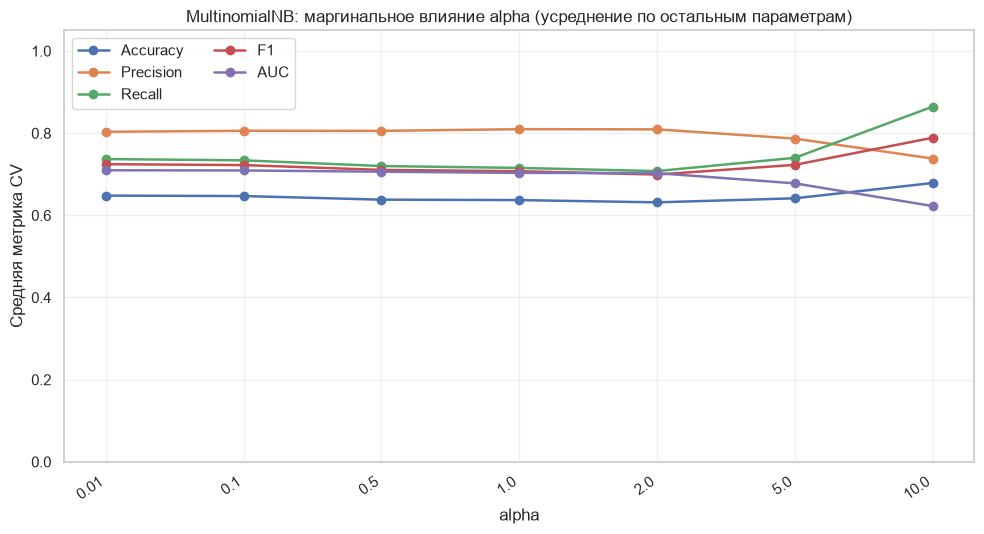

Маргинальные средние для параметра alpha:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
0.01,0.6480,0.8033,0.7369,0.7245,0.7097
0.1,0.6469,0.8058,0.7338,0.7223,0.7092
0.5,0.6382,0.8056,0.7200,0.7105,0.7061
1.0,0.6371,0.8097,0.7154,0.7074,0.7034
2.0,0.6316,0.8093,0.7077,0.6992,0.7027
5.0,0.6414,0.7868,0.7400,0.7229,0.6779
10.0,0.6787,0.7382,0.8646,0.7888,0.6226


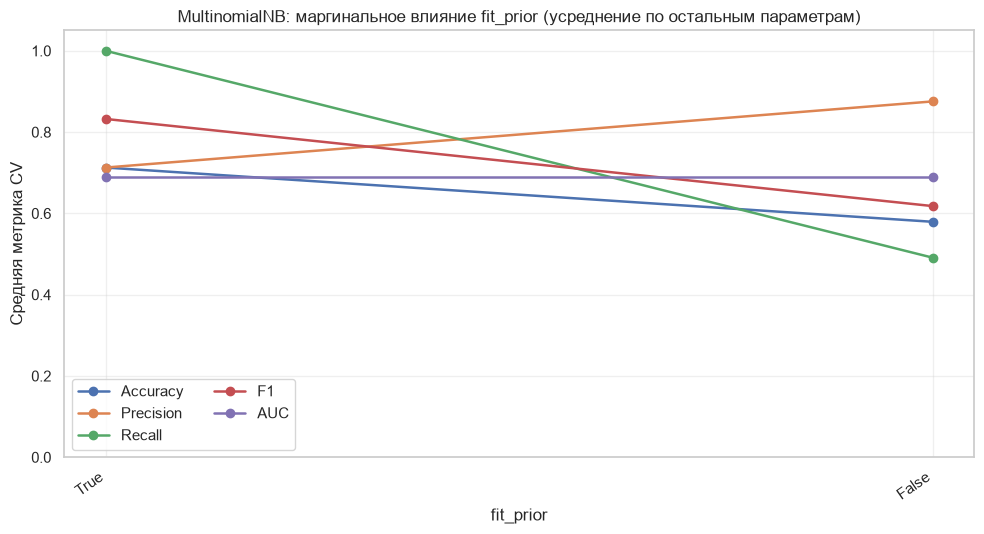

Маргинальные средние для параметра fit_prior:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
True,0.7127,0.7127,1.000,0.8323,0.6902
False,0.5792,0.8754,0.491,0.6179,0.6902



Метрики лучшей комбинации на отложенной тестовой выборке:


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best),Best parameter
0,0.7105,0.7105,1.0,0.8308,0.8186,0.0,0.5,0.7127,0.7097,"{'classifier__alpha': 0.01, 'classifier__fit_prior': True}"


In [48]:
gs_mnb = joint_grid_search(
    name="MultinomialNB",
    estimator=MultinomialNB(),
    scaling="minmax",
    param_grid={
        "classifier__alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
        "classifier__fit_prior": [True, False],
    },
    param_names=["alpha", "fit_prior"],
)


Сетка: alpha ∈ {0.01, 0.1, 0.5, 1, 2, 5, 10} и fit_prior ∈ {True, False} - 14 комбинаций.

- Влияние alpha на ROC-AUC монотонно отрицательное:** Для малых alpha (до 2) изменение незначительно (0.007), но при alpha ≥ 5 качество резко падает: сильное сглаживание «стирает» различия между вероятностями признаков.

- fit_prior не меняет ROC-AUC (по 0.6902 для обоих значений в маргинальном усреднении): априорные вероятности лишь сдвигают порог, а не порядок оценок. Зато он радикально меняет решения:
  - fit_prior=True - для любого alpha Accuracy 0.7127, Precision 0.7127, Recall 1.000, F1 0.8323, т.е. модель объявляет всех больными (тривиальный классификатор);
  - fit_prior=False (равные априорные вероятности) - Accuracy 0.58, Precision 0.88, Recall 0.49, F1 0.62 (маргинальное усреднение): модель снова различает классы, но за счёт потери Recall.

Лучший вариант и тест. Первое место по CV ROC-AUC (0.7097) делят alpha=0.01 с fit_prior=True и False (одинаковый AUC); GridSearchCV берёт первую из равных, то есть fit_prior=True. На тесте: Accuracy 0.711, Precision 0.711, Recall 1.000, F1 0.831, ROC-AUC 0.819 (+0.014 к базовой модели; столько же у ComplementNB - это наибольший тестовый AUC среди всех методов), Specificity 0.000. Все пороговые метрики идентичны базовой модели.

### ComplementNB

**Исследуемые параметры**

- alpha - сглаживание оценок вероятностей признаков.
- norm - дополнительная нормализация весов, рассчитанных по дополнению классов. Её эффект проверяется отдельно при фиксированном alpha.


MultinomialNB: совместный перебор гиперпараметров
Число проверенных комбинаций: 14
Лучшие параметры по среднему CV ROC-AUC: {'classifier__alpha': 0.01, 'classifier__fit_prior': True}
Лучший средний CV ROC-AUC: 0.7097

Таблица всех комбинаций (средние метрики по 5 фолдам):


,alpha,fit_prior,CV Accuracy,CV Precision,CV Recall,CV F1,CV AUC,Ранг по ROC-AUC
0,0.01,True,0.7127,0.7127,1.0000,0.8323,0.7097,1
1,0.01,False,0.5833,0.8939,0.4738,0.6167,0.7097,1
2,0.10,True,0.7127,0.7127,1.0000,0.8323,0.7092,3
3,0.10,False,0.5811,0.8989,0.4677,0.6124,0.7092,3
4,0.50,True,0.7127,0.7127,1.0000,0.8323,0.7061,5
5,0.50,False,0.5636,0.8984,0.4400,0.5888,0.7061,5
6,1.00,True,0.7127,0.7127,1.0000,0.8323,0.7034,7
7,1.00,False,0.5614,0.9066,0.4308,0.5825,0.7034,7
8,2.00,True,0.7127,0.7127,1.0000,0.8323,0.7027,9
9,2.00,False,0.5505,0.9058,0.4154,0.5662,0.7027,9


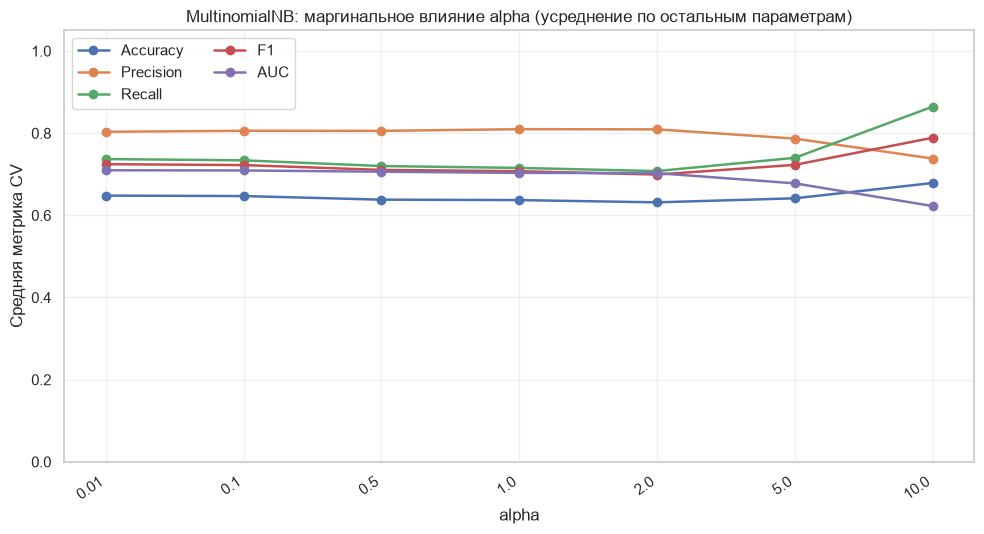

Маргинальные средние для параметра alpha:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
0.01,0.6480,0.8033,0.7369,0.7245,0.7097
0.1,0.6469,0.8058,0.7338,0.7223,0.7092
0.5,0.6382,0.8056,0.7200,0.7105,0.7061
1.0,0.6371,0.8097,0.7154,0.7074,0.7034
2.0,0.6316,0.8093,0.7077,0.6992,0.7027
5.0,0.6414,0.7868,0.7400,0.7229,0.6779
10.0,0.6787,0.7382,0.8646,0.7888,0.6226


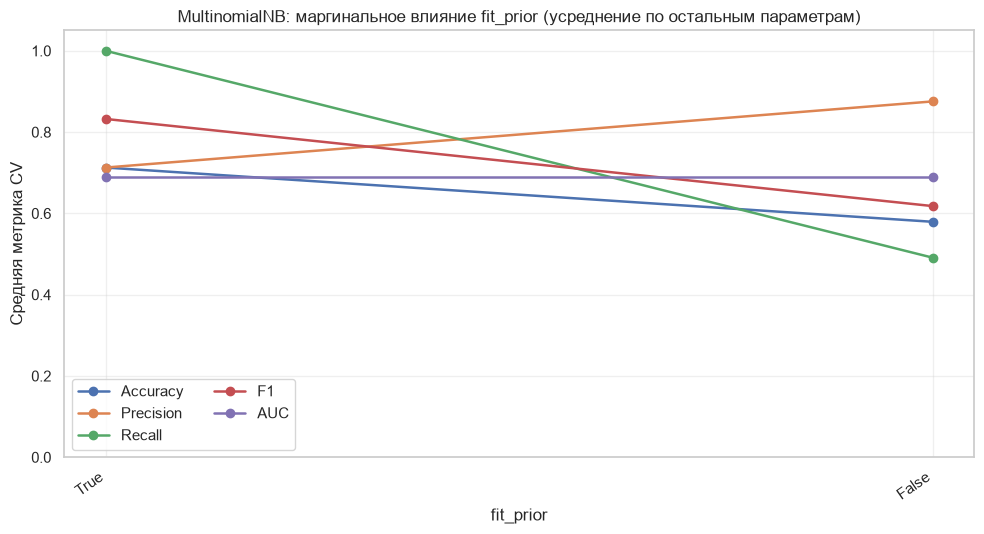

Маргинальные средние для параметра fit_prior:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
True,0.7127,0.7127,1.000,0.8323,0.6902
False,0.5792,0.8754,0.491,0.6179,0.6902



Метрики лучшей комбинации на отложенной тестовой выборке:


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best),Best parameter
0,0.7105,0.7105,1.0,0.8308,0.8186,0.0,0.5,0.7127,0.7097,"{'classifier__alpha': 0.01, 'classifier__fit_prior': True}"


In [49]:
gs_mnb = joint_grid_search(
    name="MultinomialNB",
    estimator=MultinomialNB(),
    scaling="minmax",
    param_grid={
        "classifier__alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
        "classifier__fit_prior": [True, False],
    },
    param_names=["alpha", "fit_prior"],
)


Сетка: alpha ∈ {0.01, 0.1, 0.5, 1, 2, 5, 10} и norm ∈ {False, True} - 14 комбинаций. 

Лучший вариант и тест. alpha=0.01, norm=False: CV ROC-AUC 0.7097, Accuracy 0.5833, Precision 0.8939, Recall 0.4738, F1 0.6167. На тесте: Accuracy 0.702, Precision 0.943, Recall 0.617, F1 0.746, ROC-AUC 0.819, Specificity 0.909 (TN 30, FP 3, FN 31, TP 50). По сравнению с базовой моделью: Accuracy +0.009, Precision −0.017, Recall +0.025, F1 +0.013, ROC-AUC +0.014.

### BernoulliNB

**Исследуемые параметры**

- alpha - сглаживание вероятностей бинарных признаков.
- binarize - порог, по которому непрерывный признак превращается в 0 или 1. После стандартизации порог `0` разделяет значения ниже и выше среднего по обучающей выборке.
- fit_prior - использование эмпирических или равных априорных вероятностей классов.


ComplementNB: совместный перебор гиперпараметров
Число проверенных комбинаций: 14
Лучшие параметры по среднему CV ROC-AUC: {'classifier__alpha': 0.01, 'classifier__norm': False}
Лучший средний CV ROC-AUC: 0.7097

Таблица всех комбинаций (средние метрики по 5 фолдам):


,alpha,norm,CV Accuracy,CV Precision,CV Recall,CV F1,CV AUC,Ранг по ROC-AUC
0,0.01,False,0.5833,0.8939,0.4738,0.6167,0.7097,1
2,0.10,False,0.5811,0.8989,0.4677,0.6124,0.7092,2
4,0.50,False,0.5636,0.8984,0.4400,0.5888,0.7061,3
6,1.00,False,0.5614,0.9066,0.4308,0.5825,0.7034,4
8,2.00,False,0.5505,0.9058,0.4154,0.5662,0.7027,5
10,5.00,False,0.5702,0.8609,0.4800,0.6135,0.6779,6
13,10.00,True,0.6710,0.7392,0.8338,0.7830,0.6463,7
11,5.00,True,0.3991,0.8793,0.1877,0.3049,0.6447,8
9,2.00,True,0.3398,1.0000,0.0738,0.1350,0.6252,9
12,10.00,False,0.6446,0.7636,0.7292,0.7454,0.6226,10


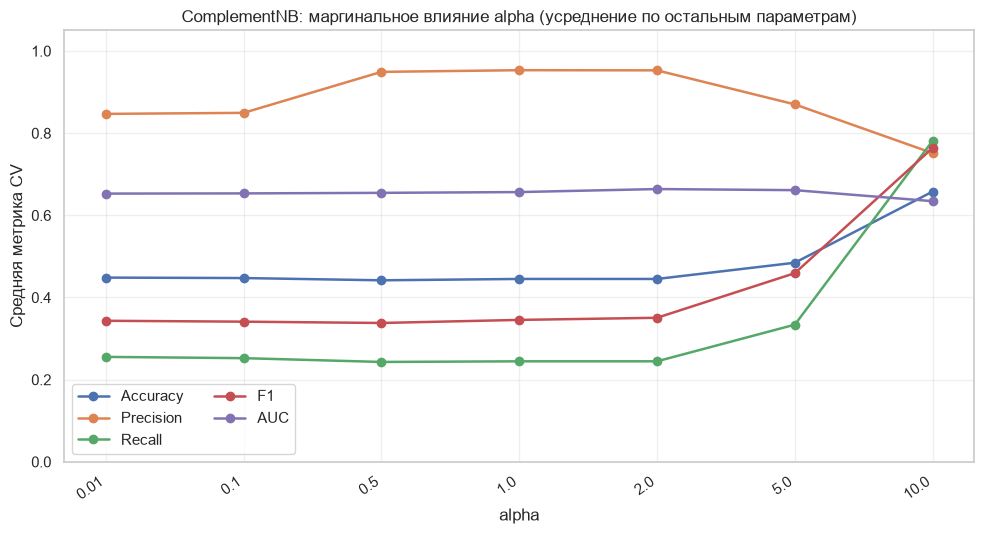

Маргинальные средние для параметра alpha:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
0.01,0.4484,0.8469,0.2554,0.3433,0.6529
0.1,0.4473,0.8494,0.2523,0.3411,0.6534
0.5,0.4418,0.9492,0.2431,0.3379,0.6547
1.0,0.4451,0.9533,0.2446,0.3454,0.6566
2.0,0.4451,0.9529,0.2446,0.3506,0.6640
5.0,0.4846,0.8701,0.3338,0.4592,0.6613
10.0,0.6578,0.7514,0.7815,0.7642,0.6345


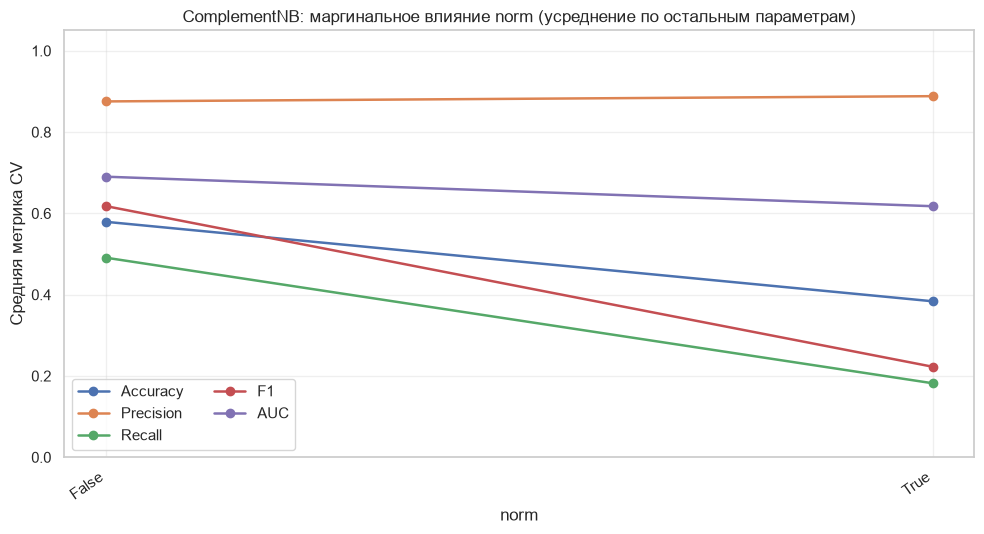

Маргинальные средние для параметра norm:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
False,0.5792,0.8754,0.491,0.6179,0.6902
True,0.3837,0.8883,0.182,0.2226,0.6176



Метрики лучшей комбинации на отложенной тестовой выборке:


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best),Best parameter
0,0.7018,0.9434,0.6173,0.7463,0.8186,0.9091,0.7632,0.5987,0.7097,"{'classifier__alpha': 0.01, 'classifier__norm': False}"


In [50]:
gs_cnb = joint_grid_search(
    name="ComplementNB",
    estimator=ComplementNB(),
    scaling="minmax",
    param_grid={
        "classifier__alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
        "classifier__norm": [False, True],
    },
    param_names=["alpha", "norm"],
)


Сетка: alpha ∈ {0.1, 0.5, 1, 2, 5} и binarize ∈ {0, 0.5, 1, 1.5} и fit_prior ∈ {True, False} - 40 комбинаций.

- binarize - главный параметр. Пороги 0 и 0.5 (т.е. «выше среднего» и «выше среднего на пол-сигмы») дают близкое качество, а при порогах 1 и 1.5 AUC резко падает (≈ −0.09…−0.10). Из-за правосторонней асимметрии признаков значения выше +1σ имеют лишь немногие пациенты, и бинаризация оставляет почти все объекты «нулями», теряя информацию.
- alpha практически не влияет.
- fit_prior: AUC одинаков (0.655), но решения различаются: True - Accuracy 0.679, Precision 0.749, Recall 0.841, F1 0.786; False - Accuracy 0.534, Precision 0.891, Recall 0.405, F1 0.538. Как и в Multinomial, априорные вероятности сдвигают порог.
- Среди сеток с binarize=0 ROC-AUC различается между комбинациями всего на 0.001–0.002 (0.7054–0.7068).

Лучший вариант и тест. alpha=1.0, binarize=0.0, fit_prior=True (при равном AUC выбран вариант с True): CV ROC-AUC 0.7068, Accuracy 0.6512, Precision 0.8058, Recall 0.6738, F1 0.7338. Эти значения совпадают с параметрами по умолчанию, поэтому тестовые метрики не изменились (Accuracy 0.719, Precision 0.818, Recall 0.778, F1 0.797, ROC-AUC 0.798, Specificity 0.576; TN 19, FP 14, FN 18, TP 63): все дельты равны нулю.

### Decision Tree

**Исследуемые параметры**

- criterion - критерий разбиения (gini или entropy).
- max_depth - максимальная глубина дерева; ограничение глубины помогает уменьшать переобучение.
- min_samples_leaf - минимальное количество объектов в листе; увеличение параметра делает правила менее детализированными.
- class_weight - обычные веса (None) или balanced, компенсирующие дисбаланс классов.


BernoulliNB: совместный перебор гиперпараметров
Число проверенных комбинаций: 40
Лучшие параметры по среднему CV ROC-AUC: {'classifier__alpha': 1.0, 'classifier__binarize': 0.0, 'classifier__fit_prior': True}
Лучший средний CV ROC-AUC: 0.7068

Таблица всех комбинаций (средние метрики по 5 фолдам):


,alpha,binarize,fit_prior,CV Accuracy,CV Precision,CV Recall,CV F1,CV AUC,Ранг по ROC-AUC
17,1.0,0.0,False,0.5921,0.8872,0.4923,0.6309,0.7068,1
16,1.0,0.0,True,0.6512,0.8058,0.6738,0.7338,0.7068,1
24,2.0,0.0,True,0.6577,0.8049,0.6862,0.7406,0.7066,3
25,2.0,0.0,False,0.5921,0.8872,0.4923,0.6309,0.7066,3
9,0.5,0.0,False,0.5965,0.8881,0.4985,0.6363,0.7063,5
8,0.5,0.0,True,0.6534,0.8115,0.6708,0.7341,0.7063,5
0,0.1,0.0,True,0.6512,0.8082,0.6708,0.7329,0.7058,7
1,0.1,0.0,False,0.5965,0.8881,0.4985,0.6363,0.7058,7
33,5.0,0.0,False,0.5877,0.8903,0.4831,0.6240,0.7054,9
32,5.0,0.0,True,0.6577,0.7953,0.6985,0.7432,0.7054,9


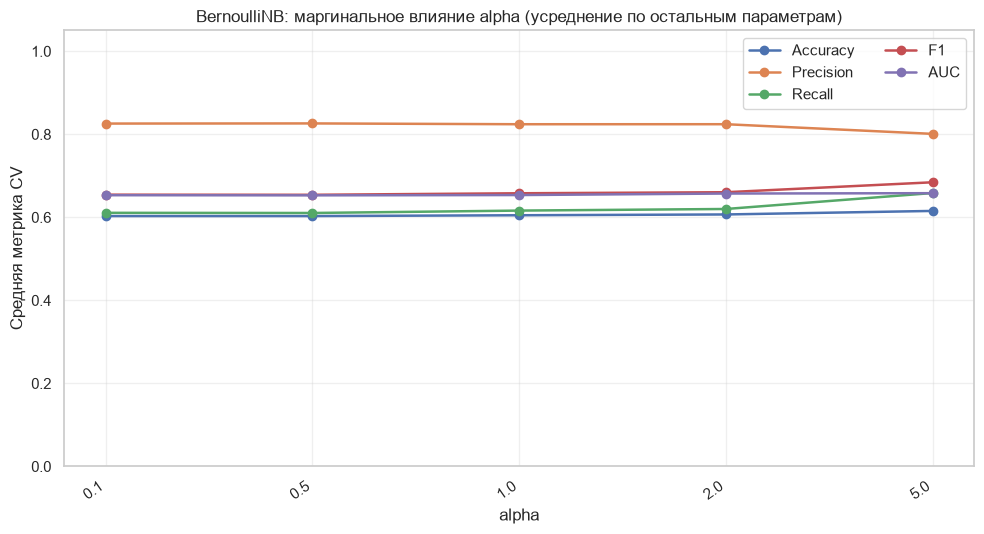

Маргинальные средние для параметра alpha:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
0.1,0.6030,0.8257,0.6108,0.6545,0.6532
0.5,0.6030,0.8261,0.6104,0.6542,0.6529
1.0,0.6049,0.8241,0.6162,0.6579,0.6536
2.0,0.6068,0.8242,0.6200,0.6604,0.6572
5.0,0.6153,0.8009,0.6585,0.6843,0.6581


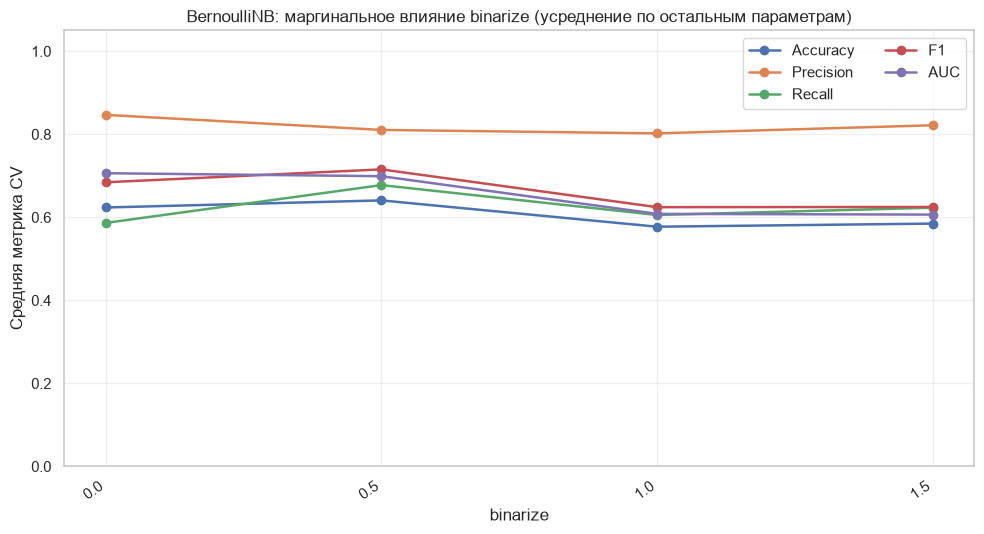

Маргинальные средние для параметра binarize:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
0.0,0.6236,0.8467,0.5865,0.6843,0.7062
0.5,0.6407,0.8105,0.6775,0.7154,0.6990
1.0,0.5773,0.8021,0.6055,0.6244,0.6082
1.5,0.5848,0.8217,0.6231,0.6249,0.6065


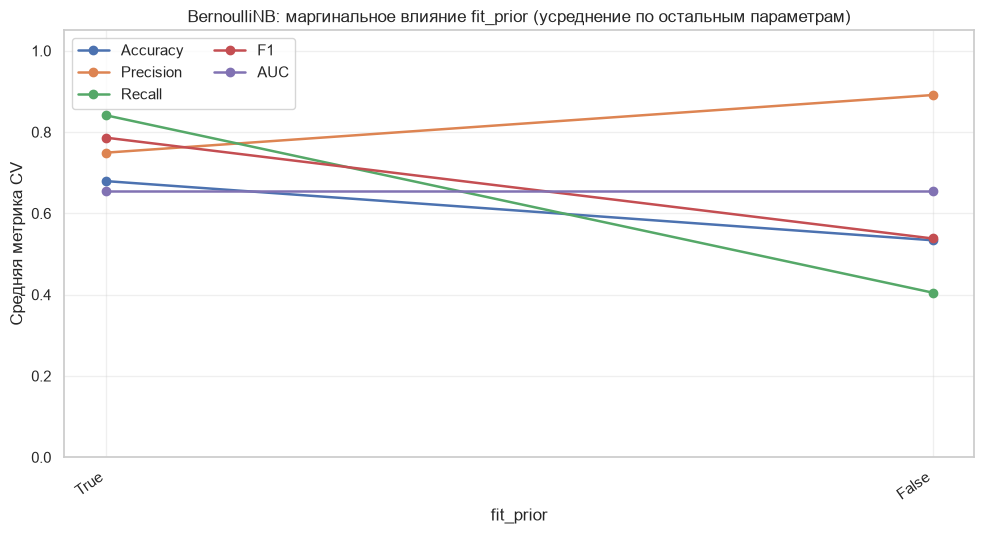

Маргинальные средние для параметра fit_prior:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
True,0.6794,0.7493,0.8414,0.7863,0.655
False,0.5338,0.8912,0.4049,0.5382,0.655



Метрики лучшей комбинации на отложенной тестовой выборке:


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best),Best parameter
0,0.7193,0.8182,0.7778,0.7975,0.798,0.5758,0.6768,0.6579,0.7068,"{'classifier__alpha': 1.0, 'classifier__binarize': 0.0, 'classifier__fit_prior': True}"


In [ ]:
gs_bnb = joint_grid_search(
    name="BernoulliNB",
    estimator=BernoulliNB(),
    scaling="standard",
    param_grid={
        "classifier__alpha": [0.1, 0.5, 1.0, 2.0, 5.0],
        "classifier__binarize": [0.0, 0.5, 1.0, 1.5],
        "classifier__fit_prior": [True, False],
    },
    param_names=["alpha", "binarize", "fit_prior"],
)



Decision Tree: совместный перебор гиперпараметров
Число проверенных комбинаций: 112
Лучшие параметры по среднему CV ROC-AUC: {'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 20}
Лучший средний CV ROC-AUC: 0.7055

Таблица всех комбинаций (средние метрики по 5 фолдам):


,criterion,max_depth,min_samples_leaf,class_weight,CV Accuracy,CV Precision,CV Recall,CV F1,CV AUC,Ранг по ROC-AUC
95,entropy,4.0,20,balanced,0.6382,0.8617,0.5877,0.6971,0.7055,1
67,gini,4.0,20,balanced,0.6360,0.8470,0.6031,0.7019,0.6967,2
35,entropy,3.0,20,NaN,0.6864,0.7280,0.8954,0.8009,0.6927,3
99,entropy,5.0,20,balanced,0.6294,0.8439,0.5908,0.6920,0.6920,4
63,gini,3.0,20,balanced,0.6053,0.8618,0.5354,0.6543,0.6902,5
...,...,...,...,...,...,...,...,...,...,...
109,entropy,NaN,5,balanced,0.5834,0.7294,0.6554,0.6891,0.5629,108
24,gini,NaN,1,NaN,0.6360,0.7462,0.7415,0.7435,0.5578,109
52,entropy,NaN,1,NaN,0.6404,0.7455,0.7538,0.7485,0.5564,110
25,gini,NaN,5,NaN,0.6446,0.7414,0.7692,0.7545,0.5491,111


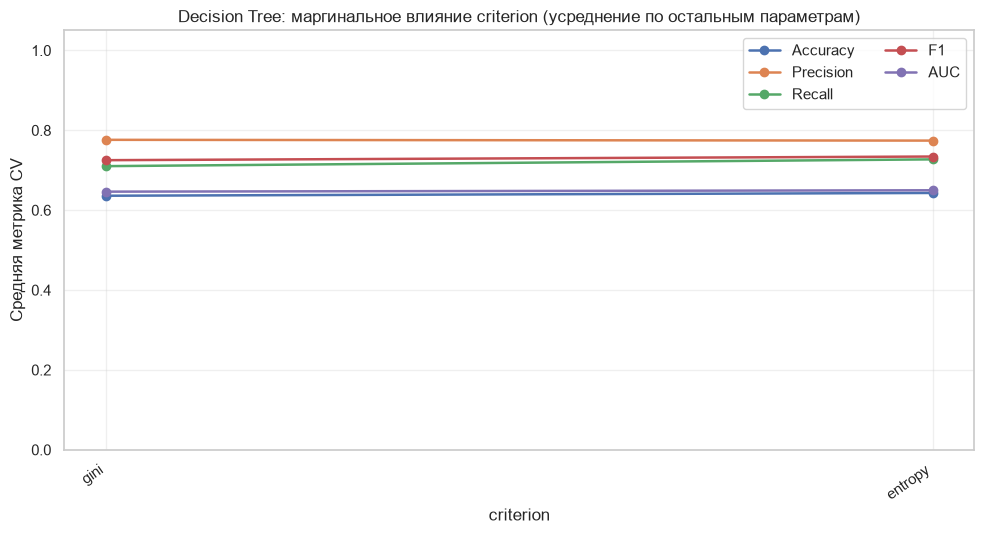

Маргинальные средние для параметра criterion:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
gini,0.6361,0.7761,0.7102,0.7252,0.6464
entropy,0.6431,0.7742,0.7272,0.7343,0.6498


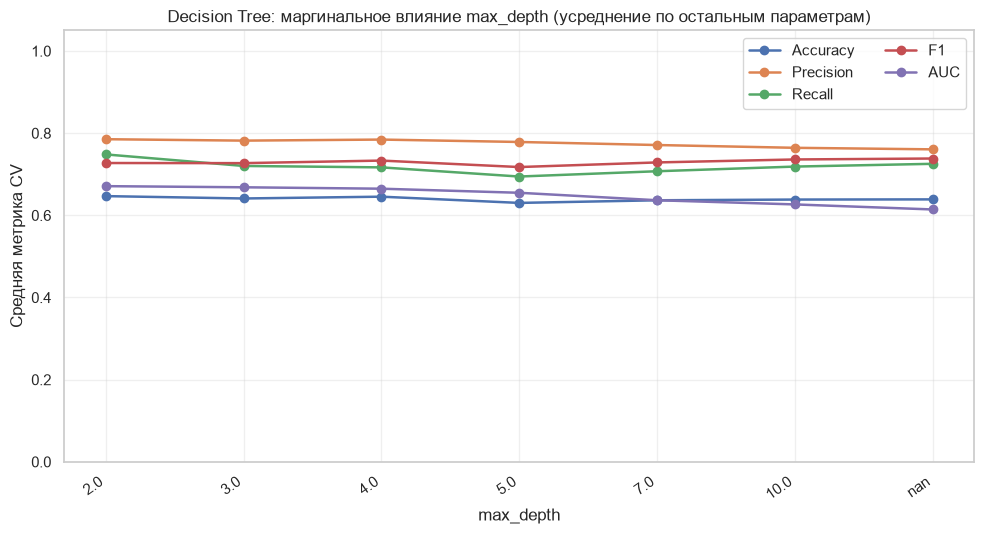

Маргинальные средние для параметра max_depth:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
2.0,0.6468,0.7853,0.7483,0.7273,0.6710
3.0,0.6410,0.7818,0.7202,0.7270,0.6683
4.0,0.6454,0.7844,0.7167,0.7333,0.6648
5.0,0.6302,0.7786,0.6944,0.7175,0.6549
7.0,0.6366,0.7711,0.7073,0.7288,0.6367
10.0,0.6384,0.7644,0.7187,0.7360,0.6265
nan,0.6388,0.7606,0.7254,0.7383,0.6143


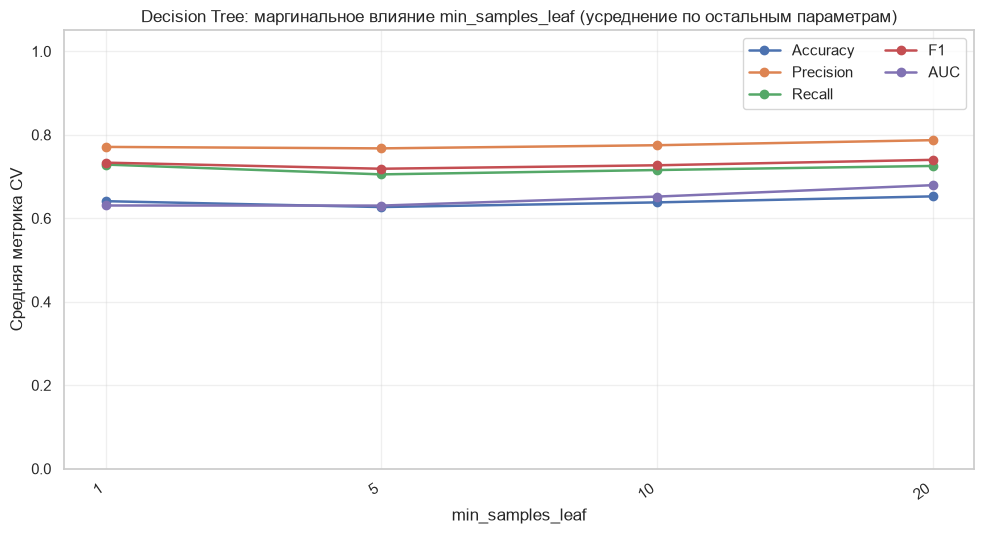

Маргинальные средние для параметра min_samples_leaf:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
1,0.6410,0.7710,0.7287,0.7333,0.6306
5,0.6269,0.7675,0.7052,0.7187,0.6304
10,0.6381,0.7750,0.7156,0.7270,0.6519
20,0.6525,0.7872,0.7254,0.7400,0.6793


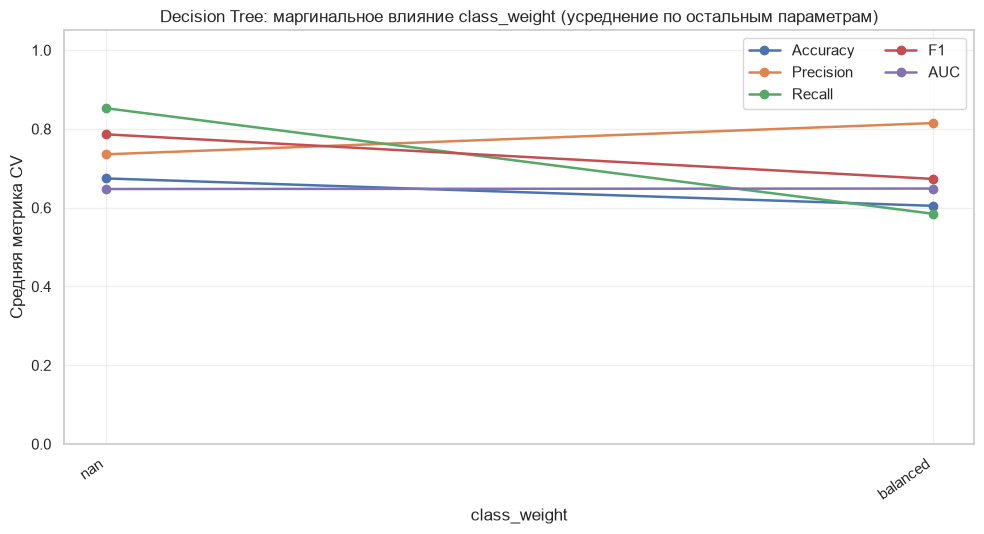

Маргинальные средние для параметра class_weight:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
nan,0.6744,0.7355,0.8527,0.7863,0.6475
balanced,0.6048,0.8148,0.5847,0.6731,0.6487



Метрики лучшей комбинации на отложенной тестовой выборке:


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best),Best parameter
0,0.6842,0.8689,0.6543,0.7465,0.74,0.7576,0.7059,0.6513,0.7055,"{'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 20}"


Фактическая глубина лучшего дерева: 4
Количество листьев: 11


,importance
Direct_Bilirubin,0.480
Age,0.237
Alkaline_Phosphotase,0.146
Aspartate_Aminotransferase,0.053
Total_Protiens,0.043
Albumin_and_Globulin_Ratio,0.040
Gender,0.000
Total_Bilirubin,0.000
Alamine_Aminotransferase,0.000
Albumin,0.000


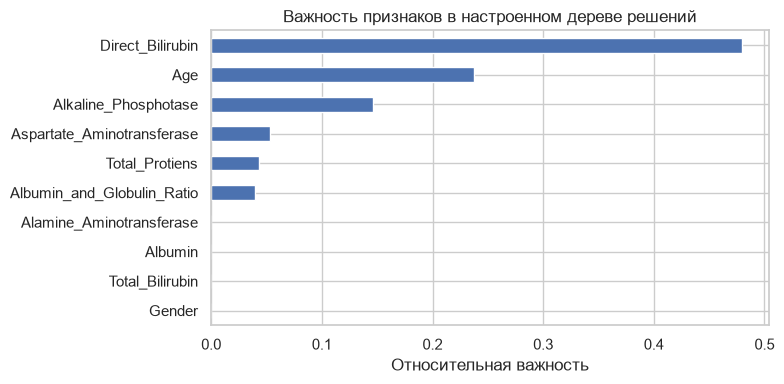

In [52]:
gs_dt = joint_grid_search(
    name="Decision Tree",
    estimator=DecisionTreeClassifier(random_state=SEED),
    scaling="none",
    param_grid={
        "classifier__criterion": ["gini", "entropy"],
        "classifier__max_depth": [2, 3, 4, 5, 7, 10, None],
        "classifier__min_samples_leaf": [1, 5, 10, 20],
        "classifier__class_weight": [None, "balanced"],
    },
    param_names=["criterion", "max_depth", "min_samples_leaf", "class_weight"],
)

dt_best = tuned_models["Decision Tree"].named_steps["classifier"]
print("Фактическая глубина лучшего дерева:", dt_best.get_depth())
print("Количество листьев:", dt_best.get_n_leaves())
importance = pd.Series(dt_best.feature_importances_, index=X.columns).sort_values(ascending=False)
display(importance.to_frame("importance").round(3))
fig, ax = plt.subplots(figsize=(8, 4))
importance.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Важность признаков в настроенном дереве решений")
ax.set_xlabel("Относительная важность")
plt.tight_layout()
plt.show()


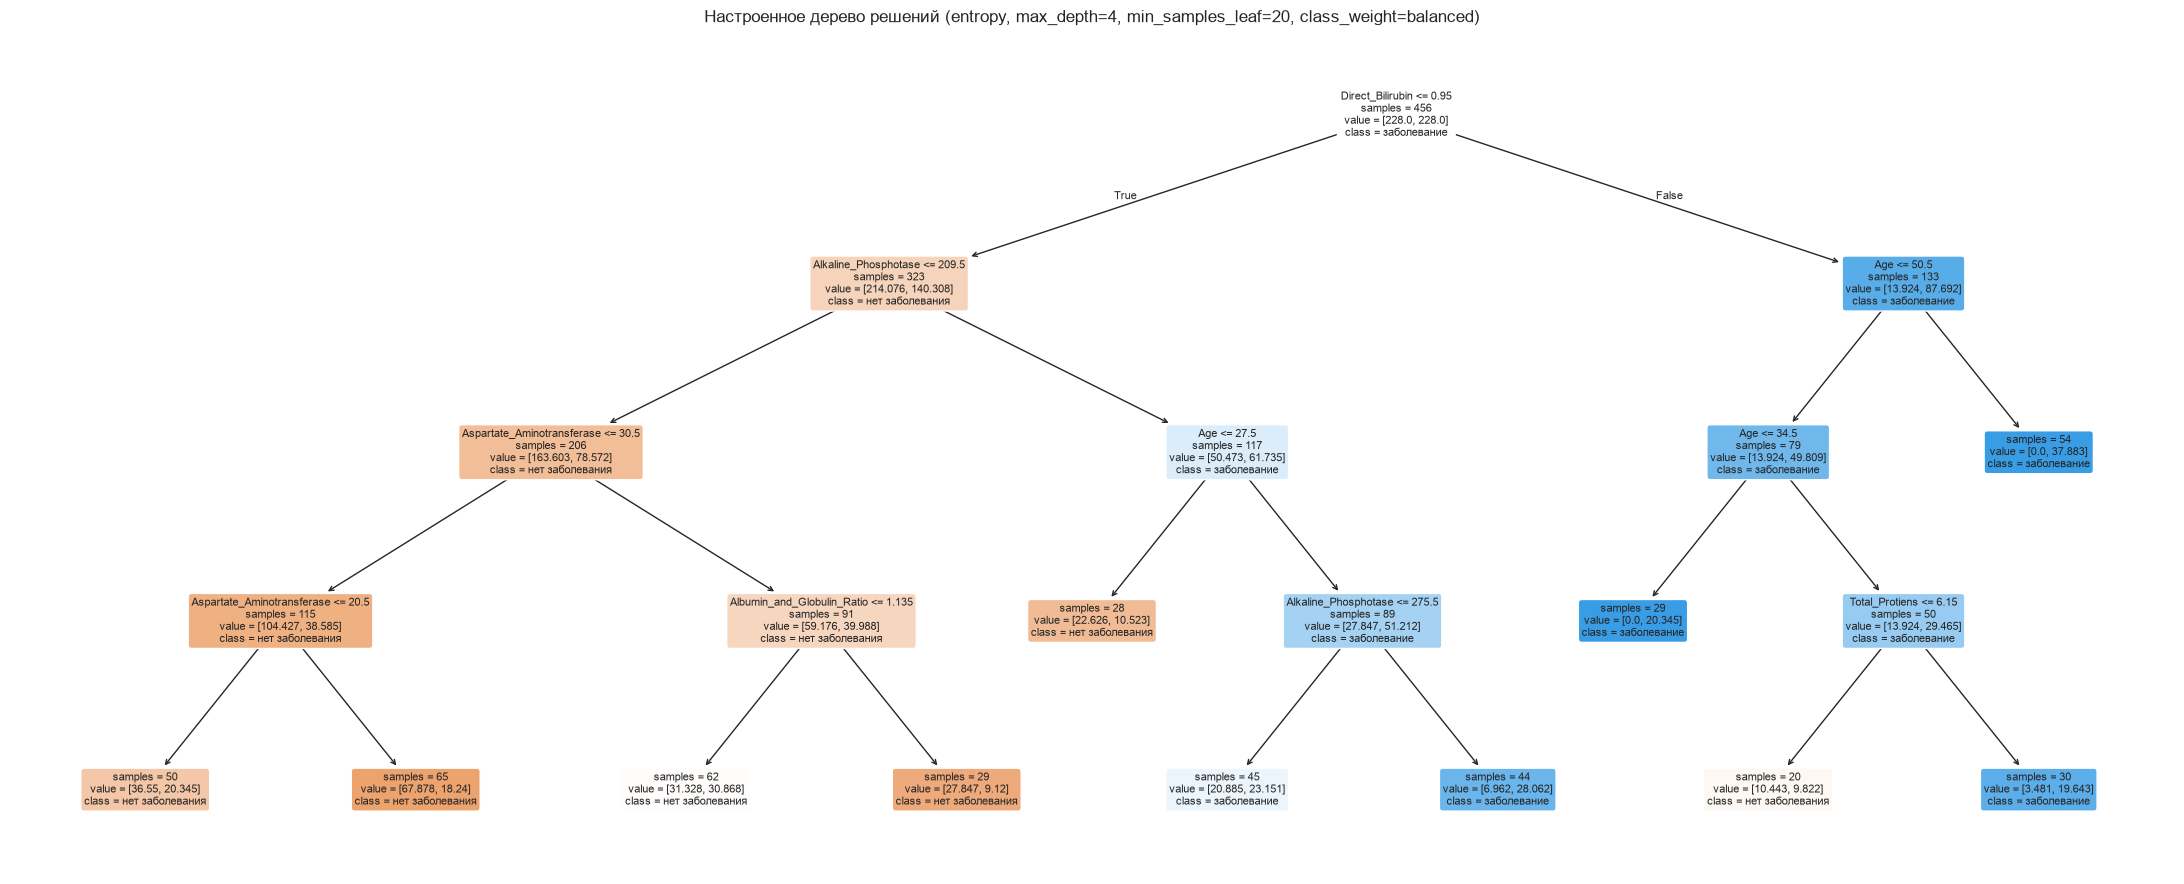

In [53]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(dt_best, feature_names=list(X.columns), class_names=['нет заболевания', 'заболевание'],
          filled=True, rounded=True, impurity=False, proportion=False, fontsize=8, ax=ax)
ax.set_title('Настроенное дерево решений (entropy, max_depth=4, min_samples_leaf=20, class_weight=balanced)')
plt.tight_layout()
plt.show()


Сетка: criterion ∈ {gini, entropy} и max_depth ∈ {2, 3, 4, 5, 7, 10, None} и min_samples_leaf ∈ {1, 5, 10, 20} и class_weight ∈ {None, balanced} - 112 комбинаций.

- max_depth: качество монотонно падает с ростом глубины* - типичное переобучение: чем глубже дерево, тем сильнее оно подстраивается под шум.
- min_samples_leaf: чем больше объектов обязано быть в листе, тем устойчивее оценки вероятностей и тем лучше ROC-AUC (аналог регуляризации). Лучшее значение лежит на краю сетки.
- criterion: gini 0.6464, entropy 0.6498 - различие 0.003, в пределах шума.
- class_weight: AUC почти одинаков (0.6475 и 0.6487), но решения иные: без весов Accuracy 0.674, Precision 0.736, Recall 0.853, F1 0.786; с balanced - Accuracy 0.605, Precision 0.815, Recall 0.585, F1 0.673. Баланс весов повышает Precision и Specificity ценой Recall.
- При min_samples_leaf = 20 глубины 7, 10 и без ограничения дают идентичные результаты (AUC 0.6882): большие листья сами ограничивают рост дерева.
- Худшие комбинации - полностью выращенные деревья (max_depth=None, min_samples_leaf 1 или 5): CV ROC-AUC 0.549–0.563, т.е. около случайного уровня.

Лучший вариант: criterion=entropy, max_depth=4, min_samples_leaf=20, class_weight=balanced - CV ROC-AUC 0.7055 (на 0.15 выше худших комбинаций), Accuracy 0.6382, Precision 0.8617, Recall 0.5877, F1 0.6971.

Структура итогового дерева -  глубина 4, 11 листьев. Важность признаков: Direct_Bilirubin - 0.480, Age - 0.237, Alkaline_Phosphotase - 0.146, Aspartate_Aminotransferase - 0.053, Total_Protiens - 0.043, Albumin_and_Globulin_Ratio - 0.040; а Gender, Total_Bilirubin, Alamine_Aminotransferase, Albumin - 0.

Корень - Direct_Bilirubin ≤ 0.95: правая ветвь (высокий прямой билирубин, 133 обучающих объекта) почти целиком состоит из больных, а при возрасте > 50.5 лет - это «чистый» лист из больных (54 объекта). Левая ветвь (низкий билирубин) делится по щелочной фосфатазе (≤ 209.5), АСТ (≤ 30.5, ≤ 20.5), возрасту (≤ 27.5) и отношению альбумин/глобулин; листья с низкой АСТ (≤ 30.5) и низкой фосфатазой классифицируются как «нет заболевания», как и самые молодые пациенты (≤ 27.5 лет) с низким билирубином, но повышенной щелочной фосфатазой (лист из 28 объектов). Правила клинически осмысленны: повышенные билирубин, щелочная фосфатаза и АСТ и более старший возраст сигнализируют о болезни. (Числа в узлах value - объёмы классов с учётом class_weight, поэтому в корне 228/228.)

 Accuracy 0.684, Precision 0.869, Recall 0.654, F1 0.747, ROC-AUC 0.740, Specificity 0.758 (TN 25, FP 8, FN 28, TP 53); точность на обучении 0.651 против 1.000 у базового дерева.

Ограничение глубины и размера листа превратило переобученное дерево (train 1.00 / test 0.62, AUC 0.555) в стабильную интерпретируемую модель (train 0.65 / test 0.68, AUC 0.74), которая по Balanced Accuracy (0.706) уступает лишь ComplementNB и GaussianNB.

### Linear Discriminant Analysis

**Изменяемые параметры**

- shrinkage - он управляет регуляризацией оценки ковариационной матрицы. Значение None означает отсутствие shrinkage; auto использует автоматическую оценку; числовые значения от 0 до 1 определяют степень сжатия ковариационной матрицы к диагональной.



LDA: совместный перебор гиперпараметров
Число проверенных комбинаций: 7
Лучшие параметры по среднему CV ROC-AUC: {'classifier__shrinkage': 0.7}
Лучший средний CV ROC-AUC: 0.7010

Таблица всех комбинаций (средние метрики по 5 фолдам):


,shrinkage,CV Accuracy,CV Precision,CV Recall,CV F1,CV AUC,Ранг по ROC-AUC
5,0.7,0.6952,0.7337,0.8985,0.8073,0.7010,1
6,0.9,0.6885,0.7452,0.8554,0.7957,0.6996,2
4,0.5,0.6952,0.7267,0.9169,0.8101,0.6943,3
3,0.3,0.6820,0.7141,0.9231,0.8048,0.6917,4
1,auto,0.6864,0.7147,0.9323,0.8087,0.6899,5
2,0.1,0.6908,0.7160,0.9385,0.8120,0.6875,6
0,None,0.6930,0.7168,0.9415,0.8136,0.6795,7


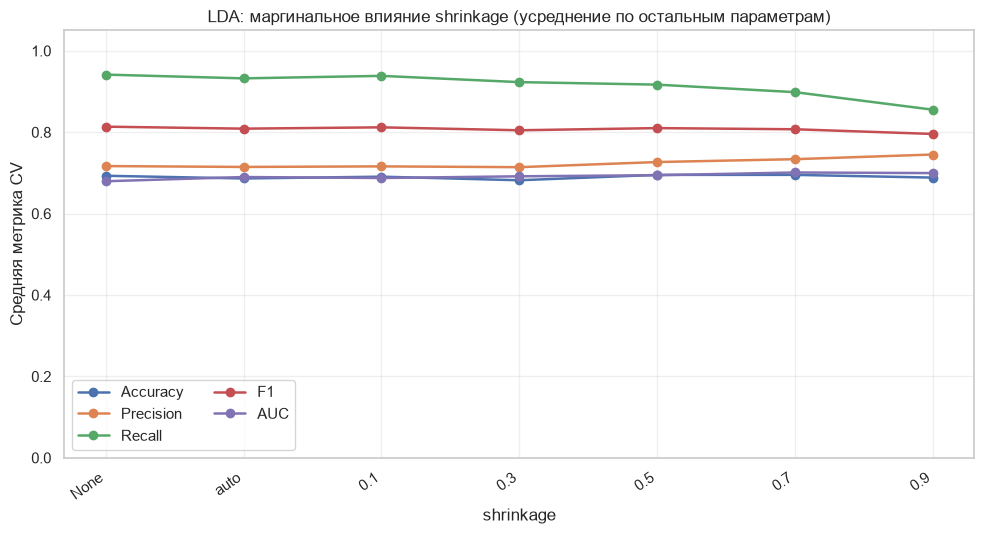

Маргинальные средние для параметра shrinkage:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
None,0.6930,0.7168,0.9415,0.8136,0.6795
auto,0.6864,0.7147,0.9323,0.8087,0.6899
0.1,0.6908,0.7160,0.9385,0.8120,0.6875
0.3,0.6820,0.7141,0.9231,0.8048,0.6917
0.5,0.6952,0.7267,0.9169,0.8101,0.6943
0.7,0.6952,0.7337,0.8985,0.8073,0.7010
0.9,0.6885,0.7452,0.8554,0.7957,0.6996



Метрики лучшей комбинации на отложенной тестовой выборке:


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best),Best parameter
0,0.7281,0.75,0.9259,0.8287,0.7853,0.2424,0.5842,0.6952,0.701,{'classifier__shrinkage': 0.7}


In [54]:
gs_lda = joint_grid_search(
    name="LDA",
    estimator=LinearDiscriminantAnalysis(solver="lsqr"),
    scaling="standard",
    param_grid={"classifier__shrinkage": [None, "auto", 0.1, 0.3, 0.5, 0.7, 0.9]},
    param_names=["shrinkage"],
)


Перебирались 7 значений: None, auto, 0.1, 0.3, 0.5, 0.7, 0.9.

- ROC-AUC растёт при усилении регуляризации. Выигрыш относительно LDA без регуляризации - 0.0215, но он меньше разброса между блоками (≈ 0.05).
- При росте `hrinkage Recall в целом падает (0.9415 → 0.8554), а Precision растёт (0.7168 → 0.7452); Accuracy почти постоянна (0.682–0.695), F1 колеблется в 0.796–0.814.

Лучший вариант:shrinkage = 0.7 - CV Accuracy 0.6952, Precision 0.7337, Recall 0.8985, F1 0.8073, ROC-AUC 0.7010.

Accuracy 0.728 (лучшая среди всех настроенных моделей), Precision 0.750, Recall 0.926, F1 0.829, ROC-AUC 0.785, Specificity 0.242 (TN 8, FP 25, FN 6, TP 75). 

### Support Vector Machines

**Исследуемые параметры**

- C - сила штрафа за ошибки и нарушения зазора. При малом C модель допускает больше нарушений; при слишком большом может сильнее подстраиваться под отдельные наблюдения.
- kernel - линейная или RBF-граница.
- gamma - параметр ширины влияния объектов для RBF-ядра; для линейного ядра он не используется.



SVM (RBF): совместный перебор гиперпараметров
Число проверенных комбинаций: 24
Лучшие параметры по среднему CV ROC-AUC: {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}
Лучший средний CV ROC-AUC: 0.7028

Таблица всех комбинаций (средние метрики по 5 фолдам):


,C,kernel,gamma,CV Accuracy,CV Precision,CV Recall,CV F1,CV AUC,Ранг по ROC-AUC
12,10.0,linear,scale,0.7127,0.7127,1.0000,0.8323,0.7028,1
14,10.0,linear,0.01,0.7127,0.7127,1.0000,0.8323,0.7028,1
16,10.0,linear,0.1,0.7127,0.7127,1.0000,0.8323,0.7028,1
19,50.0,rbf,scale,0.6906,0.7492,0.8492,0.7953,0.6672,4
23,50.0,rbf,0.1,0.6906,0.7492,0.8492,0.7953,0.6672,4
15,10.0,rbf,0.01,0.7127,0.7127,1.0000,0.8323,0.6601,6
21,50.0,rbf,0.01,0.7040,0.7143,0.9754,0.8244,0.6594,7
9,1.0,rbf,0.01,0.7127,0.7127,1.0000,0.8323,0.6578,8
0,0.1,linear,scale,0.7127,0.7127,1.0000,0.8323,0.6571,9
2,0.1,linear,0.01,0.7127,0.7127,1.0000,0.8323,0.6571,9


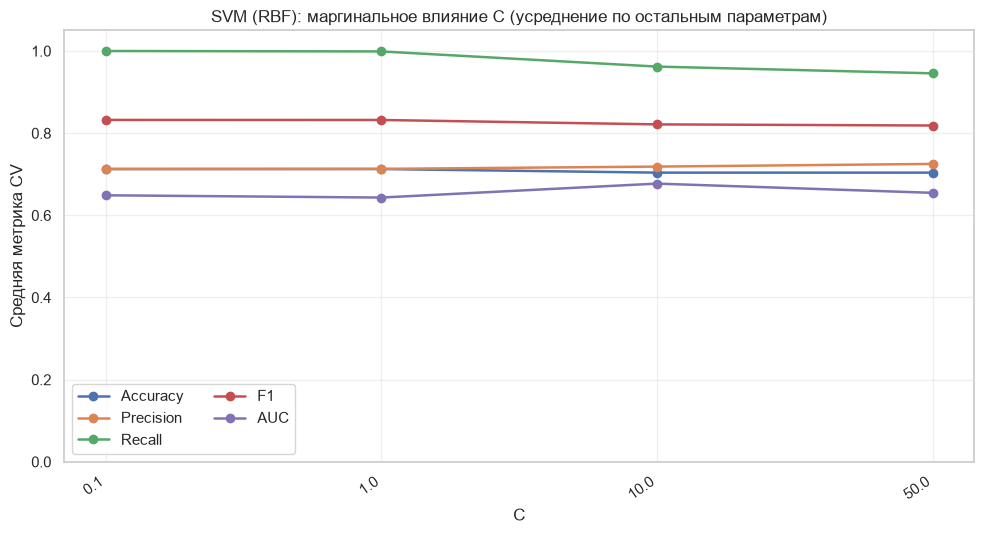

Маргинальные средние для параметра C:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
0.1,0.7127,0.7127,1.0000,0.8323,0.6488
1.0,0.7127,0.7131,0.9990,0.8321,0.6433
10.0,0.7039,0.7186,0.9621,0.8214,0.6772
50.0,0.7039,0.7251,0.9456,0.8186,0.6547


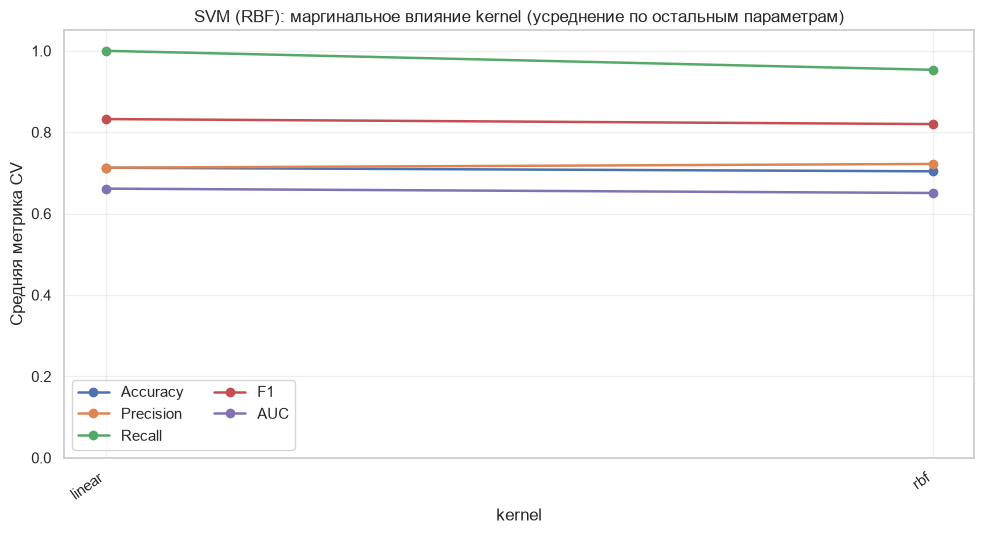

Маргинальные средние для параметра kernel:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
linear,0.7127,0.7127,1.0000,0.8323,0.6613
rbf,0.7039,0.7220,0.9533,0.8199,0.6507


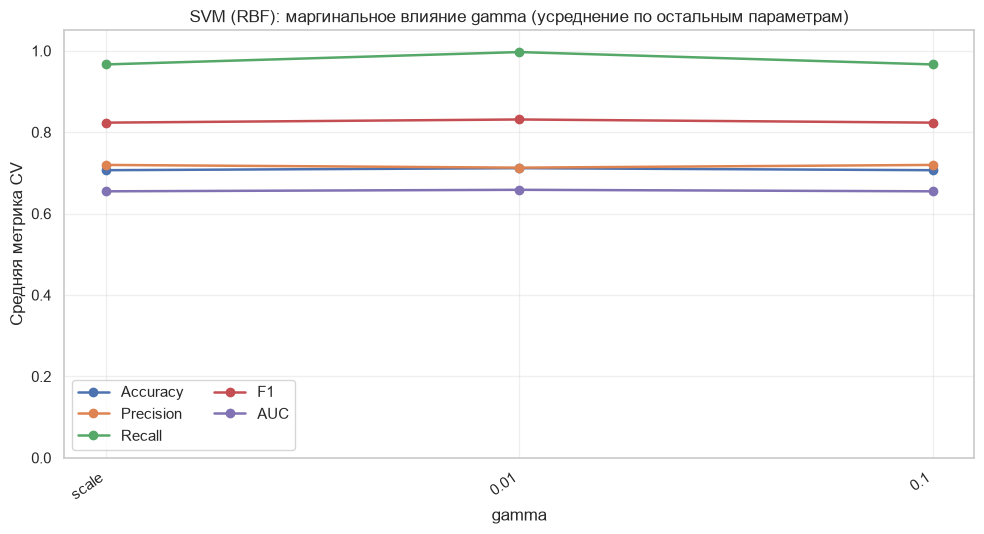

Маргинальные средние для параметра gamma:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
scale,0.7067,0.7196,0.9665,0.8235,0.6548
0.01,0.7116,0.7129,0.9969,0.8313,0.6585
0.1,0.7067,0.7196,0.9665,0.8235,0.6548



Метрики лучшей комбинации на отложенной тестовой выборке:


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best),Best parameter
0,0.7105,0.7105,1.0,0.8308,0.7325,0.0,0.5,0.7127,0.7028,"{'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}"


In [55]:
gs_svm = joint_grid_search(
    name="SVM (RBF)",
    estimator=SVC(probability=True, random_state=SEED),
    scaling="standard",
    param_grid={
        "classifier__C": [0.1, 1, 10, 50],
        "classifier__kernel": ["linear", "rbf"],
        "classifier__gamma": ["scale", 0.01, 0.1],
    },
    param_names=["C", "kernel", "gamma"],
)


Сетка: C ∈ {0.1, 1, 10, 50} и kernel ∈ {linear, rbf} и gamma ∈ {scale, 0.01, 0.1} - 24 комбинации. 

- C (маргинальный ROC-AUC):** 0.1 → 0.649, 1 → 0.643, 10 → 0.677, 50 → 0.655. Оптимум в середине сетки: слишком малый C даёт чрезмерно мягкую границу, слишком большой - подгоняет границу под обучающие объекты.
- kernel: linear 0.661 против rbf 0.651 - линейная граница немного лучше ранжирует; нелинейность RBF-ядра на таких данных (сильное перекрытие классов) не даёт выигрыша.
- gamma: scale и 0.1 дают одинаковые результаты (0.655), так как для стандартизованных 10 признаков gamma= scale равна 1/(10·1) = 0.1; для 0.01 - 0.659. 

Лучший вариант: C=10, kernel='linear - CV ROC-AUC 0.703, но при этом Accuracy 0.7127, Precision 0.7127, Recall 1.000.

Тест. Accuracy 0.711, Precision 0.711, Recall 1.000, F1 0.831, ROC-AUC 0.733.

Настройка заметно улучшила ранжирование, но SVM без class_weight='balanced остаётся вырожденным классификатором. 

### k-Nearest Neighbors

**Исследуемые параметры**

- n_neighbors - число соседей k. Малые значения чувствительны к шуму; большие сильнее сглаживают границу и могут смещать прогноз к преобладающему классу.
- weights - равный голос соседей (uniform) либо больший вес ближайших (distance).
- metric - используемая метрика расстояния (euclidean, manhattan, chebyshev).


kNN: совместный перебор гиперпараметров
Число проверенных комбинаций: 54
Лучшие параметры по среднему CV ROC-AUC: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 31, 'classifier__weights': 'distance'}
Лучший средний CV ROC-AUC: 0.6967

Таблица всех комбинаций (средние метрики по 5 фолдам):


,n_neighbors,weights,metric,CV Accuracy,CV Precision,CV Recall,CV F1,CV AUC,Ранг по ROC-AUC
35,31,distance,manhattan,0.7083,0.7277,0.9446,0.8219,0.6967,1
34,31,uniform,manhattan,0.6951,0.7203,0.9354,0.8137,0.6937,2
17,31,distance,euclidean,0.6951,0.7183,0.9415,0.8147,0.6894,3
53,31,distance,chebyshev,0.7127,0.7246,0.9631,0.8269,0.6867,4
16,31,uniform,euclidean,0.6995,0.7157,0.9600,0.8199,0.6866,5
13,15,distance,euclidean,0.6972,0.7391,0.8892,0.8069,0.6852,6
33,21,distance,manhattan,0.7016,0.7322,0.9169,0.8142,0.6847,7
12,15,uniform,euclidean,0.6972,0.7366,0.8954,0.8079,0.6846,8
15,21,distance,euclidean,0.6951,0.7278,0.9138,0.8101,0.6815,9
52,31,uniform,chebyshev,0.7061,0.7147,0.9785,0.8259,0.6809,10


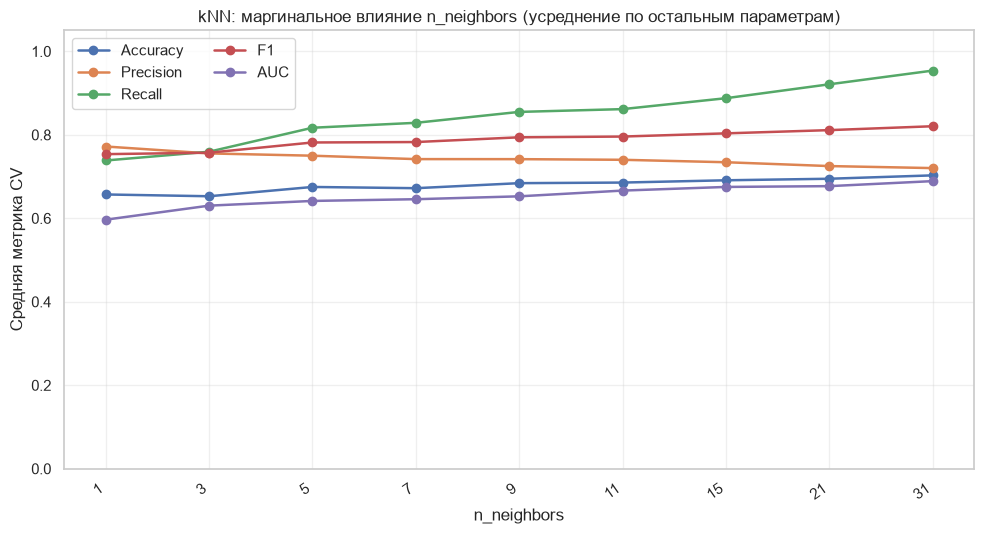

Маргинальные средние для параметра n_neighbors:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
1,0.6570,0.7720,0.7385,0.7537,0.5966
3,0.6528,0.7554,0.7595,0.7571,0.6303
5,0.6750,0.7499,0.8169,0.7816,0.6416
7,0.6721,0.7418,0.8287,0.7826,0.6457
9,0.6841,0.7417,0.8549,0.7940,0.6526
11,0.6856,0.7401,0.8615,0.7958,0.6663
15,0.6910,0.7343,0.8877,0.8035,0.6751
21,0.6947,0.7251,0.9210,0.8112,0.6770
31,0.7028,0.7202,0.9538,0.8205,0.6890


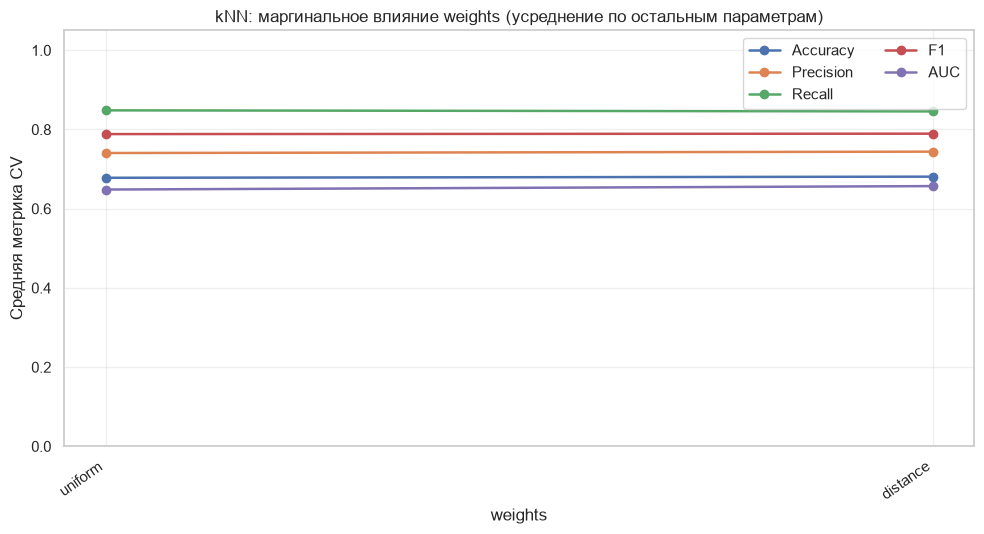

Маргинальные средние для параметра weights:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
uniform,0.6780,0.7405,0.8483,0.7884,0.6484
distance,0.6809,0.7440,0.8456,0.7894,0.6570


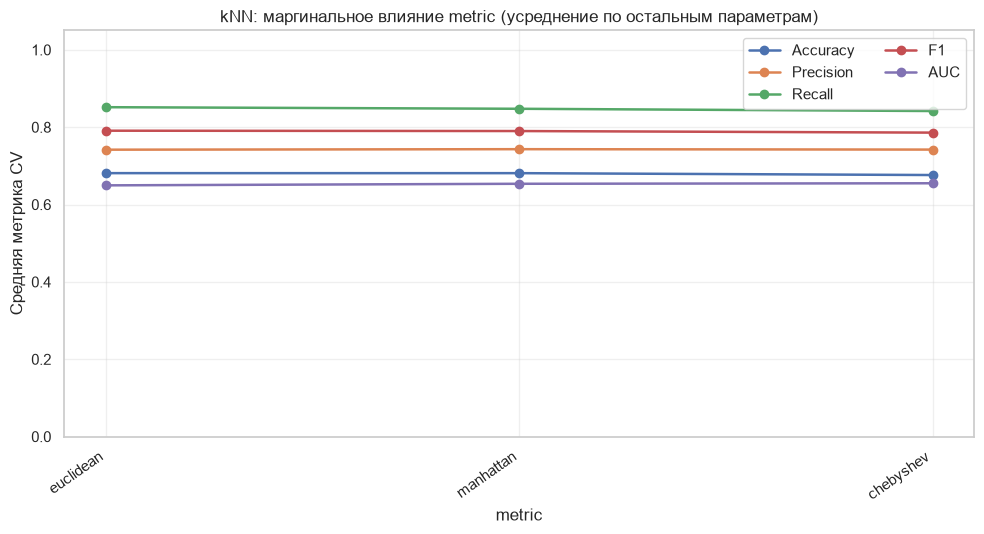

Маргинальные средние для параметра metric:


,Accuracy,Precision,Recall,F1,AUC
_label,,,,,
euclidean,0.6811,0.7418,0.8516,0.7908,0.6495
manhattan,0.6811,0.7431,0.8475,0.7900,0.6536
chebyshev,0.6762,0.7420,0.8417,0.7859,0.6549



Метрики лучшей комбинации на отложенной тестовой выборке:


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best),Best parameter
0,0.7193,0.7333,0.9506,0.828,0.7643,0.1515,0.5511,1.0,0.6967,"{'classifier__metric': 'manhattan', 'classifier__n_neighbors': 31, 'classifier__weights': 'distance'}"


In [56]:
gs_knn = joint_grid_search(
    name="kNN",
    estimator=KNeighborsClassifier(),
    scaling="standard",
    param_grid={
        "classifier__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31],
        "classifier__weights": ["uniform", "distance"],
        "classifier__metric": ["euclidean", "manhattan", "chebyshev"],
    },
    param_names=["n_neighbors", "weights", "metric"],
)


Сетка: n_neighbors ∈ {1, 3, 5, 7, 9, 11, 15, 21, 31} и weights ∈ {uniform, distance} и metric ∈ {euclidean, manhattan, chebyshev} - 54 комбинации.

- n_neighbors - доминирующий параметр, эффект монотонный. Маргинальный ROC-AUC: k=1 - 0.597, 3 - 0.630, 5 - 0.642, 7 - 0.646, 9 - 0.653, 11 - 0.666, 15 - 0.675, 21 - 0.677, 31 - 0.689. Одновременно Accuracy растёт с 0.657 до 0.703, Recall - с 0.739 до 0.954, а Precision падает с 0.772 до 0.720. То есть с ростом k модель постепенно скатывается к большинству (Precision → 0.71, Recall → 1.0) - выигрыш AUC и Accuracy достигается за счёт вырождения решений.
- weights: uniform 0.648, distance 0.657 (разница 0.009). metric: euclidean 0.650, manhattan 0.654, chebyshev 0.655 - различие 0.005, т.е. метрика на результат практически не влияет.

Лучший вариант: metric='manhattan, n_neighbors=31, weights='distance - CV Accuracy 0.7083, Precision 0.7277, Recall 0.9446, F1 0.8219, ROC-AUC 0.6967.

Тест. Accuracy 0.719, Precision 0.733, Recall 0.951, F1 0.828, ROC-AUC 0.764, Specificity 0.152 (TN 5, FP 28, FN 4, TP 77). 

Вывод. Базовая модель с k=5 была слишком чувствительна к шуму; увеличение k существенно улучшило ранжирование.

### Итоговая таблица

Сводка лучших совместных комбинаций параметров (выбор по среднему CV ROC-AUC):


,Лучшие параметры,Число комбинаций,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
Модель,,,,,,,
GaussianNB,{'classifier__var_smoothing': np.float64(0.01)},12,0.5218,0.9485,0.3477,0.5039,0.7151
MultinomialNB,"{'classifier__alpha': 0.01, 'classifier__fit_prior': True}",14,0.7127,0.7127,1.0000,0.8323,0.7097
ComplementNB,"{'classifier__alpha': 0.01, 'classifier__norm': False}",14,0.5833,0.8939,0.4738,0.6167,0.7097
BernoulliNB,"{'classifier__alpha': 1.0, 'classifier__binarize': 0.0, 'classifier__fit_prior': True}",40,0.6512,0.8058,0.6738,0.7338,0.7068
Decision Tree,"{'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 20}",112,0.6382,0.8617,0.5877,0.6971,0.7055
SVM (RBF),"{'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}",24,0.7127,0.7127,1.0000,0.8323,0.7028
LDA,{'classifier__shrinkage': 0.7},7,0.6952,0.7337,0.8985,0.8073,0.7010
kNN,"{'classifier__metric': 'manhattan', 'classifier__n_neighbors': 31, 'classifier__weights': 'distance'}",54,0.7083,0.7277,0.9446,0.8219,0.6967



Изменение тестовых метрик после настройки (настроенная минус базовая модель):


,Выбранный параметр,Δ Accuracy,Δ Precision,Δ Recall,Δ F1,Δ AUC
Модель,,,,,,
GaussianNB,{'classifier__var_smoothing': np.float64(0.01)},-0.018,0.000,-0.025,-0.024,0.005
MultinomialNB,"{'classifier__alpha': 0.01, 'classifier__fit_prior': True}",0.000,0.000,0.000,0.000,0.014
ComplementNB,"{'classifier__alpha': 0.01, 'classifier__norm': False}",0.009,-0.017,0.025,0.013,0.014
BernoulliNB,"{'classifier__alpha': 1.0, 'classifier__binarize': 0.0, 'classifier__fit_prior': True}",0.000,0.000,0.000,0.000,0.000
Decision Tree,"{'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 20}",0.061,0.125,-0.062,0.017,0.185
LDA,{'classifier__shrinkage': 0.7},0.026,0.030,-0.025,0.010,0.020
SVM (RBF),"{'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}",0.000,0.000,0.000,0.000,0.078
kNN,"{'classifier__metric': 'manhattan', 'classifier__n_neighbors': 31, 'classifier__weights': 'distance'}",0.026,-0.011,0.086,0.028,0.083


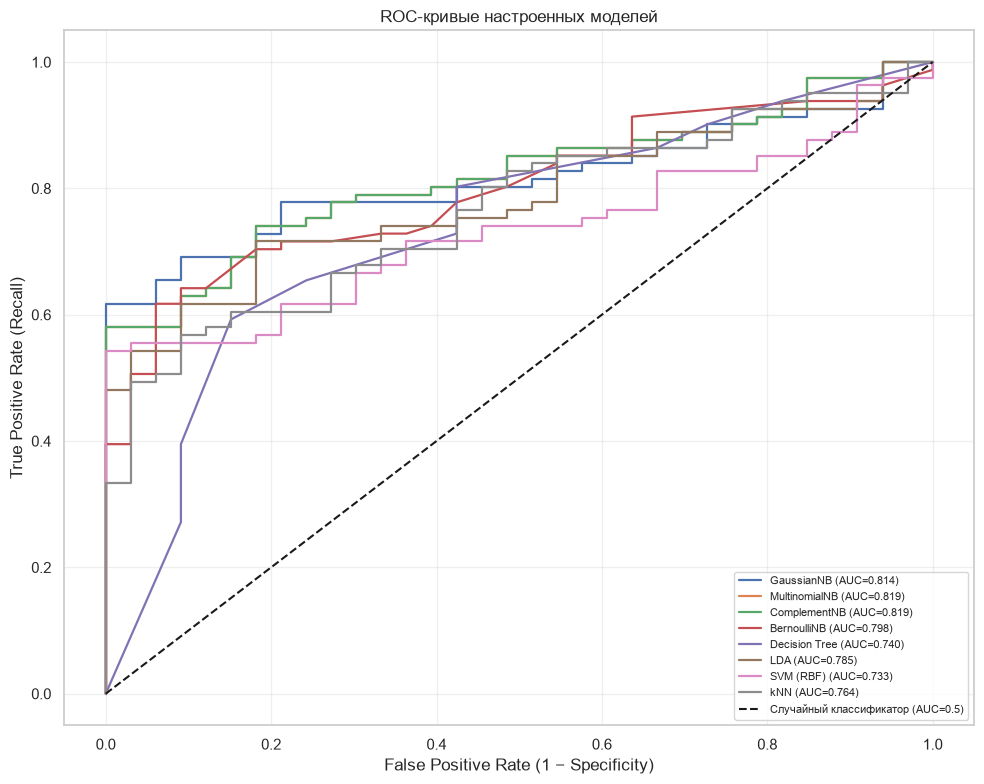

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

core_metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC'] 

joint_summary_rows = []
for name, table in sweep_results.items():
    best_row = table.loc[table["Ранг по ROC-AUC"].idxmin()]
    joint_summary_rows.append({
        "Модель": name,
        "Лучшие параметры": str(tuned_best_params[name]),
        "Число комбинаций": len(table),
        "CV Accuracy": best_row["CV Accuracy"],
        "CV Precision": best_row["CV Precision"],
        "CV Recall": best_row["CV Recall"],
        "CV F1": best_row["CV F1"],
        "CV ROC-AUC": best_row["CV AUC"],
    })
joint_summary_df = pd.DataFrame(joint_summary_rows).set_index("Модель").sort_values("CV ROC-AUC", ascending=False)

pd.set_option('display.max_colwidth', None) 

print("Сводка лучших совместных комбинаций параметров (выбор по среднему CV ROC-AUC):")
display(joint_summary_df.round(4))

delta_rows = []
for name in tuned_df.index:
    row = {"Модель": name, "Выбранный параметр": tuned_df.loc[name, "Best parameter"]}
    for metric in core_metrics:
        if metric in tuned_df.columns and metric in baseline_df.columns:
            row[f"Δ {metric}"] = tuned_df.loc[name, metric] - baseline_df.loc[name, metric]
    delta_rows.append(row)
    
delta_df = pd.DataFrame(delta_rows).set_index("Модель")
print("\nИзменение тестовых метрик после настройки (настроенная минус базовая модель):")
display(delta_df.round(3))

plt.figure(figsize=(10, 8))
for name, model in tuned_models.items():
    fpr, tpr, _ = roc_curve(y_test, get_score(model, X_test))
    plt.plot(fpr, tpr, linewidth=1.6, label=f"{name} (AUC={tuned_df.loc[name, 'AUC']:.3f})")
    
plt.plot([0, 1], [0, 1], "k--", label="Случайный классификатор (AUC=0.5)")
plt.xlabel("False Positive Rate (1 − Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-кривые настроенных моделей")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

(CV-метрики лучшей комбинации каждой модели): выбор по ROC-AUC даёт очень близкие значения - от 0.697 (kNN) до 0.715 (GaussianNB): GaussianNB 0.7151, MultinomialNB 0.7097, ComplementNB 0.7097, BernoulliNB 0.7068, Decision Tree 0.7055, SVM 0.703, LDA 0.7010, kNN 0.6967. Размах - всего 0.018, тогда как стандартное отклонение по блокам равно 0.03–0.07: по кросс-валидации все восемь методов практически неразличимы по ранжированию. Самые большие пространства поиска были у дерева (112 комбинаций) и kNN (54), самое малое - у LDA (7), но число проверенных комбинаций не коррелирует с итоговым качеством.


1. Больше всего выиграли методы, у которых значения по умолчанию были далеки от оптимума: Decision Tree (+0.185 AUC), kNN (+0.083) и SVM (+0.078). Это модели с сильным переобучением по умолчанию (глубокое дерево, k=5, RBF-ядро при C=1), и для них регуляризующие параметры (max_depth, min_samples_leaf, n_neighbors, C) критически важны.
2. Наивные байесовские модели и LDA почти не изменились (±0.02 по AUC): у них мало степеней свободы, и значения по умолчанию близки к оптимальным; у BernoulliNB настройка не изменила ни одной метрики.
3. У MultinomialNB и SVM выросла только ROC-AUC, а пороговые метрики остались тривиальными (Δ = 0): настройка по AUC не меняет порог.
4. Малые приросты ROC-AUC на тесте (+0.005…+0.02 у наивных байесовских моделей и LDA) лежат в пределах статистической погрешности теста из 114 пациентов и не доказывают реального улучшения.

Для всех моделей тестовый ROC-AUC (0.733–0.819) выше CV ROC-AUC (0.697–0.715) на 0.03–0.11. Причина - не «подгонка», а различие выборок: CV обучает на 365 и проверяет на 91 объекте, и оценка на тесте из 114 объектов с 33 здоровыми сильно колеблется (95-процентный интервал AUC примерно ±0.08). Более надёжными следует считать CV-значения (на всех 456 объектах), а различия между моделями в тесте в пределах 0.05 - неразличимыми.

 Все кривые выше диагонали. AUC: MultinomialNB и ComplementNB - 0.819 (кривые совпадают), GaussianNB 0.814, BernoulliNB 0.798, LDA 0.785, kNN 0.764, Decision Tree 0.740, SVM 0.733. Верхнюю группу по-прежнему образуют наивные байесовские модели: GaussianNB и ComplementNB уже при почти нулевой доле ложных тревог находят около 58–62 % больных. Дерево решений на малых FPR заметно ниже (при FPR ≈ 0.09 находит лишь 27–40 % больных), но при FPR > 0.45 сближается с остальными; SVM на большом участке FPR 0.2–0.8 лежит ниже большинства кривых. Кривая дерева - ступенчатая (всего 11 листьев, т.е. не более 11 различных значений оценки).

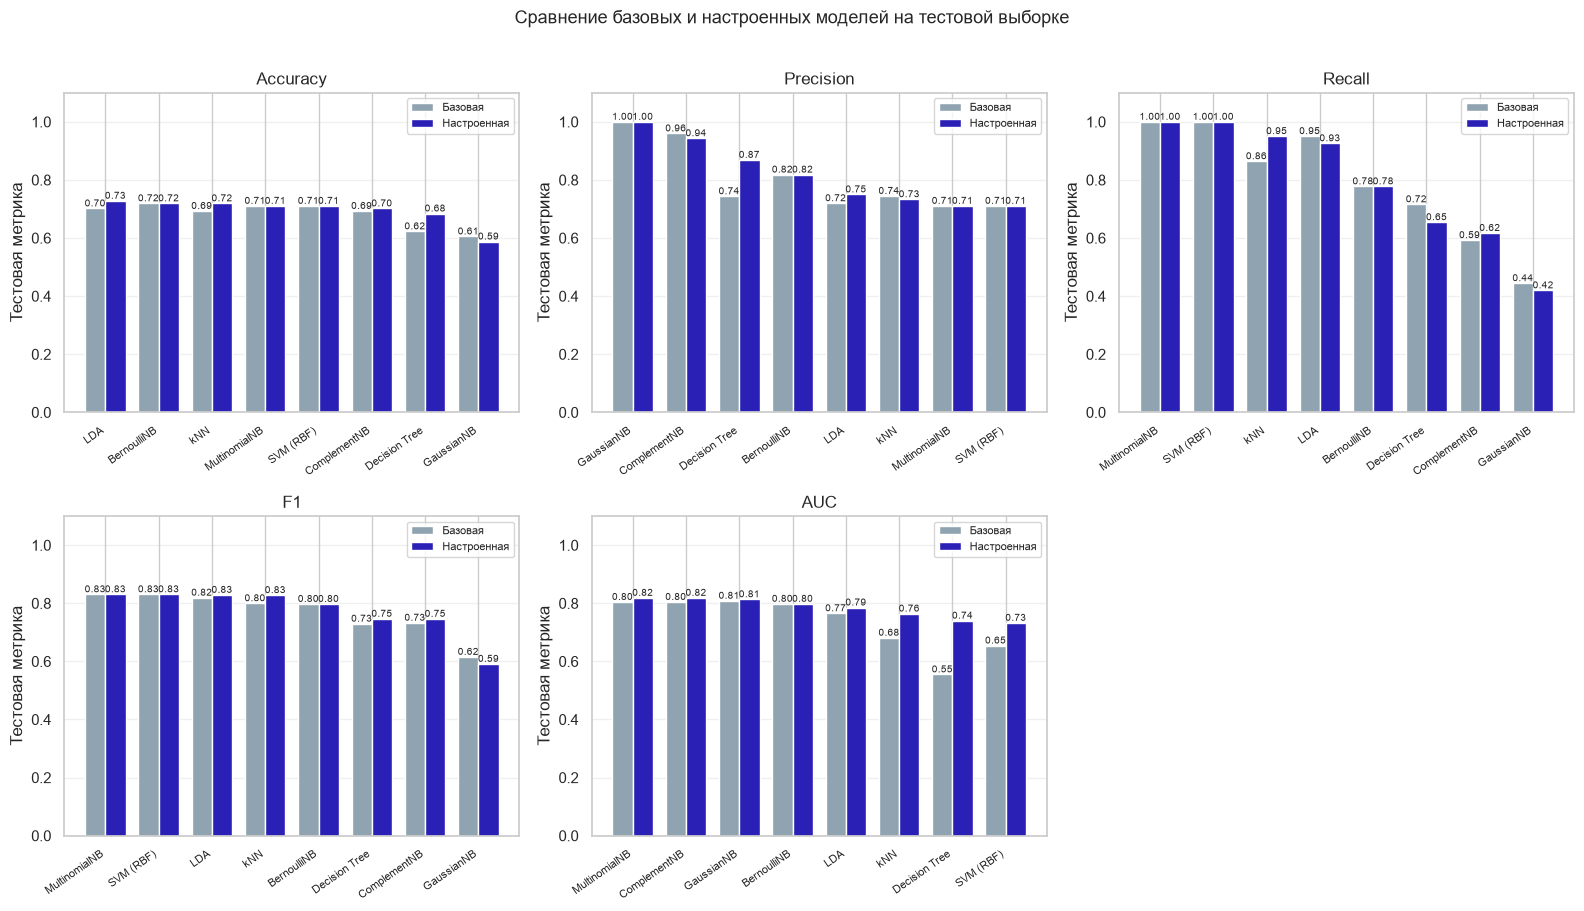

In [65]:
comparison_long = pd.concat(
    [
        baseline_df[core_metrics].assign(Модель=baseline_df.index, Этап='Базовая'),
        tuned_df[core_metrics].assign(Модель=tuned_df.index, Этап='Настроенная'),
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
palette = {'Базовая': '#8fa3b0', 'Настроенная': "#2a20b6"}

for ax, metric in zip(axes.flat, core_metrics):
    order = (
        tuned_df[metric].sort_values(ascending=False).index.tolist()
    )

    pivot = (
        comparison_long
        .pivot(index='Модель', columns='Этап', values=metric)
        .reindex(order) 
    )

    x = np.arange(len(order))
    width = 0.38

    bars_base = ax.bar(
        x - width/2, pivot['Базовая'].values, width,
        label='Базовая', color=palette['Базовая'], edgecolor='white',
    )
    bars_tune = ax.bar(
        x + width/2, pivot['Настроенная'].values, width,
        label='Настроенная', color=palette['Настроенная'], edgecolor='white',
    )

    for bars in (bars_base, bars_tune):
        for p in bars:
            h = p.get_height()
            if not np.isnan(h):
                ax.annotate(
                    f'{h:.2f}',
                    (p.get_x() + p.get_width()/2, h),
                    ha='center', va='bottom', fontsize=7,
                )

    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=35, ha='right', fontsize=8)
    ax.set_title(metric)
    ax.set_ylim(0, 1.10)
    ax.set_ylabel('Тестовая метрика')
    ax.grid(axis='y', alpha=0.3)
    ax.legend(fontsize=8, loc='upper right')

axes.flat[-1].axis('off')
fig.suptitle('Сравнение базовых и настроенных моделей на тестовой выборке',
             y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

- Accuracy: лидер настроенных - LDA (0.728), затем BernoulliNB и kNN (0.719); дерево выросло с 0.623 до 0.684 (+0.061), GaussianNB снизился с 0.605 до 0.588. Пять из восьми моделей (MultinomialNB, SVM, BernoulliNB, kNN, LDA) находятся в диапазоне 0.711–0.728, т.е. рядом с тривиальной линией 0.711; ниже неё остаются ComplementNB (0.702), дерево (0.684) и GaussianNB (0.588).
- Precision: максимум у GaussianNB (1.000) и ComplementNB (0.943); дерево выросло с 0.744 до 0.869 (+0.125); у MultinomialNB и SVM 0.711 (тривиальный уровень).
- Recall: MultinomialNB и SVM - 1.000, kNN - 0.951, LDA - 0.926, BernoulliNB - 0.778, дерево - 0.654, ComplementNB - 0.617, GaussianNB - 0.420. Обратная связь с Precision сохраняется.
- F1: MultinomialNB и SVM - 0.831, LDA - 0.829, kNN - 0.828, BernoulliNB - 0.797, дерево и ComplementNB - 0.746, GaussianNB - 0.591. Для «тривиальных» моделей F1 самый высокий.
- ROC-AUC: настроенная модель не хуже базовой во всех случаях; максимальные приросты - у дерева (0.555 → 0.740), kNN (0.681 → 0.764) и SVM (0.654 → 0.733).

## Нейронная сеть на TensorFlow

### Подготовка данный для нейронных сетей

In [66]:
import os
import shutil
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

prep = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

Xtr = prep.fit_transform(X_tr).astype(np.float32)
Xva = prep.transform(X_val).astype(np.float32)
Xte = prep.transform(X_test).astype(np.float32)

ytr = y_tr.to_numpy().astype(np.float32)
yva = y_val.to_numpy().astype(np.float32)
yte = y_test.to_numpy().astype(int)

n0 = int(np.sum(ytr == 0))
n1 = int(np.sum(ytr == 1))
class_weight = {
    0: len(ytr) / (2 * n0),
    1: len(ytr) / (2 * n1)
}

print('Обучающая выборка:', Xtr.shape)
print('Валидационная выборка:', Xva.shape)
print('Тестовая выборка:', Xte.shape)
print('Число входных признаков:', Xtr.shape[1])
print('Веса классов:', class_weight)

Обучающая выборка: (364, 10)
Валидационная выборка: (92, 10)
Тестовая выборка: (114, 10)
Число входных признаков: 10
Веса классов: {0: 1.7333333333333334, 1: 0.7027027027027027}


Для нейронной сети обучающая выборка (456 объектов) была дополнительно разделена на обучающую часть (364 объекта) и валидационную (92 объекта) в пропорции 80/20 со стратификацией. Валидационная выборка нужна для выбора гиперпараметров и контроля переобучения. Тестовая выборка (114 объектов) осталась нетронутой и используется только один раз, для итоговой оценки.

Пропуски заполняются медианой, признаки стандартизуются. Импутер и скейлер обучены только на 364 объектах обучающей части, а к валидационной и тестовой выборкам применены уже готовые преобразования, поэтому утечки информации нет. 

Классы несбалансированы (≈ 71 % больных), поэтому введены веса классов: 0 - 1.733, 1 - 0.703 (обратно пропорционально частоте класса). Ошибка на редком классе «нет заболевания» штрафуется в ≈ 2.5 раза сильнее, и сеть не может добиться низкого loss, просто предсказывая всем «болен». Это тот же дефект, который мы видели у MultinomialNB и SVM.

### Описание архитектуры нейронной сети, используемых слоев, функций активации, потерь и оптимизатора

In [67]:
def build_model(input_dim, hidden_layers=(32, 16), activation='relu', learning_rate=0.001):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(input_dim,)))

    for neurons in hidden_layers:
        model.add(tf.keras.layers.Dense(neurons, activation=activation))

    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name='accuracy'),
            tf.keras.metrics.AUC(name='auc')
        ]
    )
    return model

base_model = build_model(input_dim=Xtr.shape[1])
base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

Использована полносвязная сеть прямого распространения (Sequential):

| Слой | Выход | Параметры | Расчёт |
|---|---|---|---|
| Input | 10 | - | 10 стандартизованных признаков |
| Dense + ReLU | 32 | 352 | 10·32 + 32 |
| Dense + ReLU | 16 | 528 | 32·16 + 16 |
| Dense + sigmoid | 1 | 17 | 16·1 + 1 |

Всего 897 обучаемых параметров. Для обучающей выборки в 364 объекта это небольшая сеть, и такой размер выбран сознательно: на малых табличных данных большие сети быстро переобучаются.

- **Скрытые слои, ReLU**: простая нелинейность, не насыщается при положительных значениях, поэтому градиент не затухает.
- **Выходной слой, sigmoid**: даёт число из (0, 1), которое трактуется как вероятность заболевания. Класс «болен» предсказывается при вероятности ≥ 0.5.
- **Функция потерь, binary crossentropy**: стандартный выбор для бинарной классификации с sigmoid на выходе. Она штрафует уверенные неправильные ответы сильнее, чем сомневающиеся.
- **Оптимизатор, Adam** со скоростью обучения 0.001: адаптивный градиентный метод, хорошо работающий «из коробки» без тонкой настройки.
- **Метрики при обучении**: accuracy и AUC, обе считаются отдельно на обучающей и валидационной частях после каждой эпохи.
- **Строка Optimizer params: 1 796** в итоговой summary - это внутренние накопители Adam (по два на каждый параметр, 2·897 + 2), они не входят в число обучаемых параметров модели.

### Эсперименты с изменением гиперпараметров

In [68]:
LOG_DIR = os.path.join('logs', 'fit')
shutil.rmtree(LOG_DIR, ignore_errors=True)
os.makedirs(LOG_DIR, exist_ok=True)

BASE_CONFIG = {
    'hidden_layers': (32, 16),
    'activation': 'relu',
    'batch_size': 32,
    'epochs': 50,
    'learning_rate': 0.001
}

experiments = [
    ('Эпохи: 10', 'epochs_10', {'epochs': 10}),
    ('Эпохи: 50', 'epochs_50', {'epochs': 50}),
    ('Эпохи: 100', 'epochs_100', {'epochs': 100}),

    ('Батч: 16', 'batch_16', {'batch_size': 16}),
    ('Батч: 32', 'batch_32', {'batch_size': 32}),
    ('Батч: 64', 'batch_64', {'batch_size': 64}),

    ('Число слоёв: 1', 'layers_1', {'hidden_layers': (32,)}),
    ('Число слоёв: 2', 'layers_2', {'hidden_layers': (32, 32)}),
    ('Число слоёв: 3', 'layers_3', {'hidden_layers': (32, 32, 32)}),

    ('Нейронов в слое: 16', 'neurons_16', {'hidden_layers': (16, 16)}),
    ('Нейронов в слое: 32', 'neurons_32', {'hidden_layers': (32, 32)}),
    ('Нейронов в слое: 64', 'neurons_64', {'hidden_layers': (64, 64)}),

    ('Активация: ReLU', 'activation_relu', {'activation': 'relu'}),
    ('Активация: tanh', 'activation_tanh', {'activation': 'tanh'}),
    ('Активация: sigmoid', 'activation_sigmoid', {'activation': 'sigmoid'})
]

results = []
histories = {}
configs = {}

for label, run_name, changes in experiments:
    tf.keras.utils.set_random_seed(SEED)
    config = {**BASE_CONFIG, **changes}
    model = build_model(
        input_dim=Xtr.shape[1],
        hidden_layers=config['hidden_layers'],
        activation=config['activation'],
        learning_rate=config['learning_rate']
    )

    tb_callback = tf.keras.callbacks.TensorBoard(
        log_dir=os.path.join(LOG_DIR, run_name),
        update_freq='epoch',
        histogram_freq=0
    )

    history = model.fit(
        Xtr, ytr,
        validation_data=(Xva, yva),
        epochs=config['epochs'],
        batch_size=config['batch_size'],
        class_weight=class_weight,
        callbacks=[tb_callback],
        verbose=0
    )

    best_epoch = int(np.argmin(history.history['val_loss']))
    results.append({
        'Эксперимент': label,
        'Val loss': history.history['val_loss'][best_epoch],
        'Val Accuracy': history.history['val_accuracy'][best_epoch],
        'Val ROC-AUC': history.history['val_auc'][best_epoch],
        'Лучшая эпоха': best_epoch + 1
    })
    histories[label] = history
    configs[label] = config
    tf.keras.backend.clear_session()

results_df = pd.DataFrame(results).set_index('Эксперимент')
display(results_df.sort_values('Val ROC-AUC', ascending=False).round(4))


,Val loss,Val Accuracy,Val ROC-AUC,Лучшая эпоха
Эксперимент,,,,
Эпохи: 10,0.6095,0.6848,0.7570,10
Число слоёв: 3,0.5263,0.6848,0.7547,24
Активация: sigmoid,0.5661,0.6739,0.7506,50
Нейронов в слое: 16,0.5601,0.6522,0.7418,49
Активация: tanh,0.5578,0.6630,0.7389,41
Эпохи: 50,0.5529,0.6522,0.7357,50
Батч: 32,0.5529,0.6522,0.7357,50
Активация: ReLU,0.5529,0.6522,0.7357,50
Эпохи: 100,0.5526,0.6522,0.7354,52


Каждый эксперимент меняет один параметр относительно базовой конфигурации: слои (32, 16), ReLU, батч 32, 50 эпох, learning rate 0.001. Перед каждым запуском фиксируется seed, поэтому различия вызваны только изменённым параметром. В таблице приведены метрики на той эпохе, где val_loss минимален. Строки «Эпохи: 50», «Батч: 32» и «Активация: ReLU» - это один и тот же запуск базовой конфигурации (поэтому значения совпадают: val loss 0.5529, Accuracy 0.6522, ROC-AUC 0.7357); то же верно для «Число слоёв: 2» и «Нейронов в слое: 32» (обе - архитектура (32, 32)). Эти строки служат контролем.

1. Число эпох (10 / 50 / 100).
- При 10 эпохах val loss ещё высокий (0.6095), лучшая эпоха - последняя, то есть loss продолжает падать: модель не доучена.
- Рост до 50 эпох снижает val loss до 0.5529 (−0.057).
- Увеличение до 100 эпох ничего не даёт: минимум 0.5526 достигается на 52-й эпохе (выигрыш 0.0003), а дальше val loss медленно растёт (≈ 0.566 к 100-й эпохе, это видно на графике сравнения val_loss) - начало переобучения.
- Любопытно, что по ROC-AUC и Accuracy лучше «Эпохи: 10» (AUC 0.757, Accuracy 0.685 против 0.736 и 0.652 у 50 эпох). То есть дальнейшее уменьшение loss не улучшило способность ранжировать пациентов. Разница в AUC (0.02) на 92 объектах, из которых здоровых всего ≈ 26, находится в пределах шума.
- Вывод: полезная длительность обучения - порядка 40-50 эпох; сотня эпох бессмысленна без регуляризации.

2. Размер батча (16 / 32 / 64).
- Размер батча определяет число обновлений весов за эпоху: при 364 объектах это 23, 12 и 6 шагов соответственно.
- Батч 16: самые частые обновления, минимум val loss достигается раньше всех (35-я эпоха), затем loss начинает расти. Val loss 0.5586, Accuracy 0.620, AUC 0.727.
- Батч 32: лучший по val loss (0.5529), Accuracy (0.652) и AUC (0.736) из трёх.
- Батч 64: обучение самое медленное, к 50-й эпохе loss ещё не вышел на минимум (лучшая эпоха - 50-я), val loss 0.5664, AUC 0.727.
- Вывод: батч 32 - разумный компромисс. Разброс AUC между вариантами (0.727-0.736) очень мал, так что размер батча в этой задаче влияет в основном на скорость сходимости, а не на итоговое качество.

3. Число скрытых слоёв (1 / 2 / 3, по 32 нейрона).
- 1 слой (385 параметров): стартует с самого низкого loss (≈ 0.645), но снижается медленнее всех; к 50-й эпохе val loss 0.5675, AUC 0.719 - худший результат по AUC в группе, модель недообучена.
- 2 слоя (1 441 параметр): val loss 0.5540, AUC 0.731, минимум на 42-й эпохе.
- 3 слоя (2 497 параметров): самый низкий val loss среди всех 15 экспериментов (0.5263) и высокий AUC (0.755); минимум на 24-й эпохе, после чего val loss растёт до ≈ 0.553 к 50-й эпохе.
- Закономерность: с ростом глубины сеть быстрее обучается и достигает лучшего минимума, но и начинает переобучаться раньше (эпохи минимума: 50 → 42 → 24). Для трёх слоёв ранняя остановка обязательна.

4. Число нейронов в слое (16 / 32 / 64, два слоя).
- 16 нейронов (465 параметров): val loss 0.5601, AUC 0.742, минимум на 49-й эпохе - обучается медленно и без переобучения.
- 32 нейрона: val loss 0.5540, AUC 0.731.
- 64 нейрона (4 929 параметров): самый плохой AUC в таблице (0.702) и самый высокий val loss в группе (0.5723). Минимум достигается на 22-й эпохе, потом val loss растёт заметнее всех (до ≈ 0.597 к 50-й эпохе) - выраженное переобучение.
- Закономерность: AUC падает с ростом ширины (0.742 → 0.731 → 0.702). На 364 объектах широкая сеть запоминает обучающие примеры, и более узкая обобщает не хуже.

5. Функция активации (ReLU / tanh / sigmoid).
- ReLU: val loss 0.5529, AUC 0.736, минимум на 50-й эпохе.
- tanh: val loss 0.5578, AUC 0.739, минимум на 41-й эпохе, затем небольшой рост.
- sigmoid: самая медленная сходимость (на графике val_loss - самая верхняя кривая, начинает с ≈ 0.78): производная sigmoid не превышает 0.25, и градиенты в скрытых слоях малы. К 50-й эпохе loss ещё не вышел на плато (0.5661), но при этом AUC наибольший в группе (0.751) и Accuracy 0.674.
- Различия по AUC (0.736-0.751) меньше погрешности оценки; одному объекту валидации соответствует 1.1 п.п. Accuracy, поэтому разница Accuracy 0.652 vs 0.674 - это всего два пациента.

Общий вывод по экспериментам.
- Разброс Val ROC-AUC по всем 15 запускам - от 0.702 до 0.757 (0.055). Это сопоставимо с шумом валидационной выборки из 92 объектов, поэтому различия менее ≈ 0.02 нельзя считать надёжными. Каждый запуск сделан с одним seed.
- Наиболее заметные эффекты имеют не «мелкие» параметры, а ёмкость сети и длительность обучения: слишком широкая сеть (64) и слишком долгое обучение (> 50 эпох) приводят к росту val loss, а слишком мелкая (1 слой) и слишком медленная (sigmoid, батч 64) к недообучению.
- Рейтинги по val loss и по val AUC не совпадают: лучший val loss у конфигурации с тремя слоями (0.5263), лучший AUC - у запуска на 10 эпох (0.757), у которого val loss худший (0.6095). Разница в AUC между первыми двумя местами (0.7570 и 0.7547) составляет 0.002, то есть они практически равноценны.
- По критерию «максимальный Val ROC-AUC» выбрана конфигурация «Эпохи: 10» ((32, 16), ReLU, батч 32, 10 эпох).

In [69]:
best_label = results_df['Val ROC-AUC'].idxmax()
final_config = configs[best_label].copy()
print('Выбранная конфигурация:', best_label)
print(final_config)
tf.keras.utils.set_random_seed(SEED)

nn_model = build_model(
    input_dim=Xtr.shape[1],
    hidden_layers=final_config['hidden_layers'],
    activation=final_config['activation'],
    learning_rate=final_config['learning_rate']
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)
tensorboard_final = tf.keras.callbacks.TensorBoard(
    log_dir=os.path.join(LOG_DIR, 'final_model'),
    update_freq='epoch',
    histogram_freq=0
)

nn_history = nn_model.fit(
    Xtr, ytr,
    validation_data=(Xva, yva),
    epochs=final_config['epochs'],
    batch_size=final_config['batch_size'],
    class_weight=class_weight,
    callbacks=[early_stopping, tensorboard_final],
    verbose=0
)

nn_proba_test = nn_model.predict(Xte, verbose=0).ravel()
nn_pred_test = (nn_proba_test >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, nn_pred_test, labels=[0, 1]).ravel()

nn_metrics = {
    'Accuracy': accuracy_score(yte, nn_pred_test),
    'Precision': precision_score(yte, nn_pred_test, zero_division=0),
    'Recall': recall_score(yte, nn_pred_test, zero_division=0),
    'F1': f1_score(yte, nn_pred_test, zero_division=0),
    'AUC': roc_auc_score(yte, nn_proba_test),
    'Specificity': tn / (tn + fp) if (tn + fp) else 0.0,
    'Balanced Accuracy': balanced_accuracy_score(yte, nn_pred_test)
}

print(f'Число эпох итоговой модели: {len(nn_history.history["loss"])}')
print('Матрица ошибок: TN =', tn, ', FP =', fp, ', FN =', fn, ', TP =', tp)
display(pd.DataFrame([nn_metrics], index=['Нейронная сеть']).round(3))
nn_model.summary()

Выбранная конфигурация: Эпохи: 10
{'hidden_layers': (32, 16), 'activation': 'relu', 'batch_size': 32, 'epochs': 10, 'learning_rate': 0.001}
Число эпох итоговой модели: 10
Матрица ошибок: TN = 29 , FP = 4 , FN = 26 , TP = 55


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy
Нейронная сеть,0.737,0.932,0.679,0.786,0.793,0.879,0.779


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,693 (10.52 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,796 (7.02 KB)

Обучена конфигурация, выбранная по максимальному Val ROC-AUC: слои (32, 16), ReLU, батч 32, 10 эпох, веса классов и ранняя остановка (monitor = val_loss, patience = 15, restore_best_weights). Из-за короткого обучения (10 эпох < patience = 15) ранняя остановка не сработала, и модель прошла все 10 эпох: val loss снижался до самого конца, поэтому восстановленные веса - это веса последней эпохи.

Результаты на тестовой выборке (114 пациентов): TN = 29, FP = 4, FN = 26, TP = 55.
- Accuracy 0.737 - выше тривиального уровня 0.711 (константное «все больны»); разница - около 3 пациентов из 114.
- Precision 0.932: из 59 пациентов, названных больными, 55 действительно больны.
- Recall 0.679: найдено 55 из 81 больных, 26 (32 %) пропущено.
- Specificity 0.879: правильно распознаны 29 из 33 здоровых, лишь 4 ложные тревоги.
- F1 0.786, ROC-AUC 0.793, Balanced Accuracy 0.779.

Сеть не скатилась к классификатору «все больны» и имеет симметричный профиль ошибок. Веса классов сместили баланс в сторону здоровых: ошибок «пропуск больного» (26) намного больше, чем «ложная тревога» (4).

### Графики обучения и валидации

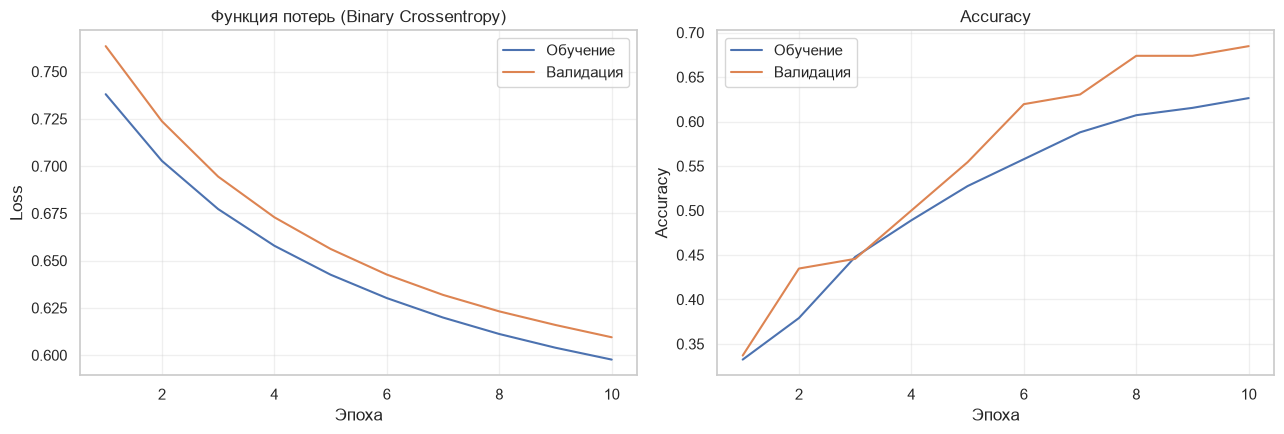

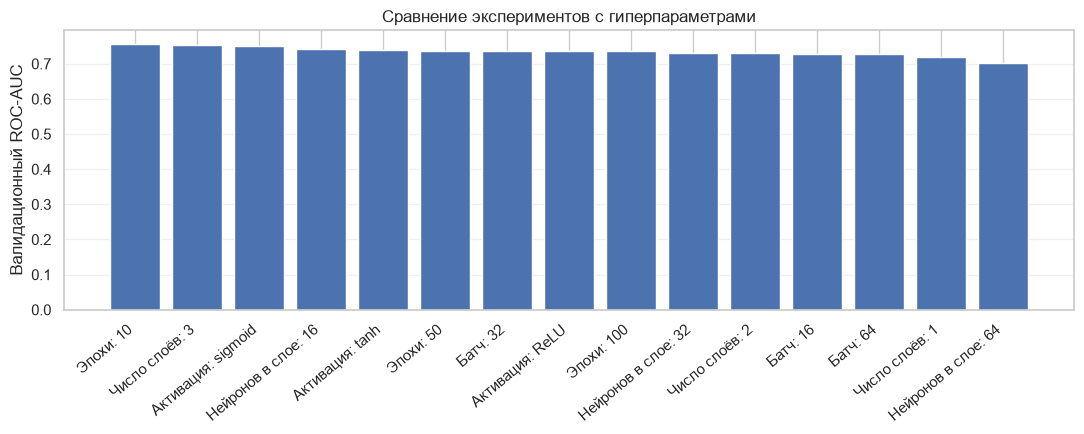

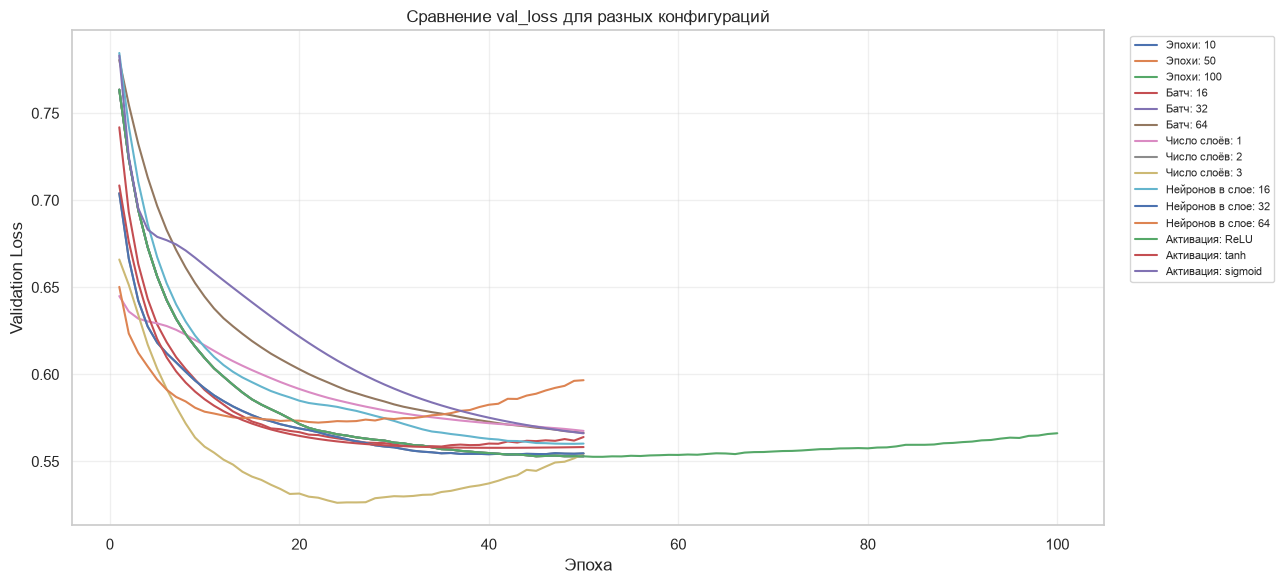

In [70]:
history = nn_history.history
epochs_range = range(1, len(history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range, history['loss'], label='Обучение')
axes[0].plot(epochs_range, history['val_loss'], label='Валидация')
axes[0].set_title('Функция потерь (Binary Crossentropy)')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history['accuracy'], label='Обучение')
axes[1].plot(epochs_range, history['val_accuracy'], label='Валидация')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 4.5))
results_sorted = results_df.sort_values('Val ROC-AUC', ascending=False)
plt.bar(results_sorted.index, results_sorted['Val ROC-AUC'])
plt.ylabel('Валидационный ROC-AUC')
plt.title('Сравнение экспериментов с гиперпараметрами')
plt.xticks(rotation=40, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(13, 6))

for name, hist in histories.items():
    val_loss = hist.history['val_loss']
    epochs = range(1, len(val_loss) + 1)

    plt.plot(epochs, val_loss, label=name)

plt.title('Сравнение val_loss для разных конфигураций')
plt.xlabel('Эпоха')
plt.ylabel('Validation Loss')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


- Loss: обе кривые монотонно убывают. Обучающая - с ≈ 0.738 до 0.598, валидационная - с ≈ 0.763 до 0.610. Валидационная кривая всё время выше обучающей, разрыв к 10-й эпохе небольшой (≈ 0.012) и не растёт, то есть признаков переобучения нет. Кривые к 10-й эпохе ещё не вышли на плато, модель слегка недообучена (это согласуется с экспериментом на 50 эпох, где val loss опускается ещё до 0.553).
- Accuracy: растёт с ≈ 0.33 до 0.626 на обучении и до 0.685 на валидации. Стартовое значение ниже 0.5 означает, что с начальными случайными весами сеть почти всех относит к классу «нет заболевания», и за 10 эпох она учится различать классы. Валидационная accuracy выше обучающей: это нормально, так как обучающая accuracy усредняется по ходу эпохи, пока веса ещё меняются, а валидационная считается по весам в конце эпохи; к тому же валидационная выборка мала (92 объекта).

Все 15 столбцов лежат в диапазоне 0.70-0.76, то есть различия между конфигурациями небольшие. Лидеры - «Эпохи: 10» (0.757), «Число слоёв: 3» (0.755) и «Активация: sigmoid» (0.751); последний - «Нейронов в слое: 64» (0.702).

Сравнение val_loss.
- Кривая трёх слоёв самая низкая (минимум 0.526 около 24-й эпохи), после чего растёт.
- Кривая с 64 нейронами стартует низко (≈ 0.65), быстро достигает минимума и затем выраженно растёт, а это классическая картина переобучения.
- Запуск на 100 эпох после 52-й эпохи медленно поднимается, подтверждая, что дальнейшее обучение вредит.
- Самые медленные кривые - sigmoid, батч 64 и один слой: они не успевают выйти на минимум за 50 эпох.
- Остальные конфигурации (базовая, tanh, 16 нейронов, батч 16 и т.д.) сходятся к близкому уровню 0.55-0.57.
- Вывод: чем больше ёмкость и чем чаще обновления весов, тем раньше начинается переобучение. Для малой выборки в 364 объекта оптимальны небольшие сети и ранняя остановка.

###  Мониторинг обучения через TensorBoard

In [71]:
%load_ext tensorboard
%tensorboard --logdir logs/fit


Reusing TensorBoard on port 6006 (pid 17804), started 8:42:23 ago. (Use '!kill 17804' to kill it.)

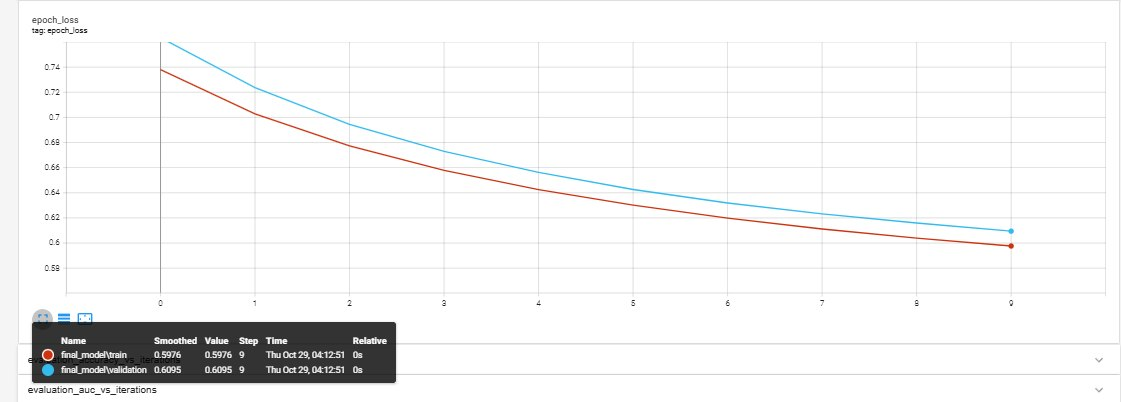

In [72]:
Image('loss.png')  

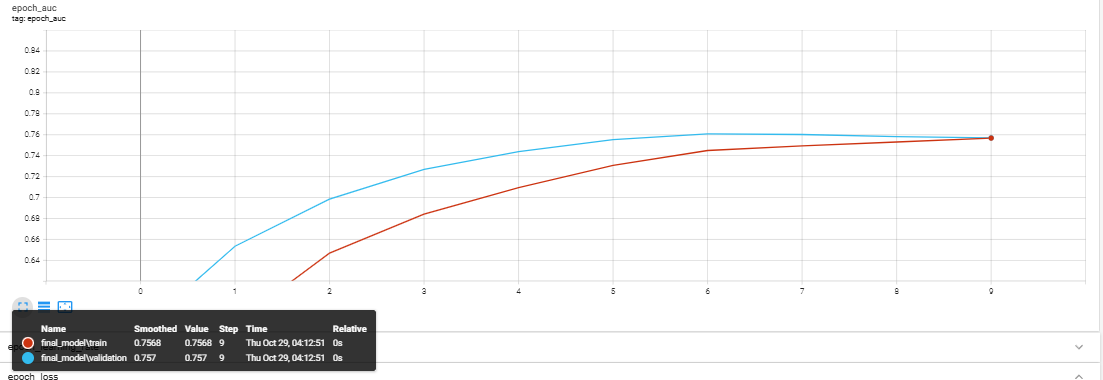

In [74]:
Image('auc.png')

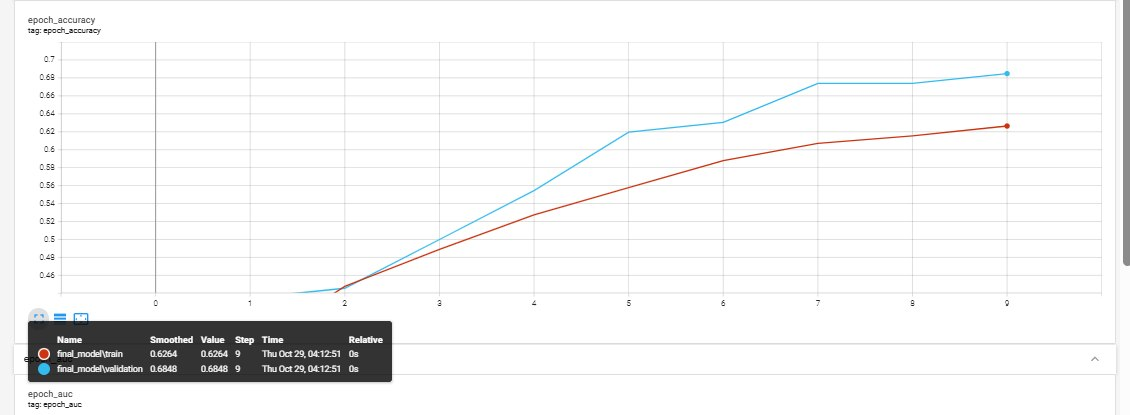

In [73]:
Image('accuracy.png')

Итоговая модель.
- epoch_loss: обучение 0.5976, валидация 0.6095. Обе кривые монотонно убывают, расстояние между ними небольшое.
- epoch_accuracy: обучение 0.6264, валидация 0.6848; рост без срывов, валидационная кривая выше обучающей.
- epoch_auc: обучение 0.7568, валидация 0.7570. Валидационный AUC достигает ≈ 0.76 примерно к 6-й эпохе и дальше почти не меняется, обучающий догоняет его к 10-й эпохе.

Значения совпадают с графиками matplotlib, построенными по nn_history. Сходимость AUC показывает, что на 10-й эпохе сеть уже выжала из данных почти всё, что она способна извлечь при такой архитектуре: обучающий и валидационный AUC сравнялись, дальнейший рост ожидать трудно.

## Сравнительный анализ

### Таблица сравнения метрик качества для всех рассмотренных методов классификации

Таблица 1. Настроенные модели и нейронная сеть на тестовой выборке (по убыванию ROC-AUC):


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,AUC 95% ДИ
MultinomialNB,0.711,0.711,1.000,0.831,0.819,0.000,0.500,[0.739; 0.892]
ComplementNB,0.702,0.943,0.617,0.746,0.819,0.909,0.763,[0.739; 0.892]
GaussianNB,0.588,1.000,0.420,0.591,0.814,1.000,0.710,[0.733; 0.890]
BernoulliNB,0.719,0.818,0.778,0.797,0.798,0.576,0.677,[0.715; 0.878]
Нейронная сеть (TF),0.737,0.932,0.679,0.786,0.793,0.879,0.779,[0.706; 0.872]
LDA,0.728,0.750,0.926,0.829,0.785,0.242,0.584,[0.701; 0.864]
kNN,0.719,0.733,0.951,0.828,0.764,0.152,0.551,[0.668; 0.848]
Decision Tree,0.684,0.869,0.654,0.746,0.740,0.758,0.706,[0.629; 0.832]
SVM (RBF),0.711,0.711,1.000,0.831,0.733,0.000,0.500,[0.642; 0.816]



Таблица 2. Все модели (базовые и настроенные):


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy
MultinomialNB - базовая,0.711,0.711,1.000,0.831,0.804,0.000,0.500
SVM (RBF) - базовая,0.711,0.711,1.000,0.831,0.654,0.000,0.500
LDA - базовая,0.702,0.720,0.951,0.819,0.765,0.091,0.521
kNN - базовая,0.693,0.745,0.864,0.800,0.681,0.273,0.568
BernoulliNB - базовая,0.719,0.818,0.778,0.797,0.798,0.576,0.677
ComplementNB - базовая,0.693,0.960,0.593,0.733,0.804,0.939,0.766
Decision Tree - базовая,0.623,0.744,0.716,0.730,0.555,0.394,0.555
GaussianNB - базовая,0.605,1.000,0.444,0.615,0.808,1.000,0.722
GaussianNB - настроенная,0.588,1.000,0.420,0.591,0.814,1.000,0.710
MultinomialNB - настроенная,0.711,0.711,1.000,0.831,0.819,0.000,0.500


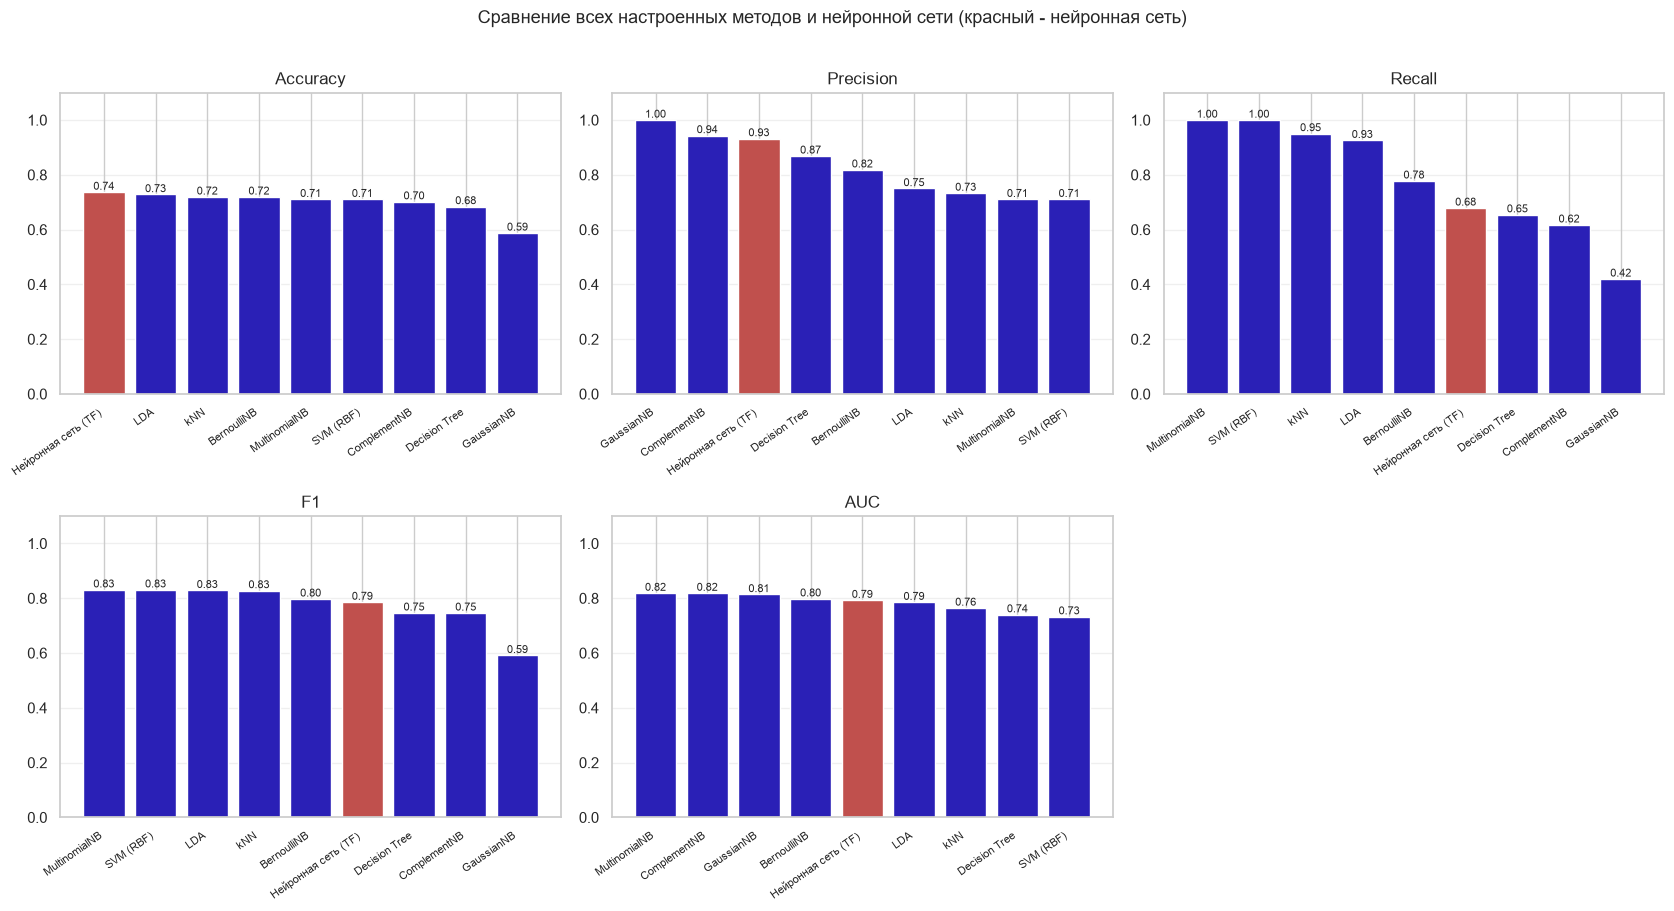

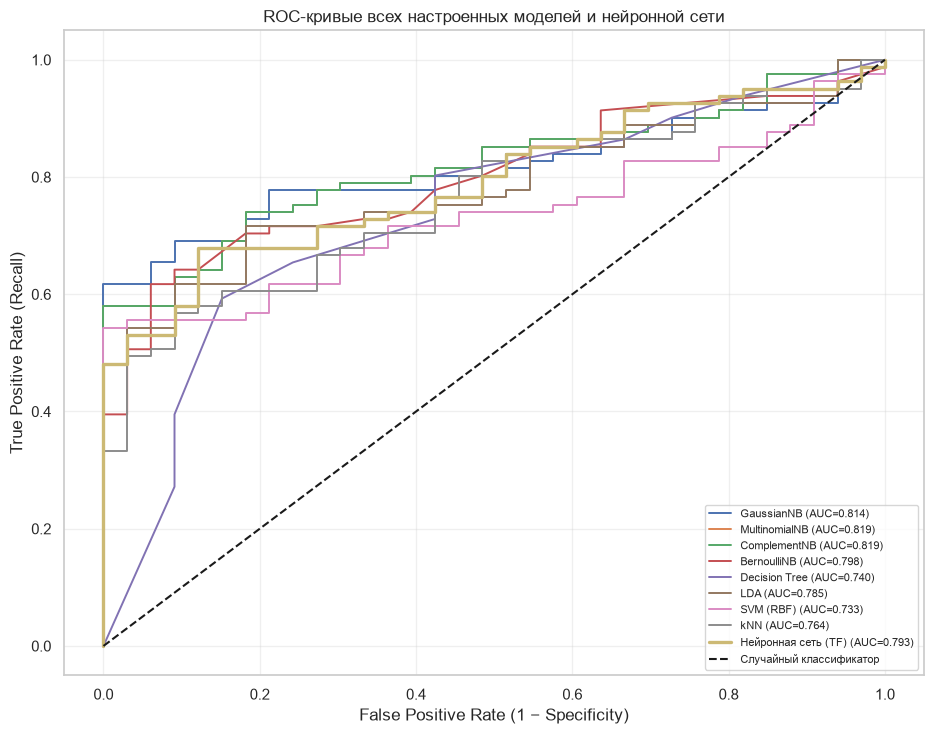

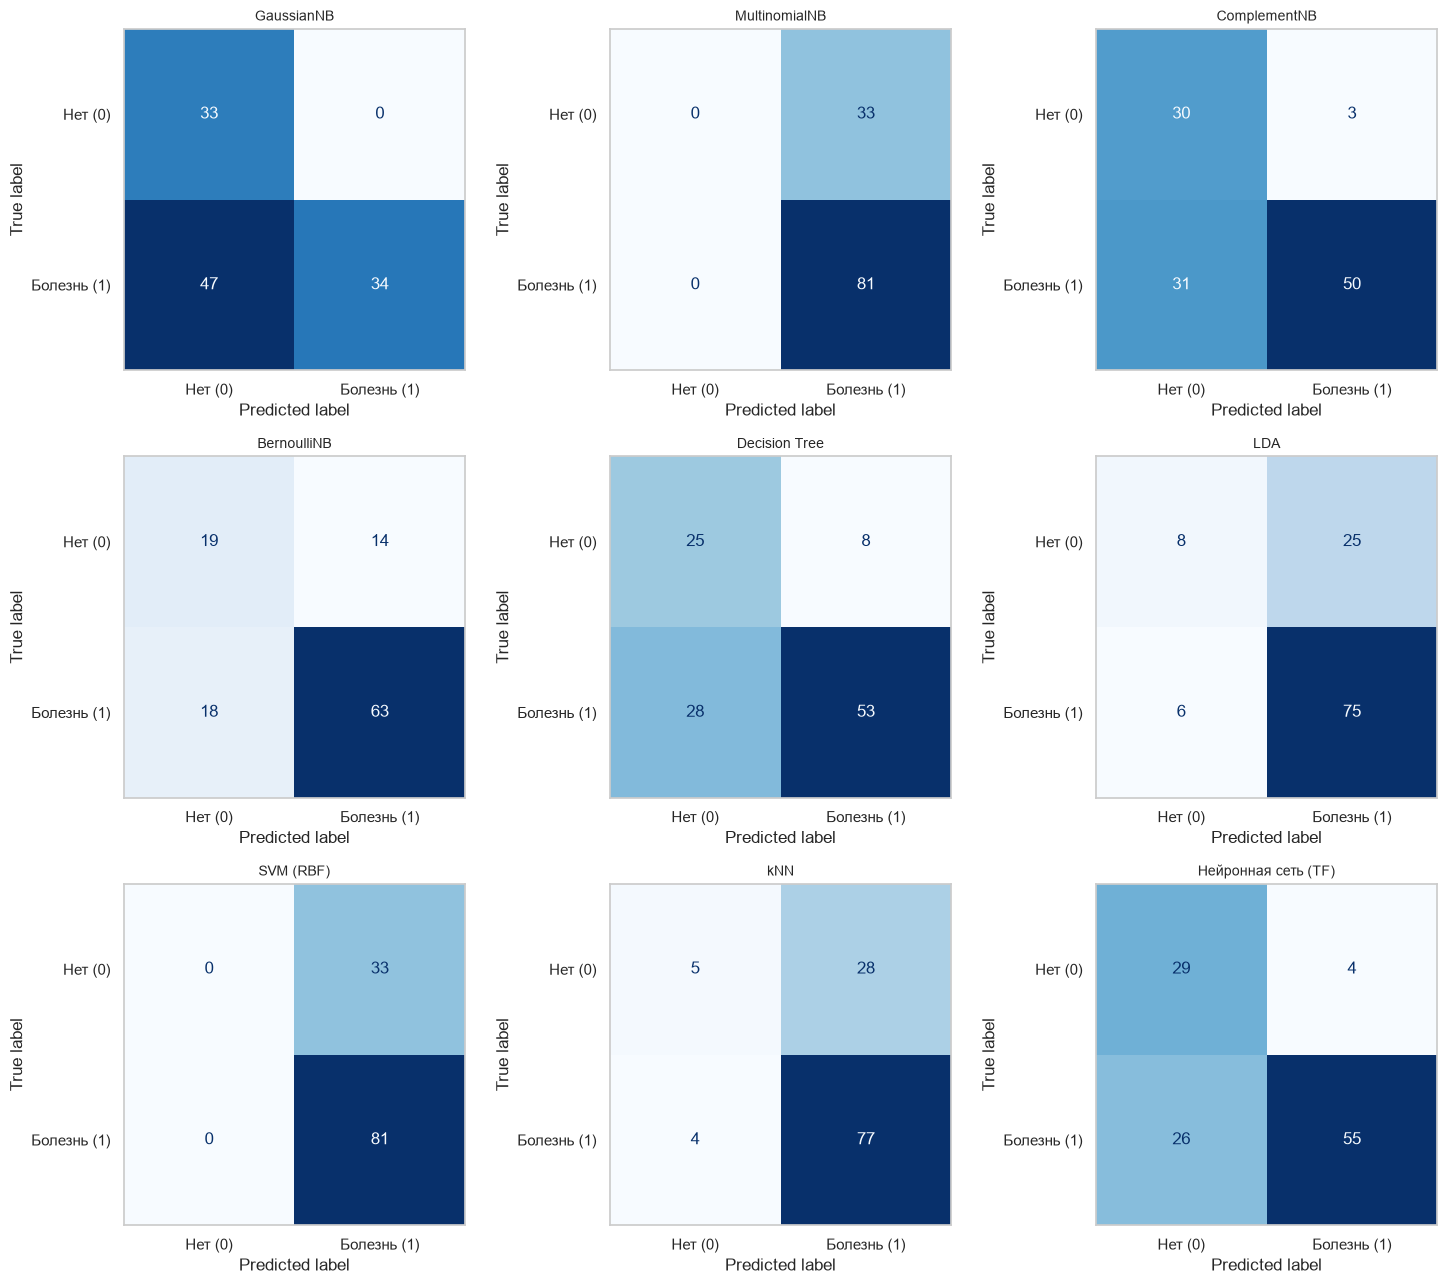

Лучшая модель по среднему рангу: ComplementNB
Лучшая классическая модель (без учета нейросети): ComplementNB


In [ ]:
core_metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
NN_NAME = 'Нейронная сеть (TF)'
cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC', 'Specificity', 'Balanced Accuracy']

rows = {} 

for name in baseline_df.index:
    rows[f'{name} - базовая'] = baseline_df.loc[name, cols].to_dict()
    
for name in tuned_df.index:
    rows[f'{name} - настроенная'] = tuned_df.loc[name, cols].to_dict()
    
rows[NN_NAME] = nn_metrics
full_df = pd.DataFrame(rows).T[cols].astype(float)


def bootstrap_auc_ci(y_true, score, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, score = np.asarray(y_true).astype(int), np.asarray(score)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        vals.append(roc_auc_score(y_true[idx], score[idx]))
    return np.percentile(vals, [2.5, 97.5])

scores = {name: get_score(m, X_test) for name, m in tuned_models.items()}
scores[NN_NAME] = nn_proba_test

final_df = pd.concat([tuned_df[cols].astype(float), pd.DataFrame({NN_NAME: nn_metrics}).T[cols]])
ci = {n: bootstrap_auc_ci(y_test, s) for n, s in scores.items()}
final_df['AUC 95% ДИ'] = [f'[{ci[n][0]:.3f}; {ci[n][1]:.3f}]' for n in final_df.index]
final_df = final_df.sort_values('AUC', ascending=False)

pd.set_option('display.max_colwidth', None)

print('Таблица 1. Настроенные модели и нейронная сеть на тестовой выборке (по убыванию ROC-AUC):')
display(final_df.round(3))
print('\nТаблица 2. Все модели (базовые и настроенные):')
display(full_df.round(3))


plot_df = final_df[core_metrics].astype(float)
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, metric in zip(axes.flat, core_metrics):
    vals = plot_df[metric].sort_values(ascending=False)
    colors = ['#c0504d' if n == NN_NAME else '#2a20b6' for n in vals.index]
    ax.bar(range(len(vals)), vals.values, color=colors)
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels(vals.index, rotation=35, ha='right', fontsize=8)
    ax.set_ylim(0, 1.1)
    ax.set_title(metric)
    ax.grid(axis='y', alpha=0.3)
    for i, v in enumerate(vals.values):
        ax.annotate(f'{v:.2f}', (i, v), ha='center', va='bottom', fontsize=8)
axes.flat[-1].axis('off')
fig.suptitle('Сравнение всех настроенных методов и нейронной сети (красный - нейронная сеть)', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9.5, 7.5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    plt.plot(fpr, tpr, lw=2.4 if name == NN_NAME else 1.4, label=f'{name} (AUC={final_df.loc[name, "AUC"]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случайный классификатор')
plt.xlabel('False Positive Rate (1 − Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC-кривые всех настроенных моделей и нейронной сети')
plt.legend(loc='lower right', fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(15, 13))
preds = {name: m.predict(X_test) for name, m in tuned_models.items()}
preds[NN_NAME] = (nn_proba_test >= 0.5).astype(int)
for ax, (name, p) in zip(axes.flat, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p, labels=[0, 1], display_labels=['Нет (0)', 'Болезнь (1)'],
                                            ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.show()

rank_cols = ['AUC', 'Balanced Accuracy']  
ranks = final_df[rank_cols].astype(float).rank(ascending=False, method='min')
mean_rank = ranks.mean(axis=1).sort_values()
leaders = {m: (plot_df[m].idxmax(), plot_df[m].max()) for m in core_metrics}
best_name = mean_rank.index[0]
best_sk = [n for n in mean_rank.index if n != NN_NAME][0]
top2 = final_df['AUC'].sort_values(ascending=False).index[:2]
ci_overlap = max(ci[top2[0]][0], ci[top2[1]][0]) <= min(ci[top2[0]][1], ci[top2[1]][1])

print(f"Лучшая модель по среднему рангу: {best_name}")
print(f"Лучшая классическая модель (без учета нейросети): {best_sk}")

Все модели оцениваются на одной и той же тестовой выборке из 114 пациентов (81 больной, 33 здоровых), которая не использовалась ни при обучении, ни при подборе гиперпараметров. Таблица 1 содержит настроенные классические модели и нейронную сеть, отсортированные по ROC-AUC, и 95-процентный доверительный интервал AUC, полученный бутстрепом (1000 повторов). Таблица 2 добавляет базовые версии, чтобы видеть эффект настройки.

1. Лидеры по каждой метрике

| Метрика | Лидер | Значение | Комментарий |
|---|---|---|---|
| Accuracy | Нейронная сеть | 0.737 | Следом LDA (0.728), BernoulliNB и kNN (0.719) |
| Precision | GaussianNB | 1.000 | Затем ComplementNB (0.943), нейросеть (0.932) |
| Recall | MultinomialNB и SVM | 1.000 | Тривиальный результат: они объявляют больными всех |
| F1 | MultinomialNB и SVM | 0.831 | Тот же тривиальный уровень; LDA 0.829, kNN 0.828 |
| ROC-AUC | MultinomialNB и ComplementNB | 0.819 | Затем GaussianNB (0.814), BernoulliNB (0.798), нейросеть (0.793) |

Ни одна модель не лидирует сразу по всем метрикам. Два лидерства (Recall и F1) принадлежат моделям, которые не различают классы: у MultinomialNB и SVM Specificity равна 0, и их показатели совпадают с показателями константного классификатора. Поэтому F1 и Recall в этой задаче нельзя использовать как единственный критерий: чем больше модель склоняется к ответу «болен», тем выше эти метрики, независимо от её реальной полезности. Лидерство GaussianNB по Precision (1.000) тоже обманчиво: оно достигнуто за счёт Recall = 0.420 (из 81 больных найдено 34).

2. Ошибки моделей на тесте.

| Модель | TN | FP | FN | TP | Всего ошибок | Названо больными |
|---|---|---|---|---|---|---|
| Нейронная сеть | 29 | 4 | 26 | 55 | 30 | 59 |
| LDA | 8 | 25 | 6 | 75 | 31 | 100 |
| BernoulliNB | 19 | 14 | 18 | 63 | 32 | 77 |
| kNN | 5 | 28 | 4 | 77 | 32 | 105 |
| MultinomialNB | 0 | 33 | 0 | 81 | 33 | 114 |
| SVM (RBF) | 0 | 33 | 0 | 81 | 33 | 114 |
| ComplementNB | 30 | 3 | 31 | 50 | 34 | 53 |
| Decision Tree | 25 | 8 | 28 | 53 | 36 | 61 |
| GaussianNB | 33 | 0 | 47 | 34 | 47 | 34 |

Общее число ошибок у восьми моделей из девяти лежит в узком диапазоне 30-36, то есть Accuracy различается максимум на 5 пациентов из 114. Отличается структура ошибок, и по ней модели делятся на три группы:
- GaussianNB, ComplementNB, нейросеть, дерево: мало ложных тревог (0, 3, 4 и 8 из 33 здоровых), но много пропущенных больных (47, 31, 26 и 28 из 81). Они называют больными лишь 30-54 % пациентов при реальной доле 71 %.
- MultinomialNB, SVM, kNN, LDA: находят 93-100 % больных, но правильно распознают только 0-24 % здоровых. LDA и kNN называют больными 100 и 105 из 114 пациентов, то есть почти ничем не отличаются от тривиального классификатора, хотя формально имеют Accuracy 0.728 и 0.719.
- BernoulliNB: 63 из 81 больных найдено, 19 из 33 здоровых распознано (Specificity 0.576).

Balanced Accuracy (среднее Recall и Specificity) отделяет полезные модели от вырожденных: нейросеть 0.779, ComplementNB 0.763, GaussianNB 0.710, дерево 0.706, BernoulliNB 0.677; ниже находятся LDA 0.584, kNN 0.551, а MultinomialNB и SVM равны 0.500, то есть угадыванию.

3. Что дала настройка гиперпараметров
- Прирост ROC-AUC (настроенная минус базовая): дерево решений 0.555 → 0.740 (+0.185), kNN 0.681 → 0.764 (+0.083), SVM 0.654 → 0.733 (+0.079), LDA 0.765 → 0.785 (+0.020), MultinomialNB и ComplementNB 0.804 → 0.819 (+0.015), GaussianNB 0.808 → 0.814 (+0.006), BernoulliNB без изменений (0.798).
- Выигрыш там, где базовые параметры вели к переобучению (глубокое дерево, k = 5, RBF-ядро), и почти нулевой там, где у модели мало настраиваемых параметров (наивные байесовские классификаторы).
- Пороговые метрики после настройки улучшились лишь у дерева: Accuracy 0.623 → 0.684, Precision 0.744 → 0.869, Balanced Accuracy 0.555 → 0.706. У SVM и MultinomialNB они остались тривиальными, а у ComplementNB слегка ухудшились (Precision 0.960 → 0.943, Balanced Accuracy 0.766 → 0.763). Подбор по ROC-AUC улучшает ранжирование пациентов, но не сдвигает порог принятия решения.

4. ROC-кривые. Все кривые лежат выше диагонали, то есть каждая модель ранжирует пациентов лучше случайного угадывания, но качество умеренное: AUC от 0.733 до 0.819.
- При малой доле ложных тревог (FPR ≈ 0-0.1) лучше всех GaussianNB (≈ 0.62 найденных больных уже при FPR = 0) и MultinomialNB/ComplementNB (≈ 0.58); нейросеть начинает с ≈ 0.48, зато выходит на ≈ 0.68 при FPR ≈ 0.12.
- В средней части (FPR 0.2-0.5) кривые наивных байесовских моделей, нейросети, LDA и kNN идут близко друг к другу и сильно переплетаются, при FPR > 0.8 все кривые сходятся.
- Кривая SVM заметно ниже остальных на большом участке (ещё около 0.6-0.7 при FPR 0.3-0.5), кривая дерева начинается с диагонали (≈ 0.27 при FPR ≈ 0.09), но догоняет остальные к FPR ≈ 0.15-0.2. Дерево и kNN имеют ступенчатую форму, так как выдают мало различных значений оценки.
- Кривые MultinomialNB и ComplementNB совпадают (AUC 0.819): модели ранжируют пациентов одинаково и отличаются только порогом, который на ROC не виден.

Доверительные интервалы AUC шириной около 0.15-0.17 пересекаются у всех моделей: у лидера [0.739; 0.892], у нейросети [0.706; 0.872], у последней по AUC SVM [0.642; 0.816]. Разница между первым и последним местом по AUC составляет всего 0.086, а между первыми пятью (0.819 → 0.793) - 0.026, что намного меньше ширины интервалов. Для Accuracy 95-процентная погрешность на 114 объектах составляет около ±0.08, а различие в один объект меняет её на 0.9 п.п. Значит, статистически надёжно различить на этом тесте можно лишь крайности: GaussianNB с его Recall 0.420 и пары вырожденных моделей (MultinomialNB, SVM) с нулевой Specificity против остальных. Порядок внутри группы лидеров (ComplementNB, нейросеть, BernoulliNB, LDA, kNN) определяется шумом выборки. Кросс-валидационные AUC лучших конфигураций классических методов тоже практически неразличимы (0.697-0.715 при стандартном отклонении по блокам 0.03-0.07).

- Сеть лучшая по Accuracy (0.737) и Balanced Accuracy (0.779), у неё меньше всего общих ошибок (30). По ROC-AUC она на пятом месте (0.793, на 0.026 ниже лидера, интервалы практически совпадают).
- Её профиль ошибок (Precision 0.932, Specificity 0.879, Recall 0.679) близок к ComplementNB (0.943, 0.909, 0.617), но сбалансированнее: она находит 5 больных сверх ComplementNB, зато делает на 1 ложную тревогу больше.
- Сеть не превзошла простые модели по способности ранжировать пациентов. Датасет мал (570 объектов, 10 признаков), классы сильно перекрываются, и дополнительная гибкость нейросети не даёт преимущества, а риск переобучения при этом выше (см. эксперименты с шириной сети и числом эпох). При сопоставимом качестве наивный байесовский классификатор намного проще, быстрее, не требует подбора числа слоёв и эпох и легче интерпретируется.

Для сводной оценки использованы два показателя, которые не поддаются «тривиальному» выигрышу: ROC-AUC (качество ранжирования) и Balanced Accuracy (качество решений при пороге по умолчанию). Средний ранг по ним: ComplementNB - 1.5 (1-е место по AUC и 2-е по Balanced Accuracy), нейросеть и GaussianNB - 3.0, MultinomialNB и BernoulliNB - 4.5, LDA и дерево решений - 6.0, kNN - 7.0, SVM - 8.5.

5. Вывод о лучшем подходе для данного датасета.
Лучший по совокупности метрик - ComplementNB. Он делит первое место по ROC-AUC (0.819), имеет второй результат по Balanced Accuracy (0.763), высокую Precision (0.943: из 53 названных больными 50 действительно больны) и Specificity (0.909: только 3 ложные тревоги из 33). Это единственная модель, которая сочетает верхний уровень ранжирования с невырожденными решениями, при том что устроена очень просто.

## Заключение

В ходе лабораторной работы был изучен процесс решения задачи бинарной классификации на примере Indian Liver Patient Dataset (анализы крови пациентов, целевая переменная - наличие заболевания печени). После удаления 13 полных дубликатов осталось 570 наблюдений и 10 входных признаков. Доля больных составляет около 71 %, поэтому данные несбалансированы, а константный ответ «все больны» даёт Accuracy 0.711 и ROC-AUC 0.5. Именно этот уровень служил точкой отсчёта при оценке всех моделей.

Для построения и сравнения моделей были использованы четыре варианта наивного байесовского классификатора (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), дерево решений, линейный дискриминантный анализ, метод опорных векторов и метод ближайших соседей. Данные разделены на обучающую (456 объектов) и тестовую (114 объектов) выборки со стратификацией, пропуски заполнялись медианой, а для чувствительных к масштабу алгоритмов применялась стандартизация; все преобразования обучались только на обучающей части, что исключило утечку информации. Гиперпараметры подбирались перебором по сетке с 5-кратной стратифицированной кросс-валидацией, а тестовая выборка использовалась только для итоговой оценки.

Эксперименты показали, что настройка гиперпараметров влияет на модели неодинаково. Наибольший прирост ROC-AUC на тестовой выборке получили модели, у которых параметры по умолчанию вели к переобучению: дерево решений (0.555 → 0.740 после ограничения глубины и размера листа), kNN (0.681 → 0.764 при увеличении числа соседей) и SVM (0.654 → 0.733). У наивных байесовских классификаторов и LDA прирост не превысил 0.02, а у BernoulliNB настройка не изменила результат. Значения ROC-AUC лучших конфигураций по кросс-валидации оказались очень близкими (0.697-0.715 при стандартном отклонении по блокам 0.03-0.07), поэтому небольшие различия между классическими моделями не следует считать доказательством превосходства одной из них. Кроме того, подбор по ROC-AUC улучшал ранжирование пациентов, но не менял порог решения, поэтому у SVM и MultinomialNB пороговые метрики остались вырожденными.

Отдельно была реализована полносвязная нейронная сеть в TensorFlow (слои 32-16, функция активации ReLU, выходной слой с sigmoid, функция потерь binary crossentropy, оптимизатор Adam). Исследовалось влияние числа эпох, размера батча, числа слоёв, числа нейронов и функции активации. Эксперименты показали, что на небольшой выборке (364 объекта в обучающей части) наибольшее влияние оказывают ёмкость сети и длительность обучения: слишком широкая сеть (64 нейрона) и слишком долгое обучение (более 50 эпох) приводили к росту validation loss, то есть к переобучению, а слишком мелкая сеть (один слой), сигмоидная активация и большой батч замедляли сходимость. Разброс валидационного ROC-AUC между 15 конфигурациями (0.702-0.757) сопоставим с шумом валидационной выборки из 92 объектов. Для учёта дисбаланса использовались веса классов, обучение отслеживалось графиками loss и accuracy на обучающей и валидационной выборках и в TensorBoard. Итоговая сеть обучена 10 эпох и показала на тесте Accuracy 0.737, Precision 0.932, Recall 0.679, F1 0.786, ROC-AUC 0.793, Specificity 0.879 и Balanced Accuracy 0.779 (29 здоровых и 55 больных распознаны верно, 4 ложные тревоги, 26 пропущенных больных).

Сравнительный анализ показал, что ни одна модель не лидирует по всем метрикам. Лучшее значение Accuracy у нейронной сети (0.737), Precision - у GaussianNB (1.000), ROC-AUC - у MultinomialNB и ComplementNB (0.819), а максимальные Recall (1.000) и F1 (0.831) принадлежат MultinomialNB и SVM, которые фактически объявляют больными всех пациентов (Specificity = 0). Такие модели нельзя считать лучшими, несмотря на высокие значения. Для содержательного сравнения использовались ROC-AUC и Balanced Accuracy: по среднему рангу по этим двум показателям первое место занимает ComplementNB (ROC-AUC 0.819, Balanced Accuracy 0.763, Precision 0.943, Specificity 0.909), далее идут нейронная сеть и GaussianNB, затем BernoulliNB и MultinomialNB, после них LDA, дерево решений, kNN и SVM. Нейронная сеть не превзошла простые методы по ROC-AUC (0.793 против 0.819), но показала лучшие Accuracy, Balanced Accuracy и наименьшее число ошибок (30 из 114).

Вместе с тем доверительные интервалы ROC-AUC (бутстреп, 95 %) пересекаются у всех моделей, а разница между первой и пятой моделью по AUC (0.026) намного меньше их ширины (≈ 0.15-0.17). Поэтому на данной выборке статистически надёжно отличаются лишь вырожденные и крайне смещённые модели (MultinomialNB и SVM с Specificity = 0, GaussianNB с Recall 0.420), а порядок среди лидеров (ComplementNB, нейросеть, BernoulliNB, LDA, kNN) определяется шумом. Наибольшее превышение Accuracy над тривиальным уровнем (0.737 против 0.711) составляет всего 3 пациента, а ROC-AUC около 0.8 говорит об умеренной разделимости классов: по результатам анализов крови, использованным в датасете, ни одна из моделей не пригодна для самостоятельной клинической диагностики.

Итоговый вывод: наиболее подходящим методом для данного датасета признан ComplementNB: он сочетает один из лучших уровней ранжирования пациентов (ROC-AUC 0.819) с невырожденными решениями (Precision 0.943, Specificity 0.909), прост, быстр и не склонен к переобучению. Равноценной альтернативой является нейронная сеть с лучшей общей точностью, но без статистически значимого преимущества и со значительно большей сложностью настройки. Если для задачи важнее не пропустить больного, следует выбирать вероятностную модель с хорошим AUC (ComplementNB, BernoulliNB, нейронная сеть) и подбирать порог классификации по ROC-кривой, чтобы повысить Recall при допустимой доле ложных тревог, а не полагаться на порог 0.5.

Результаты подтвердили, что оценивать классификаторы только по Accuracy или F1-score недостаточно: модель может находить всех больных, ошибочно относя к больным и всех здоровых. Для обоснованного сравнения необходимо одновременно рассматривать Precision, Recall, F1-score, ROC-AUC, Specificity и Balanced Accuracy и сопоставлять их с тривиальным классификатором. Выбор модели определяется совокупностью метрик и целью классификации, а не единственным показателем.
